# Exploratory Data Analysis (EDA)

This notebook explores **The Movies Dataset** (Kaggle, TMDB metadata for the movies in the Full MovieLens dataset, collected up to July 2017) before it is cleaned and inserted into MongoDB. The goal is to understand the structure of each file, how the files relate to each other, how the main attributes are distributed, and which data-quality problems must be handled by `insert.py`.

| File | Content | Key |
|---|---|---|
| `movies_metadata.csv` | Title, release date, runtime, budget, revenue, votes and nested genres, companies, countries, languages and collection | `id` (TMDB) |
| `credits.csv` | Nested cast and crew lists per movie | `id` (TMDB) |
| `keywords.csv` | Nested list of plot keywords per movie | `id` (TMDB) |
| `links.csv` / `links_small.csv` | Mapping between MovieLens, IMDb and TMDB ids | `movieId` (MovieLens), `tmdbId` |
| `ratings.csv` / `ratings_small.csv` | User ratings (0.5–5 stars) with a Unix timestamp | `userId`, `movieId` (MovieLens) |

## 1. Setup

### 1.1 Imports

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import pycountry
import ast
import os
import re

from collections import Counter
from matplotlib.colors import LogNorm

### 1.2 Helper Functions

In [ ]:
def describe_columns(df) -> pd.DataFrame:
    """
    Summarise the data type, completeness and cardinality of every column.

    Args:
        df (pd.DataFrame): The DataFrame to describe.
    Returns:
        pd.DataFrame: One row per column with data type, non-null, missing and unique counts.
    """
    return pd.DataFrame({
        "Data type": df.dtypes.astype(str),
        "Non-null values": df.notna().sum(),
        "Missing values": df.isna().sum(),
        "Missing (%)": (100 * df.isna().mean()).round(2),
        "Unique values": df.nunique()
    })

def parse_literal_column(values, expected_type) -> tuple[pd.Series, int]:
    """
    Parse a column of Python-literal strings (e.g. "[{'id': 16, 'name': 'Animation'}]").

    The nested fields are stored with single quotes, so they are not valid JSON and
    are parsed with ast.literal_eval. Missing values become an empty list (or None for
    dictionaries), and malformed values or values of the wrong type are counted as failures.

    Args:
        values (pd.Series): The raw string values.
        expected_type (type): list or dict, the type every parsed value should have.
    Returns:
        tuple: The parsed values and the number of values that could not be parsed.
    """
    default = [] if expected_type is list else None
    failures = 0

    def parse(value):
        nonlocal failures
        if not isinstance(value, str) or not value.strip():
            return default
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError, MemoryError):
            failures += 1
            return default
        if not isinstance(parsed, expected_type):
            failures += 1
            return default
        return parsed

    return values.map(parse), failures

def extract_field(items, key) -> list:
    """
    Extract one field from every dictionary in a parsed nested list.

    Args:
        items (list[dict]): A parsed nested list, e.g. the genres of one movie.
        key (str): The dictionary key to extract, e.g. "name".
    Returns:
        list: The extracted values, skipping dictionaries without the key.
    """
    return [item[key] for item in items if key in item]

def count_nested_values(lists) -> pd.Series:
    """
    Count how many rows each value appears in, across a column of lists.

    Args:
        lists (pd.Series): A column where every value is a list.
    Returns:
        pd.Series: The number of rows per value, sorted in descending order.
    """
    return pd.Series(Counter(value for values in lists for value in set(values))).sort_values(ascending=False)

def top_billed_cast(cast, n=5) -> list:
    """
    Return the n top-billed cast members of a movie, sorted by their billing order.

    The order field does not always start at 0, so the members are sorted
    instead of filtered on order < n.
    """
    return sorted(cast, key=lambda member: member.get("order", np.inf))[:n]

def compute_iqr_bounds(values, k=1.5) -> dict:
    """
    Compute the IQR and lower/upper outlier fences for a numeric series.

    Args:
        values (pd.Series): The numeric values to analyse.
        k (float): The IQR multiplier used for the fences (1.5 by default).

    Returns:
        dict: Q1, Q3, IQR, lower and upper fences, and outlier counts.
    """
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr

    n_lower = (values < lower).sum()
    n_upper = (values > upper).sum()

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower fence": lower,
        "Upper fence": upper,
        "Outliers below": n_lower,
        "Outliers above": n_upper,
        "Total outliers": n_lower + n_upper,
        "Outlier share (%)": 100 * (n_lower + n_upper) / len(values)
    }

def plot_outlier_boxplot(values, title, xlabel, output_path, unit="movies", log_scale=False) -> dict:
    """
    Plot two separate boxplots of a numeric series, one with and one without
    outliers, mark the IQR fences, save both figures and return the IQR statistics.

    Args:
        values (pd.Series): The numeric values to plot.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        output_path (str): The file path to save the plot with outliers. The plot
            without outliers is saved with "_without_outliers" added to the name.
        unit (str): What one value represents, used in the title (e.g. "movies").
        log_scale (bool): Compute the fences on log10 values and use a log x-axis,
            for strongly right-skewed variables such as budget and revenue.
    Returns:
        dict: The IQR statistics computed by compute_iqr_bounds.
    """
    bounds = compute_iqr_bounds(np.log10(values) if log_scale else values)
    if log_scale:
        for key in ["Q1", "Q3", "Lower fence", "Upper fence"]:
            bounds[key] = 10 ** bounds[key]
        bounds["IQR"] = bounds["Q3"] - bounds["Q1"]
    root, extension = os.path.splitext(output_path)

    for show_fliers, subtitle, path in [
        (True, f"All {unit}", output_path),
        (False, "Without outliers", f"{root}_without_outliers{extension}")
    ]:
        fig, ax = plt.subplots(figsize=(10, 3.5))
        ax.boxplot(
            np.log10(values) if log_scale else values,
            orientation="horizontal",
            whis=1.5,
            showfliers=show_fliers,
            flierprops={"marker": ".", "markersize": 2, "alpha": 0.3}
        )
        transform = np.log10 if log_scale else (lambda value: value)
        ax.axvline(transform(bounds["Upper fence"]), color="red", linestyle="--", label="Upper fence (Q3 + 1.5·IQR)")
        if bounds["Lower fence"] >= values.min():
            ax.axvline(transform(bounds["Lower fence"]), color="orange", linestyle="--", label="Lower fence (Q1 − 1.5·IQR)")
        if log_scale:
            ticks = ax.get_xticks()
            ax.set_xticks(ticks)
            ax.set_xticklabels([f"{10 ** tick:,.0f}" for tick in ticks], rotation=30)
        ax.set_title(
            f"{title} – {subtitle}\n"
            f"{bounds['Total outliers']:,} outliers detected "
            f"({bounds['Outlier share (%)']:.2f}% of {len(values):,} {unit})"
        )
        ax.set_xlabel(xlabel + (" (log scale)" if log_scale else ""))
        ax.set_yticks([])
        ax.legend(loc="upper right")
        plt.tight_layout()
        plt.savefig(path, bbox_inches="tight")
        plt.show()

    return bounds

def language_name(code) -> str:
    """
    Convert an ISO 639-1 language code into a readable name, e.g. "fr" -> "French".

    TMDB-specific codes are looked up in LANGUAGE_NAME_OVERRIDES, and unknown codes are
    returned unchanged so that no movie is lost.
    """
    if not isinstance(code, str) or not code:
        return "Unknown"
    if code in LANGUAGE_NAME_OVERRIDES:
        return LANGUAGE_NAME_OVERRIDES[code]
    try:
        language = pycountry.languages.get(alpha_2=code)
    except (KeyError, LookupError):
        language = None
    # Remove qualifiers such as "Modern Greek (1453-)" -> "Modern Greek"
    return re.sub(r"\s*\(.*\)$", "", language.name) if language else code

def country_name(code) -> str:
    """
    Convert an ISO 3166-1 alpha-2 country code into a readable name, e.g. "FR" -> "France".

    Historical codes are looked up in COUNTRY_NAME_OVERRIDES, the common name is preferred
    (e.g. "South Korea" instead of "Korea, Republic of"), and unknown codes are returned unchanged.
    """
    if not isinstance(code, str) or not code:
        return "Unknown"
    if code in COUNTRY_NAME_OVERRIDES:
        return COUNTRY_NAME_OVERRIDES[code]
    try:
        country = pycountry.countries.get(alpha_2=code)
    except (KeyError, LookupError):
        country = None
    return getattr(country, "common_name", country.name) if country else code

def decade_label(decade) -> str:
    """Format a decade as a label, e.g. 1990 -> "1990s"."""
    return f"{int(decade)}s"

def period_5y_label(start) -> str:
    """Format a 5-year interval as a label, e.g. 1990 -> "1990–1994"; an incomplete last interval gets a "*"."""
    end = int(start) + 4
    if end > SNAPSHOT_DATE.year:
        return f"{int(start)}–{SNAPSHOT_DATE.year}*"
    return f"{int(start)}–{end}"

def plot_share_bar_chart(values, bins, labels, title, xlabel, ylabel, output_path,
                         color="#4C78A8", log_scale=False) -> pd.Series:
    """
    Group values into bins and plot the number of values per bin as a bar chart,
    with each bar labelled by its percentage share of all values.

    Args:
        values (pd.Series): The values to group, without missing values.
        bins (list): The bin edges passed to pd.cut (right-inclusive).
        labels (list[str]): The label of each bin.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        color (str): The colour of the bars.
        log_scale (bool): Use a logarithmic y-axis.
    Returns:
        pd.Series: The number of values per bin.
    """
    groups = (
        pd.cut(values, bins=bins, labels=labels, include_lowest=True)
        .value_counts(sort=False)
        .reindex(labels, fill_value=0)
    )
    shares = 100 * groups / len(values)

    ax = groups.plot(
        kind="bar",
        figsize=(12, 5),
        color=color,
        title=title,
        xlabel=xlabel,
        rot=0
    )

    if log_scale:
        ax.set_yscale("log")
    ax.set_ylabel(ylabel + (" (log scale)" if log_scale else ""))
    for patch, value, share in zip(ax.patches, groups, shares):
        if value > 0:
            label = f"{share:.1f}%" if share >= 0.1 else "< 0.1%"
            ax.annotate(label, (patch.get_x() + patch.get_width() / 2, value),
                        ha="center", va="bottom", fontsize=8)

    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

    return groups

def count_entities_per_period(pairs, entity_column, period_column="decade") -> pd.DataFrame:
    """
    Count the number of distinct movies of every entity in every period.

    A movie linked to an entity several times (e.g. an actor with two roles) is counted once,
    while a movie linked to several entities (e.g. three genres) counts once for each of them.

    Args:
        pairs (pd.DataFrame): One row per (movie, entity) link with the columns movie_id,
            entity_column and period_column.
        entity_column (str): The column identifying the entity.
        period_column (str): The column identifying the period.
    Returns:
        pd.DataFrame: The number of movies with one row per entity and one column per period.
    """
    return (
        pairs.drop_duplicates(["movie_id", entity_column])
        .groupby([entity_column, period_column])
        .size()
        .unstack(period_column, fill_value=0)
    )

def top_entities_per_period(counts, n) -> list:
    """
    Return the union of the n entities with most movies in each period, ordered by the
    period in which each entity has most movies (so the rows form a timeline).

    Args:
        counts (pd.DataFrame): Movies per entity (rows) and period (columns).
        n (int): The number of top entities taken from each period.
    Returns:
        list: The selected entities.
    """
    top = {entity for period in counts.columns for entity in counts[period].nlargest(n).index}
    subset = counts.loc[list(top)]
    return list(
        subset.assign(peak=subset.idxmax(axis=1), total=subset.sum(axis=1))
        .sort_values(["peak", "total"], ascending=[True, False])
        .index
    )

def describe_leaders(counts, name=lambda entity: entity) -> pd.Series:
    """Return the entity with most movies in each period, formatted as "name (movies)"."""
    return pd.Series({
        period: f"{name(entity)} ({counts.loc[entity, period]:,})"
        for period, entity in counts.idxmax().items()
    })

def plot_period_heatmap(values, title, ylabel, output_path, color_values=None,
                        colorbar_label="Number of Movies", value_format="{:,.0f}",
                        log_color=False, cmap="Blues", xlabel="Decade") -> None:
    """
    Plot entities (rows) over periods (columns) as an annotated heatmap.

    Args:
        values (pd.DataFrame): The values written in the cells; cells with 0 are left empty.
        title (str): The title of the plot.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        color_values (pd.DataFrame | None): The values used for the colours, e.g. shares when
            the cells show counts. Defaults to values.
        colorbar_label (str): The label of the colour bar.
        value_format (str): The format of the cell annotations.
        log_color (bool): Use a logarithmic colour scale, for values spanning several orders of magnitude.
        cmap (str): The colour map.
        xlabel (str): The label for the x-axis.
    """
    color_values = values if color_values is None else color_values
    annotations = values.map(lambda value: value_format.format(value) if value > 0 else "")

    plt.figure(figsize=(12, max(4, 0.4 * len(values) + 1.5)))
    sns.heatmap(
        color_values,
        mask=values.eq(0),
        annot=annotations,
        fmt="",
        cmap=cmap,
        norm=LogNorm() if log_color else None,
        linewidths=0.5,
        linecolor="white",
        annot_kws={"fontsize": 8},
        cbar_kws={"label": colorbar_label}
    )
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=0)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

def plot_log_histogram(values, title, xlabel, ylabel, output_path, bins=50, threshold=None,
                       threshold_label=None, color="#4C78A8") -> None:
    """
    Plot a histogram with logarithmic bins and log-scaled axes, for heavy-tailed counts
    such as ratings per user, and optionally mark a threshold used by the assignment.

    Args:
        values (pd.Series): Positive values to plot.
        title (str): The title of the plot.
        xlabel (str): The label for the x-axis.
        ylabel (str): The label for the y-axis.
        output_path (str): The file path to save the plot image.
        bins (int): The number of logarithmic bins.
        threshold (float | None): A value to mark with a vertical line.
        threshold_label (str | None): The legend label of the threshold line.
        color (str): The colour of the bars.
    """
    # Integer-aligned bin edges, so small counts (1, 2, 3, ...) each get their own bar without gaps
    edges = np.unique(np.round(np.logspace(np.log10(values.min()), np.log10(values.max() + 1), bins))) - 0.5

    ax = values.plot(kind="hist", bins=edges, figsize=(10, 4), color=color, title=title)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if threshold is not None:
        line = ax.axvline(threshold, color="#E45756", linestyle="--", label=threshold_label)
        ax.legend(handles=[line])

    plt.tight_layout()
    plt.savefig(output_path, bbox_inches="tight")
    plt.show()

def money_status(values) -> pd.Series:
    """
    Classify budget or revenue values by how much information they carry.

    Args:
        values (pd.Series): The raw budget or revenue values.
    Returns:
        pd.Series: "Missing", "0 (unknown)", "Placeholder (< 1,000 USD)" or "Known" per value.
    """
    return pd.Series(
        np.select(
            [values.isna(), values.eq(0), values.lt(PLACEHOLDER_MONEY_USD)],
            ["Missing", "0 (unknown)", f"Placeholder (< {PLACEHOLDER_MONEY_USD:,} USD)"],
            default="Known"
        ),
        index=values.index
    )

def duplicate_summary(df, key, file_name) -> dict:
    """
    Count repeated keys and exact duplicate rows in a DataFrame.

    Nested values (lists and dictionaries) are compared as strings.

    Args:
        df (pd.DataFrame): The DataFrame to check.
        key (str): The column that should identify a row.
        file_name (str): The file name shown in the summary.
    Returns:
        dict: The number of repeated keys, extra rows from repeated keys and exact duplicate rows.
    """
    as_text = df.astype(str)
    return {
        "File": file_name,
        "Key": key,
        "Keys appearing more than once": df.loc[df[key].duplicated(keep=False), key].nunique(),
        "Extra rows from repeated keys": df[key].duplicated().sum(),
        "Extra rows that are exact duplicates": as_text.duplicated().sum()
    }

def era_keyword_shares(keyword_pairs, start, end) -> pd.Series:
    """
    Compute how many of the movies with keywords released in [start, end] have each keyword.

    Args:
        keyword_pairs (pd.DataFrame): One row per (movie, keyword) with movie_id, keyword and release_year.
        start (int): The first release year of the era.
        end (int): The last release year of the era.
    Returns:
        pd.Series: The share (%) of the era's movies with keywords that have each keyword.
    """
    era = keyword_pairs[keyword_pairs["release_year"].between(start, end)]
    return 100 * era.groupby("keyword").size() / era["movie_id"].nunique()

### 1.3 Constants

In [ ]:
DATA_FOLDER = "data/"
RESULT_FOLDER = "../src/results/figures/"

MOVIES_METADATA_PATH = DATA_FOLDER + "movies_metadata.csv"
CREDITS_PATH = DATA_FOLDER + "credits.csv"
KEYWORDS_PATH = DATA_FOLDER + "keywords.csv"
LINKS_PATH = DATA_FOLDER + "links.csv"
LINKS_SMALL_PATH = DATA_FOLDER + "links_small.csv"
RATINGS_PATH = DATA_FOLDER + "ratings.csv"
RATINGS_SMALL_PATH = DATA_FOLDER + "ratings_small.csv"

RATINGS_DTYPES = {"userId": "int32", "movieId": "int32", "rating": "float32", "timestamp": "int64"}

SNAPSHOT_DATE = pd.Timestamp("2017-08-01")  # The dataset was collected in July 2017
PLACEHOLDER_MONEY_USD = 1000                # Budgets/revenues below this are placeholders (e.g. "5" for 5 million)
MAX_PLAUSIBLE_RUNTIME_MIN = 300             # Longer "movies" are mostly series or compilations

MIN_VOTE_COUNT = 50                         # Vote averages based on fewer votes are unreliable
MIN_USER_RATINGS = 20                       # Rating variance based on fewer ratings is unreliable
TOP_BILLED_CAST = 5                         # Leading roles of a movie

FIRST_ANALYSIS_YEAR = 1910                  # Earlier decades have fewer than 100 movies
MIN_MOVIES_PER_DECADE = 100                 # Smaller decades give unreliable shares
MIN_MOVIES_PER_PERIOD = 50                  # Minimum movies in a 5-year interval
MIN_MOVIES_PER_YEAR = 30                    # Minimum valid values in a single year
TOP_PER_DECADE = 3                          # Top actors, directors and companies shown per decade
TOP_LANGUAGES_PER_DECADE = 5
TOP_KEYWORDS_PER_DECADE = 4
MIN_KEYWORD_MOVIES = 100                    # Keywords used for the rising/declining comparison
KEYWORD_ERAS = {"1950–1979": (1950, 1979), "1990–2017": (1990, 2017)}

# TMDB codes that are not (or no longer) in ISO 639-1 / ISO 3166-1, and shorter names for official ones
LANGUAGE_NAME_OVERRIDES = {"cn": "Cantonese", "xx": "No Language"}
COUNTRY_NAME_OVERRIDES = {
    "AN": "Netherlands Antilles",
    "CS": "Serbia and Montenegro",
    "SU": "Soviet Union",
    "XC": "Czechoslovakia",
    "XG": "East Germany",
    "YU": "Yugoslavia",
    "RU": "Russia"
}

TOP_N = 15
GENDER_NAMES = {0: "Unknown", 1: "Female", 2: "Male"}
GENDER_COLORS = {"Unknown": "#BAB0AC", "Female": "#E45756", "Male": "#4C78A8"}

os.makedirs(RESULT_FOLDER, exist_ok=True)

### 1.4 Load Dataset

Every CSV file is loaded into its own DataFrame. `movies_metadata.csv` has columns with mixed types (caused by a few malformed rows, see 3.1), so it is read with `low_memory=False`. The 26 million ratings are read with compact integer/float types to keep memory use around 0.5 GB.

In [ ]:
movies_df = pd.read_csv(MOVIES_METADATA_PATH, low_memory=False)
credits_df = pd.read_csv(CREDITS_PATH)
keywords_df = pd.read_csv(KEYWORDS_PATH)
links_df = pd.read_csv(LINKS_PATH)
links_small_df = pd.read_csv(LINKS_SMALL_PATH)
ratings_df = pd.read_csv(RATINGS_PATH, dtype=RATINGS_DTYPES)
ratings_small_df = pd.read_csv(RATINGS_SMALL_PATH, dtype=RATINGS_DTYPES)

# Unmodified copy of the metadata, used to show the raw missing values in 20.1
raw_movies_df = movies_df.copy()

## 2. Dataset Overview

In [ ]:
datasets = {
    "movies_metadata.csv": movies_df,
    "credits.csv": credits_df,
    "keywords.csv": keywords_df,
    "links.csv": links_df,
    "links_small.csv": links_small_df,
    "ratings.csv": ratings_df,
    "ratings_small.csv": ratings_small_df
}

dataset_overview = pd.DataFrame({
    "Rows": {name: len(df) for name, df in datasets.items()},
    "Columns": {name: df.shape[1] for name, df in datasets.items()},
    "Memory (MB)": {name: df.memory_usage(deep=True).sum() / 1e6 for name, df in datasets.items()}
})

display(dataset_overview.round(1))

,Rows,Columns,Memory (MB)
movies_metadata.csv,45466,24,78.3
credits.csv,45476,3,202.4
keywords.csv,46419,2,8.5
links.csv,45843,3,1.1
links_small.csv,9125,3,0.2
ratings.csv,26024289,4,520.5
ratings_small.csv,100004,4,2.0


### 2.1 Movies Metadata

In [ ]:
display(describe_columns(movies_df))

,Data type,Non-null values,Missing values,Missing (%),Unique values
adult,str,45466,0,0.00,5
belongs_to_collection,str,4494,40972,90.12,1698
budget,str,45466,0,0.00,1226
genres,str,45466,0,0.00,4069
homepage,str,7782,37684,82.88,7673
id,str,45466,0,0.00,45436
imdb_id,str,45449,17,0.04,45417
original_language,str,45455,11,0.02,92
original_title,str,45466,0,0.00,43373
overview,str,44512,954,2.10,44307


In [ ]:
display(movies_df.head())

,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


### 2.2 Credits

In [ ]:
display(describe_columns(credits_df))
display(credits_df.head())

,Data type,Non-null values,Missing values,Missing (%),Unique values
cast,str,45476,0,0.0,43019
crew,str,45476,0,0.0,44669
id,int64,45476,0,0.0,45432


,cast,crew,id
0,"[{'cast_id': 14, 'character': 'Woody (voice)',...","[{'credit_id': '52fe4284c3a36847f8024f49', 'de...",862
1,"[{'cast_id': 1, 'character': 'Alan Parrish', '...","[{'credit_id': '52fe44bfc3a36847f80a7cd1', 'de...",8844
2,"[{'cast_id': 2, 'character': 'Max Goldman', 'c...","[{'credit_id': '52fe466a9251416c75077a89', 'de...",15602
3,"[{'cast_id': 1, 'character': ""Savannah 'Vannah...","[{'credit_id': '52fe44779251416c91011acb', 'de...",31357
4,"[{'cast_id': 1, 'character': 'George Banks', '...","[{'credit_id': '52fe44959251416c75039ed7', 'de...",11862


### 2.3 Keywords

In [ ]:
display(describe_columns(keywords_df))
display(keywords_df.head())

,Data type,Non-null values,Missing values,Missing (%),Unique values
id,int64,46419,0,0.0,45432
keywords,str,46419,0,0.0,25989


,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


### 2.4 Links

In [ ]:
display(describe_columns(links_df))
display(links_df.head())

,Data type,Non-null values,Missing values,Missing (%),Unique values
movieId,int64,45843,0,0.00,45843
imdbId,int64,45843,0,0.00,45843
tmdbId,float64,45624,219,0.48,45594


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


### 2.5 Ratings

In [ ]:
display(describe_columns(ratings_df))
display(ratings_df.head())
display(ratings_df.describe().round(2))

,Data type,Non-null values,Missing values,Missing (%),Unique values
userId,int32,26024289,0,0.0,270896
movieId,int32,26024289,0,0.0,45115
rating,float32,26024289,0,0.0,10
timestamp,int64,26024289,0,0.0,20549435


,userId,movieId,rating,timestamp
0,1,110,1.0,1425941529
1,1,147,4.5,1425942435
2,1,858,5.0,1425941523
3,1,1221,5.0,1425941546
4,1,1246,5.0,1425941556


,userId,movieId,rating,timestamp
count,26024289.00,26024289.00,26024289.00,2.602429e+07
mean,135037.09,15849.11,3.53,1.171258e+09
std,78176.20,31085.26,1.07,2.052889e+08
min,1.00,1.00,0.50,7.896520e+08
25%,67164.00,1073.00,3.00,9.907545e+08
50%,135163.00,2583.00,3.50,1.151716e+09
75%,202693.00,6503.00,4.00,1.357578e+09
max,270896.00,176275.00,5.00,1.501830e+09


### 2.6 Relationships Between Files

The files are linked through two different id systems:

```text
movies_metadata.id (TMDB) ──┬── credits.id
                            ├── keywords.id
                            └── links.tmdbId ── links.movieId (MovieLens) ── ratings.movieId
```

Ratings use **MovieLens** ids, while everything else uses **TMDB** ids, so ratings can only be connected to a movie through `links.csv`. The table shows how many keys in each file can be matched in the file it references.

In [ ]:
metadata_ids = set(pd.to_numeric(movies_df["id"], errors="coerce").dropna().astype(int))
link_tmdb_ids = links_df["tmdbId"].dropna().astype(int)
resolvable_movie_ids = set(links_df.loc[links_df["tmdbId"].isin(metadata_ids), "movieId"])

key_coverage = pd.DataFrame([
    ("credits.id", "movies_metadata.id", credits_df["id"].isin(metadata_ids)),
    ("keywords.id", "movies_metadata.id", keywords_df["id"].isin(metadata_ids)),
    ("links.tmdbId", "movies_metadata.id", link_tmdb_ids.isin(metadata_ids)),
    ("movies_metadata.id", "links.tmdbId", pd.Series(sorted(metadata_ids)).isin(set(link_tmdb_ids))),
    ("ratings.movieId", "links.movieId", ratings_df["movieId"].isin(links_df["movieId"])),
    ("ratings.movieId", "movies_metadata.id (via links)", ratings_df["movieId"].isin(resolvable_movie_ids))
], columns=["Key", "References", "Matches"])

key_coverage["Rows"] = key_coverage["Matches"].map(len)
key_coverage["Matched"] = key_coverage["Matches"].map(lambda matches: int(matches.sum()))
key_coverage["Unmatched"] = key_coverage["Rows"] - key_coverage["Matched"]
key_coverage["Matched (%)"] = 100 * key_coverage["Matched"] / key_coverage["Rows"]

display(key_coverage.drop(columns="Matches").round(3))

,Key,References,Rows,Matched,Unmatched,Matched (%)
0,credits.id,movies_metadata.id,45476,45476,0,100.000
1,keywords.id,movies_metadata.id,46419,46419,0,100.000
2,links.tmdbId,movies_metadata.id,45624,45463,161,99.647
3,movies_metadata.id,links.tmdbId,45433,45433,0,100.000
4,ratings.movieId,links.movieId,26024289,26024289,0,100.000
5,ratings.movieId,movies_metadata.id (via links),26024289,25981582,42707,99.836


**Findings**

- `ratings.csv` dominates the dataset with 26 million rows (≈ 520 MB in memory), so it must be read and inserted in batches. The other files describe about 45,000 movies each.
- Every `credits` and `keywords` id exists in the metadata, and every metadata movie has a link. 161 `links.tmdbId` values point to movies that are not in the metadata, so **42,707 ratings (0.16 %) cannot be connected to a movie**. They still count for per-user statistics, but cannot be linked to genres or other movie attributes.
- The numeric columns `budget`, `id` and `popularity` are read as strings and nested fields are plain text, so types must be converted before insertion.

## 3. Data Preparation

### 3.1 Malformed Rows

`id` should always be a TMDB integer id. Rows where it is not numeric are rows where the CSV columns are shifted (the overview text spills into `adult`, a popularity value into `belongs_to_collection`, a poster path into `budget`, and so on).

In [ ]:
malformed_mask = pd.to_numeric(movies_df["id"], errors="coerce").isna()

print(malformed_mask.sum(), "malformed rows in movies_metadata.csv")
display(movies_df.loc[malformed_mask, ["adult", "belongs_to_collection", "budget", "genres", "id", "title"]])

movies_df = movies_df.loc[~malformed_mask].copy()

3 malformed rows in movies_metadata.csv


,adult,belongs_to_collection,budget,genres,id,title
19730,- Written by Ørnås,0.065736,/ff9qCepilowshEtG2GYWwzt2bs4.jpg,"[{'name': 'Carousel Productions', 'id': 11176}...",1997-08-20,NaN
29503,Rune Balot goes to a casino connected to the ...,1.931659,/zV8bHuSL6WXoD6FWogP9j4x80bL.jpg,"[{'name': 'Aniplex', 'id': 2883}, {'name': 'Go...",2012-09-29,NaN
35587,Avalanche Sharks tells the story of a bikini ...,2.185485,/zaSf5OG7V8X8gqFvly88zDdRm46.jpg,"[{'name': 'Odyssey Media', 'id': 17161}, {'nam...",2014-01-01,NaN


These rows cannot be repaired reliably and are removed. Every remaining column can now be converted to its proper type.

### 3.2 Type Conversion

In [ ]:
movies_df["id"] = movies_df["id"].astype(int)

for column in ["budget", "revenue", "popularity", "runtime", "vote_average", "vote_count"]:
    movies_df[column] = pd.to_numeric(movies_df[column], errors="coerce")

movies_df["release_date"] = pd.to_datetime(movies_df["release_date"], errors="coerce", format="%Y-%m-%d")
movies_df["adult"] = movies_df["adult"].astype(str).eq("True")
movies_df["video"] = movies_df["video"].astype(str).eq("True")

ratings_df["datetime"] = pd.to_datetime(ratings_df["timestamp"], unit="s")
ratings_small_df["datetime"] = pd.to_datetime(ratings_small_df["timestamp"], unit="s")

display(movies_df[["budget", "revenue", "runtime", "popularity", "vote_average", "vote_count"]].describe().round(2))

,budget,revenue,runtime,popularity,vote_average,vote_count
count,4.546300e+04,4.546000e+04,45203.00,45460.00,45460.00,45460.00
mean,4.224579e+06,1.120935e+07,94.13,2.92,5.62,109.90
std,1.742413e+07,6.433225e+07,38.41,6.01,1.92,491.31
min,0.000000e+00,0.000000e+00,0.00,0.00,0.00,0.00
25%,0.000000e+00,0.000000e+00,85.00,0.39,5.00,3.00
50%,0.000000e+00,0.000000e+00,95.00,1.13,6.00,10.00
75%,0.000000e+00,0.000000e+00,107.00,3.68,6.80,34.00
max,3.800000e+08,2.787965e+09,1256.00,547.49,10.00,14075.00


### 3.3 Parsing Nested Fields

Genres, companies, countries, languages, collections, cast, crew and keywords are stored as strings containing Python literals (single-quoted dictionaries), so `json.loads` fails on them. They are parsed with `ast.literal_eval` into real lists and dictionaries. Parsing the cast and crew lists is the slowest step of the notebook (about two minutes).

In [ ]:
nested_columns = [
    (movies_df, "movies_metadata.csv", "genres", list),
    (movies_df, "movies_metadata.csv", "production_companies", list),
    (movies_df, "movies_metadata.csv", "production_countries", list),
    (movies_df, "movies_metadata.csv", "spoken_languages", list),
    (movies_df, "movies_metadata.csv", "belongs_to_collection", dict),
    (credits_df, "credits.csv", "cast", list),
    (credits_df, "credits.csv", "crew", list),
    (keywords_df, "keywords.csv", "keywords", list)
]

parse_summary = []
for df, file_name, column, expected_type in nested_columns:
    missing = df[column].isna().sum()
    df[column], failures = parse_literal_column(df[column], expected_type)
    empty = df[column].map(lambda value: value is None or len(value) == 0).sum()
    parse_summary.append({
        "File": file_name,
        "Column": column,
        "Parsed type": expected_type.__name__,
        "Missing (NaN)": missing,
        "Parse failures": failures,
        "Empty after parsing": empty
    })

display(pd.DataFrame(parse_summary))

,File,Column,Parsed type,Missing (NaN),Parse failures,Empty after parsing
0,movies_metadata.csv,genres,list,0,0,2442
1,movies_metadata.csv,production_companies,list,3,0,11878
2,movies_metadata.csv,production_countries,list,3,0,6285
3,movies_metadata.csv,spoken_languages,list,3,0,3832
4,movies_metadata.csv,belongs_to_collection,dict,40972,0,40972
5,credits.csv,cast,list,0,0,2418
6,credits.csv,crew,list,0,0,771
7,keywords.csv,keywords,list,0,0,14795


**Findings:** After removing the three malformed rows, every nested field parses without a single failure. Empty lists are common, especially for keywords (14,795), production companies (11,878) and production countries (6,285), so "no value" is usually an empty list rather than `NaN`.

### 3.4 Feature Engineering

The nested structures are flattened into simple columns that are easier to analyse. All derived columns are lower-case to separate them from the original columns:

| Feature | Description |
|---|---|
| `release_year`, `decade` | Year and decade (e.g. 1990) of `release_date` |
| `genre_names`, `primary_genre`, `n_genres` | Genre names, the first genre in the list and the number of genres |
| `company_names`, `country_codes`, `language_codes` | Names / ISO codes extracted from the nested lists |
| `collection_name` | Name of the franchise the movie belongs to, if any |
| `budget_usd`, `revenue_usd` | Budget and revenue where the value is known (0 and placeholder values below 1,000 USD become missing) |
| `n_cast`, `n_crew`, `n_keywords` | Sizes of the cast, crew and keyword lists |
| `n_actors`, `n_directors` | Number of **distinct** actors and directors (a person with several roles counts once) |

In [ ]:
movies_df["release_year"] = movies_df["release_date"].dt.year.astype("Int64")
movies_df["decade"] = (movies_df["release_year"] // 10 * 10).astype("Int64")

movies_df["genre_names"] = movies_df["genres"].map(lambda items: extract_field(items, "name"))
movies_df["primary_genre"] = movies_df["genre_names"].map(lambda names: names[0] if names else None)
movies_df["n_genres"] = movies_df["genre_names"].map(len)

movies_df["company_names"] = movies_df["production_companies"].map(lambda items: extract_field(items, "name"))
movies_df["country_codes"] = movies_df["production_countries"].map(lambda items: extract_field(items, "iso_3166_1"))
movies_df["language_codes"] = movies_df["spoken_languages"].map(lambda items: extract_field(items, "iso_639_1"))
movies_df["collection_name"] = movies_df["belongs_to_collection"].map(
    lambda collection: collection.get("name") if isinstance(collection, dict) else None
)

movies_df["budget_usd"] = movies_df["budget"].where(movies_df["budget"] >= PLACEHOLDER_MONEY_USD)
movies_df["revenue_usd"] = movies_df["revenue"].where(movies_df["revenue"] >= PLACEHOLDER_MONEY_USD)

credits_df["n_cast"] = credits_df["cast"].map(len)
credits_df["n_crew"] = credits_df["crew"].map(len)
credits_df["directors"] = credits_df["crew"].map(
    lambda crew: [member for member in crew if member.get("job") == "Director"]
)
credits_df["n_actors"] = credits_df["cast"].map(lambda cast: len({member["id"] for member in cast}))
credits_df["n_directors"] = credits_df["directors"].map(lambda directors: len({member["id"] for member in directors}))

keywords_df["n_keywords"] = keywords_df["keywords"].map(len)

### 3.5 One Row per Movie

`movies_metadata.csv`, `credits.csv` and `keywords.csv` all contain repeated ids (analysed in 20.2). For the distributions below, every TMDB id is counted once: the metadata row with the highest `vote_count` is kept (repeated rows only differ in `popularity`/`vote_count`), and the credit and keyword counts are joined onto it.

In [ ]:
movies = (
    movies_df.sort_values("vote_count", ascending=False, kind="mergesort")
    .drop_duplicates("id")
    .sort_index()
    .merge(
        credits_df.drop_duplicates("id")[["id", "n_cast", "n_crew", "n_actors", "n_directors"]],
        on="id",
        how="left"
    )
    .merge(
        keywords_df.drop_duplicates("id")[["id", "n_keywords"]],
        on="id",
        how="left"
    )
)

credits = credits_df.drop_duplicates("id")
keywords = keywords_df.drop_duplicates("id")

print(f"Unique movies: {len(movies):,}")
print(f"Unique movies with credits: {movies['n_cast'].notna().sum():,}")
print(f"Unique movies with keywords: {movies['n_keywords'].notna().sum():,}")

Unique movies: 45,433
Unique movies with credits: 45,432
Unique movies with keywords: 45,432


### 3.6 Credit Tables

The nested cast and crew lists are flattened into one row per credit, which is used for all analyses of actors, directors and gender. People are identified by their TMDB person `id`, because names are not unique (see 13–15).

In [ ]:
cast_members = pd.DataFrame(
    [{**member, "movie_id": movie_id} for movie_id, cast in zip(credits["id"], credits["cast"]) for member in cast]
)
crew_members = pd.DataFrame(
    [{**member, "movie_id": movie_id} for movie_id, crew in zip(credits["id"], credits["crew"]) for member in crew]
)
directors = crew_members[crew_members["job"] == "Director"]

person_names = (
    pd.concat([cast_members[["id", "name"]], crew_members[["id", "name"]]])
    .drop_duplicates("id")
    .set_index("id")["name"]
)

print(f"Cast credits: {len(cast_members):,} ({cast_members['id'].nunique():,} distinct people)")
print(f"Crew credits: {len(crew_members):,} ({crew_members['id'].nunique():,} distinct people)")
print("Cast fields:", list(cast_members.columns))
print("Crew fields:", list(crew_members.columns))
print(f"Director credits: {len(directors):,} ({directors['id'].nunique():,} distinct directors)")

### 3.7 Time Periods

For the analyses over time (section 19), only movies released from 1910 up to the collection date (July 2017) are used, because each earlier decade has fewer than 100 movies. Every movie gets its decade and 5-year interval.

In [ ]:
timeline = movies[
    movies["release_year"].ge(FIRST_ANALYSIS_YEAR) & movies["release_date"].lt(SNAPSHOT_DATE)
].copy()
timeline["decade"] = timeline["decade"].astype(int)
timeline["period_5y"] = (timeline["release_year"] // 5 * 5).astype(int)

movie_decade = timeline.set_index("id")["decade"]
movie_period_5y = timeline.set_index("id")["period_5y"]
movies_per_decade = timeline.groupby("decade").size()
movies_per_period_5y = timeline.groupby("period_5y").size()

print(f"Movies in the time analysis: {len(timeline):,} of {len(movies):,}")
display(movies_per_decade.rename(index=decade_label).rename("Movies").to_frame().T)

Movies in the time analysis: 45,138 of 45,433


decade,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Movies,176,431,1315,1493,2079,2621,3471,3928,5675,11195,12754


## 4. Distribution of Release Dates

### 4.1 Number of Movies per Year

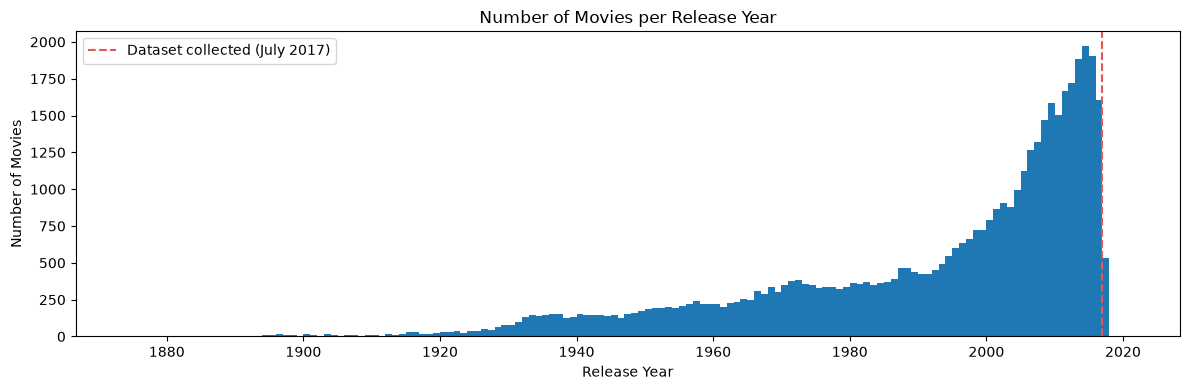

In [ ]:
ax = movies["release_year"].dropna().astype(int).plot(
    kind="hist",
    bins=range(movies["release_year"].min(), movies["release_year"].max() + 2),
    figsize=(12, 4),
    title="Number of Movies per Release Year",
    xlabel="Release Year"
)

line = ax.axvline(SNAPSHOT_DATE.year, color="#E45756", linestyle="--", label="Dataset collected (July 2017)")
ax.set_ylabel("Number of Movies")
ax.legend(handles=[line])
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_movies_per_year.png", bbox_inches="tight")
plt.show()

### 4.2 Number of Movies per Decade

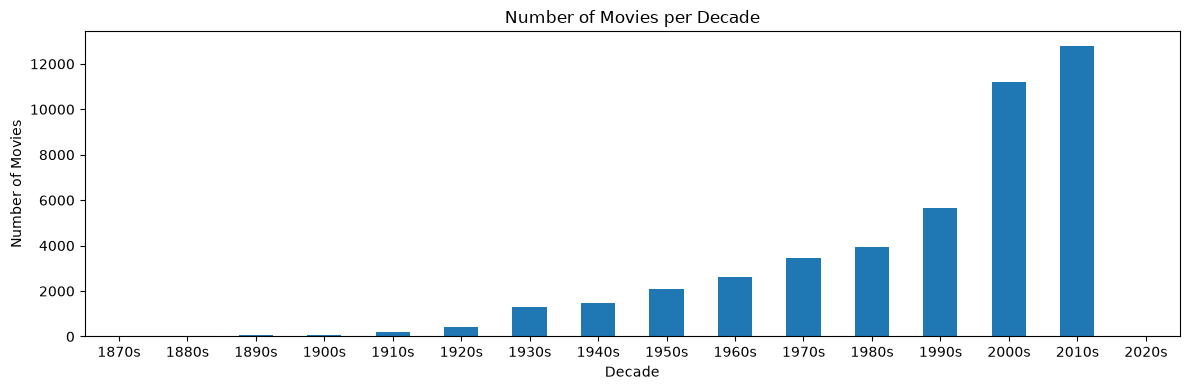

Share of movies released in 2000 or later: 52.9%
87 movies have no release date
40 movies have a release date after the dataset was collected


status
Released           25
Post Production    11
In Production       3
Planned             1
Name: count, dtype: int64

In [ ]:
movies_per_decade = movies["decade"].value_counts().sort_index()
movies_per_decade.index = movies_per_decade.index.map(lambda decade: f"{decade}s")

ax = movies_per_decade.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Movies per Decade",
    xlabel="Decade",
    ylabel="Number of Movies",
    rot=0
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_movies_per_decade.png", bbox_inches="tight")
plt.show()

future_releases = movies[movies["release_date"] >= SNAPSHOT_DATE]
print(f"Share of movies released in 2000 or later: {100 * (movies['release_year'] >= 2000).mean():.1f}%")
print(movies["release_date"].isna().sum(), "movies have no release date")
print(len(future_releases), "movies have a release date after the dataset was collected")
display(future_releases["status"].value_counts(dropna=False))

**Findings:** The number of movies grows steadily over time and more than half of them (52.8 %) were released in 2000 or later. The drop in 2017 is caused by the data collection in July 2017. 87 movies have no release date and 40 are dated after the collection date (25 of them even with status *Released*). These dates should be stored as unknown and excluded from time-based analyses. The decades before 1910 contain fewer than 100 movies, so their statistics are unreliable.

## 5. Distribution of Genres

### 5.1 Number of Movies per Genre

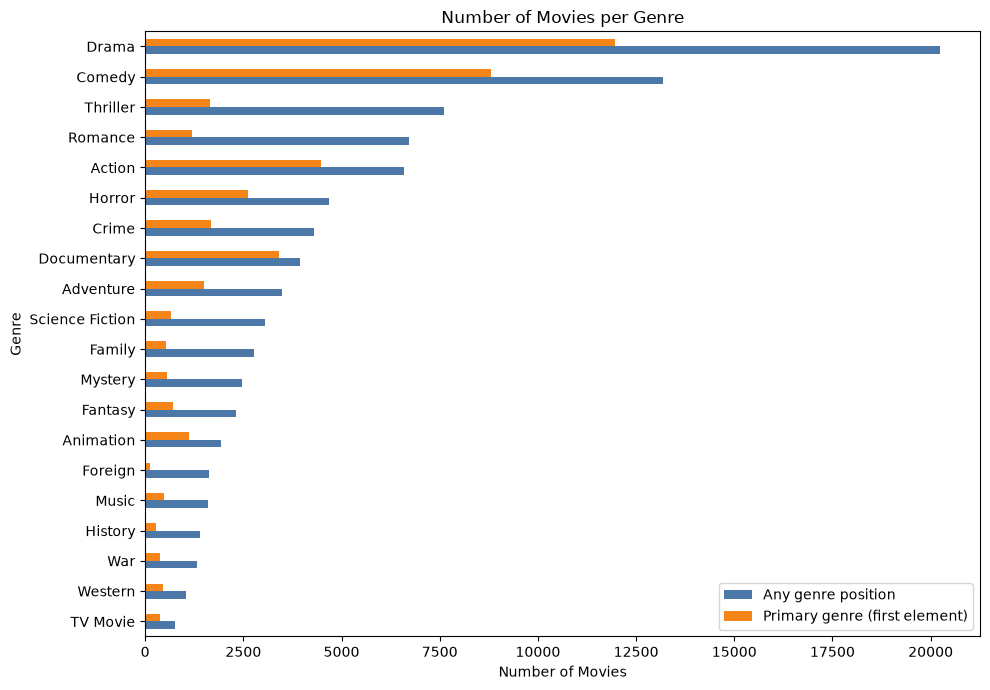

In [ ]:
genre_counts = count_nested_values(movies["genre_names"])
primary_genre_counts = movies["primary_genre"].value_counts().reindex(genre_counts.index, fill_value=0)

genre_comparison = pd.DataFrame({
    "Any genre position": genre_counts,
    "Primary genre (first element)": primary_genre_counts
})

ax = genre_comparison.sort_values("Any genre position").plot(
    kind="barh",
    figsize=(10, 7),
    color=["#4C78A8", "#F58518"],
    title="Number of Movies per Genre",
    ylabel="Genre"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "genre_distribution.png", bbox_inches="tight")
plt.show()

### 5.2 Number of Genres per Movie

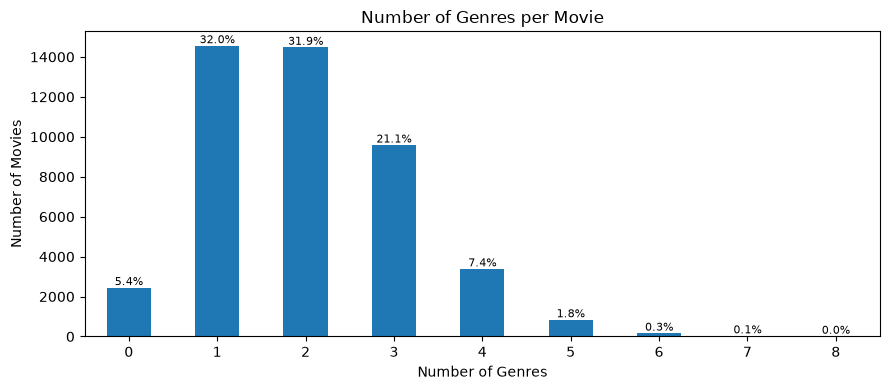

In [ ]:
genres_per_movie = movies["n_genres"].value_counts().sort_index()

ax = genres_per_movie.plot(
    kind="bar",
    figsize=(9, 4),
    title="Number of Genres per Movie",
    xlabel="Number of Genres",
    ylabel="Number of Movies",
    rot=0
)

for patch, value in zip(ax.patches, genres_per_movie):
    ax.annotate(f"{100 * value / len(movies):.1f}%", (patch.get_x() + patch.get_width() / 2, value),
                ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "genres_per_movie_distribution.png", bbox_inches="tight")
plt.show()

**Findings:** Drama (≈ 20,200 movies) and Comedy (≈ 13,200) dominate. Most movies have one to three genres, while 5.4 % have none, so their primary genre is undefined. The first element of `genres` is TMDB's list order and not a ranked "main" genre: Thriller and Romance are frequent genres, but rarely the first one. This should be mentioned as a limitation whenever the first genre is used as the primary genre.

## 6. Distribution of Languages, Countries and Companies

### 6.1 Original Languages

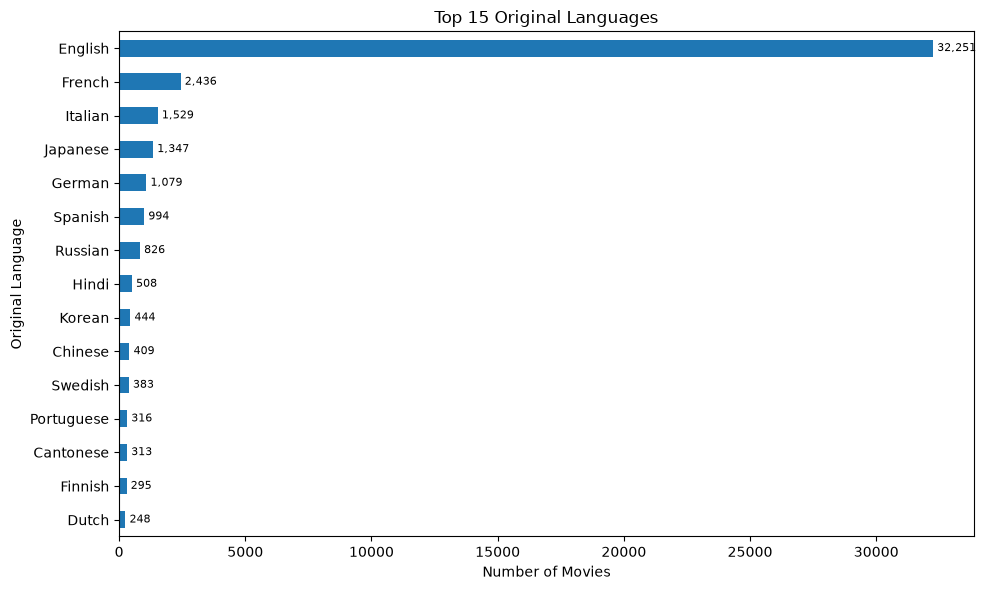

89 distinct original languages
English share: 71.0%


In [ ]:
language_counts = movies["original_language"].value_counts()
top_languages = language_counts.head(TOP_N).rename(index=language_name)

ax = top_languages.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title=f"Top {TOP_N} Original Languages",
    ylabel="Original Language"
)

for patch, value in zip(ax.patches, top_languages.sort_values()):
    ax.annotate(f"{value:,}", (patch.get_width(), patch.get_y() + patch.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "original_language_distribution.png", bbox_inches="tight")
plt.show()

print(f"{movies['original_language'].nunique()} distinct original languages")
print(f"English share: {100 * (movies['original_language'] == 'en').mean():.1f}%")

### 6.2 Production Countries and Companies

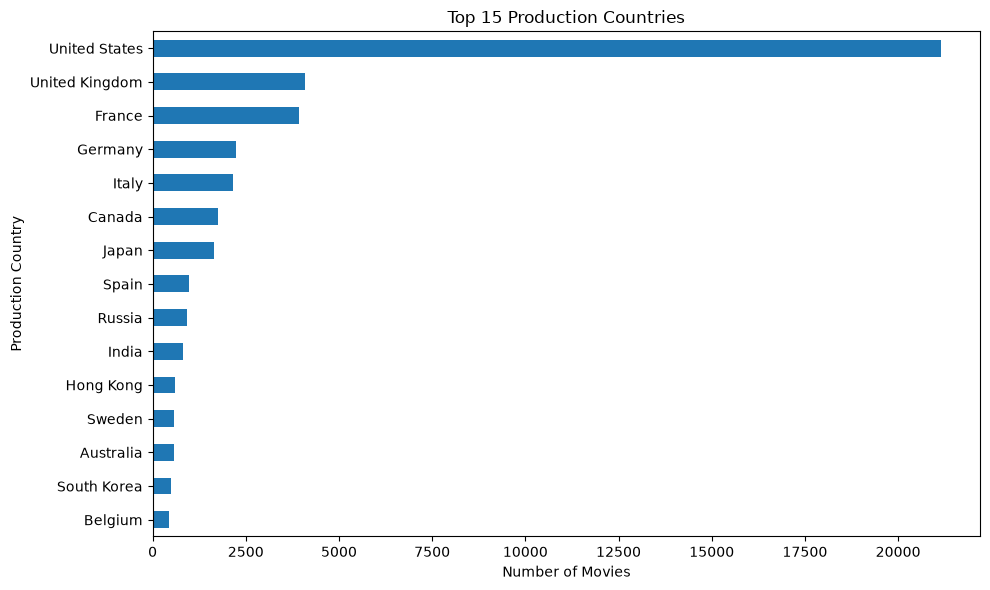

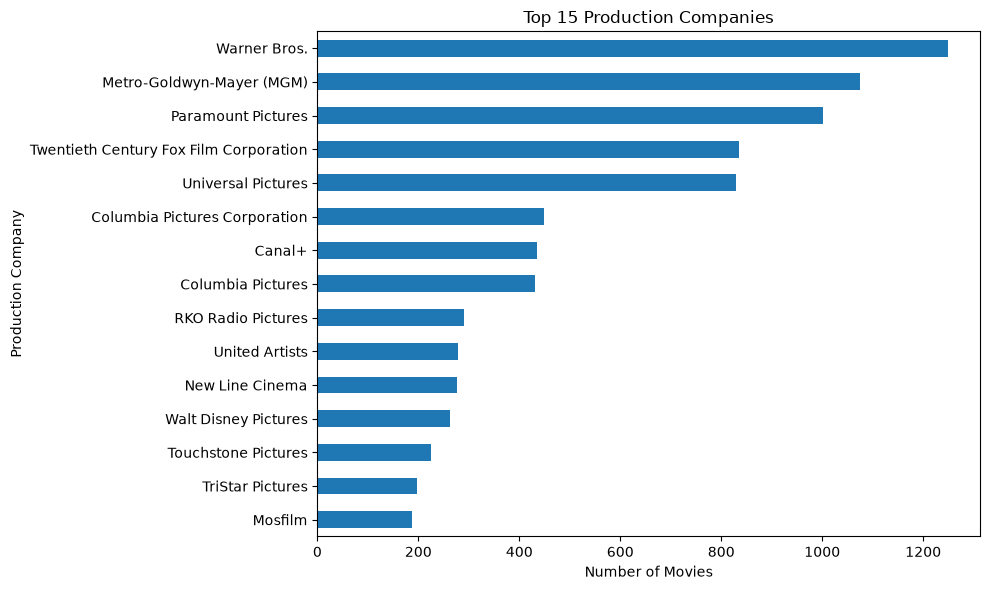

161 distinct production countries, 23,537 distinct production companies
Movies without production country: 6,282
Movies without production company: 11,871
Keys available in production_companies: ['id', 'name']


In [ ]:
country_counts = count_nested_values(movies["country_codes"])
company_counts = count_nested_values(movies["company_names"])

for counts, title, xlabel, file_name in [
    (country_counts.rename(index=country_name), f"Top {TOP_N} Production Countries", "Production Country", "production_country_distribution.png"),
    (company_counts, f"Top {TOP_N} Production Companies", "Production Company", "production_company_distribution.png")
]:
    ax = counts.head(TOP_N).sort_values().plot(
        kind="barh",
        figsize=(10, 6),
        title=title,
        ylabel=xlabel
    )
    ax.set_xlabel("Number of Movies")
    plt.tight_layout()
    plt.savefig(RESULT_FOLDER + file_name, bbox_inches="tight")
    plt.show()

print(f"{len(country_counts)} distinct production countries, {len(company_counts):,} distinct production companies")
print(f"Movies without production country: {(movies['country_codes'].map(len) == 0).sum():,}")
print(f"Movies without production company: {(movies['company_names'].map(len) == 0).sum():,}")
print(f"Keys available in production_companies: {sorted({key for items in movies['production_companies'] for item in items for key in item})}")

**Findings:** 71 % of the movies are originally in English, and the other 88 languages are led by French, Italian, Japanese and German. The US is involved in about 21,000 movies, followed far behind by the UK, France, Germany and Italy, so the dataset is strongly Hollywood-centred. The largest production companies are the classic Hollywood studios (Warner Bros., MGM, Paramount, 20th Century Fox, Universal). The `production_companies` objects only contain `name` and `id`, not a country, so the origin of a company cannot be derived from the data.

## 7. Distribution of Runtime

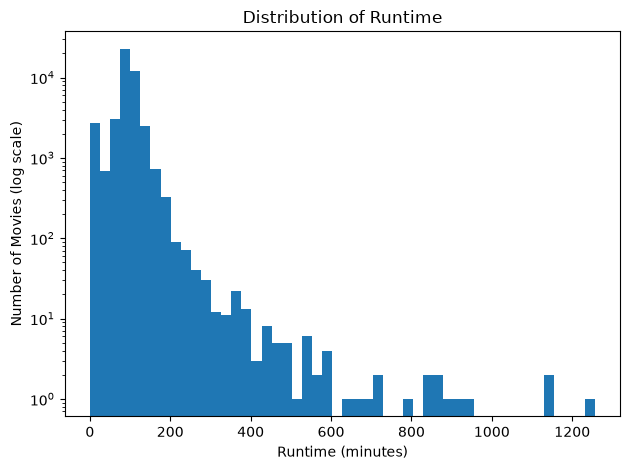

260 movies have no runtime
1558 movies have runtime = 0
108 movies are longer than 300 minutes


In [ ]:
ax = movies["runtime"].plot(
    kind="hist",
    bins=50,
    title="Distribution of Runtime",
    xlabel="Runtime (minutes)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Movies (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "runtime_distribution.png", bbox_inches="tight")
plt.show()

print(movies["runtime"].isna().sum(), "movies have no runtime")
print((movies["runtime"] == 0).sum(), "movies have runtime = 0")
print((movies["runtime"] > MAX_PLAUSIBLE_RUNTIME_MIN).sum(), f"movies are longer than {MAX_PLAUSIBLE_RUNTIME_MIN} minutes")

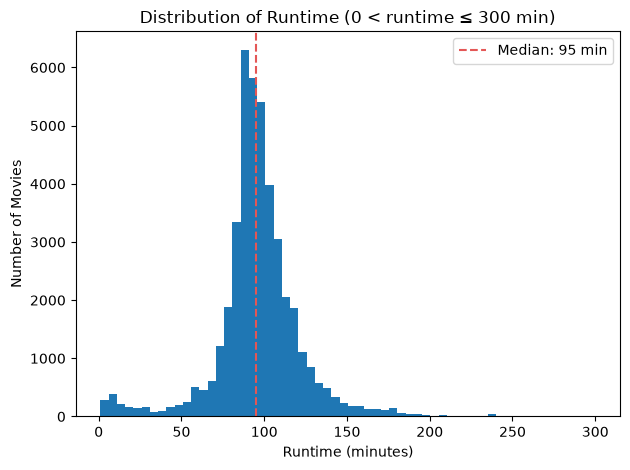

In [ ]:
plausible_runtime = movies["runtime"][(movies["runtime"] > 0) & (movies["runtime"] <= MAX_PLAUSIBLE_RUNTIME_MIN)]

ax = plausible_runtime.plot(
    kind="hist",
    bins=60,
    title=f"Distribution of Runtime (0 < runtime ≤ {MAX_PLAUSIBLE_RUNTIME_MIN} min)",
    xlabel="Runtime (minutes)"
)

line = ax.axvline(plausible_runtime.median(), color="#E45756", linestyle="--", label=f"Median: {plausible_runtime.median():.0f} min")
ax.set_ylabel("Number of Movies")
ax.legend(handles=[line])
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "plausible_runtime_distribution.png", bbox_inches="tight")
plt.show()

**Findings:** The median runtime is 95 minutes. 1,558 movies have a runtime of 0 and 260 have none, which both mean "unknown" and must be excluded from runtime statistics. 108 entries are longer than 300 minutes; these are mini-series and documentary series (e.g. *Centennial*, 1,256 min) rather than feature films. How runtime changed over time is shown in 19.10.

## 8. Distribution of Budget and Revenue

A value of 0 in `budget` or `revenue` means *unknown*, not zero. There are also many tiny values (e.g. a budget of 5) that are placeholders where the amount was entered in millions.

### 8.1 Availability of Budget and Revenue

In [ ]:
money_availability = pd.DataFrame({
    "Budget": money_status(movies["budget"]).value_counts(),
    "Revenue": money_status(movies["revenue"]).value_counts()
}).reindex(["Known", f"Placeholder (< {PLACEHOLDER_MONEY_USD:,} USD)", "0 (unknown)", "Missing"]).fillna(0).astype(int)

ax = money_availability.T.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#54A24B", "#F58518", "#E45756", "#BAB0AC"],
    title="Availability of Budget and Revenue",
    ylabel="Number of Movies",
    rot=0
)

ax.legend(title="Value status")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "budget_revenue_availability.png", bbox_inches="tight")
plt.show()

display(money_availability.assign(**{
    "Budget (%)": 100 * money_availability["Budget"] / len(movies),
    "Revenue (%)": 100 * money_availability["Revenue"] / len(movies)
}).round(2))
print(f"Movies with both budget and revenue known: {(movies['budget_usd'].notna() & movies['revenue_usd'].notna()).sum():,}")

### 8.2 Budget and Revenue Distributions

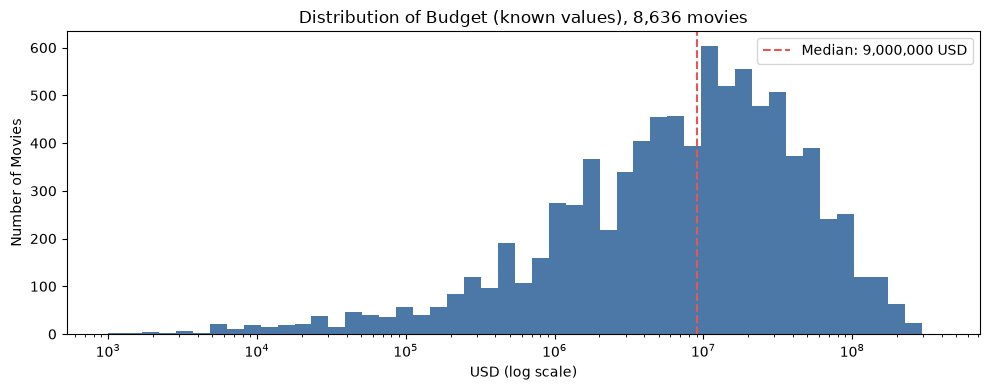

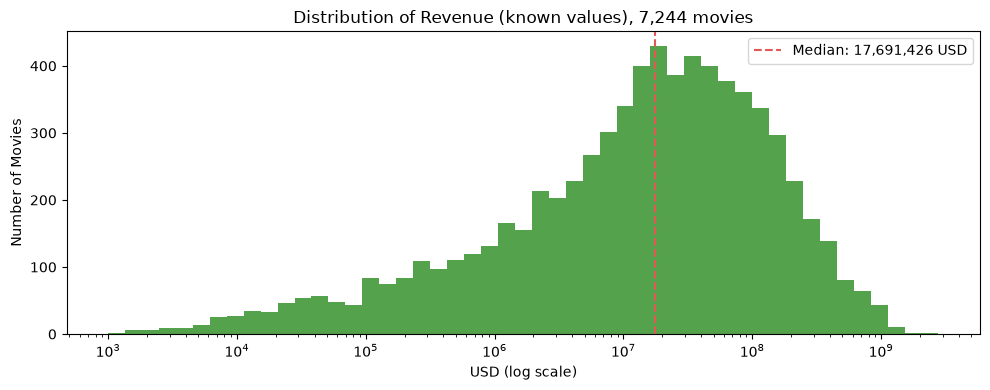

In [ ]:
for column, title, file_name, color in [
    ("budget_usd", "Distribution of Budget (known values)", "budget_distribution.png", "#4C78A8"),
    ("revenue_usd", "Distribution of Revenue (known values)", "revenue_distribution.png", "#54A24B")
]:
    values = movies[column].dropna()
    ax = values.plot(
        kind="hist",
        bins=np.logspace(np.log10(PLACEHOLDER_MONEY_USD), np.log10(values.max()), 50),
        figsize=(10, 4),
        color=color,
        title=f"{title}, {len(values):,} movies"
    )
    ax.set_xscale("log")
    line = ax.axvline(values.median(), color="#E45756", linestyle="--", label=f"Median: {values.median():,.0f} USD")
    ax.set_xlabel("USD (log scale)")
    ax.set_ylabel("Number of Movies")
    ax.legend(handles=[line])
    plt.tight_layout()
    plt.savefig(RESULT_FOLDER + file_name, bbox_inches="tight")
    plt.show()

### 8.3 Budget vs Revenue

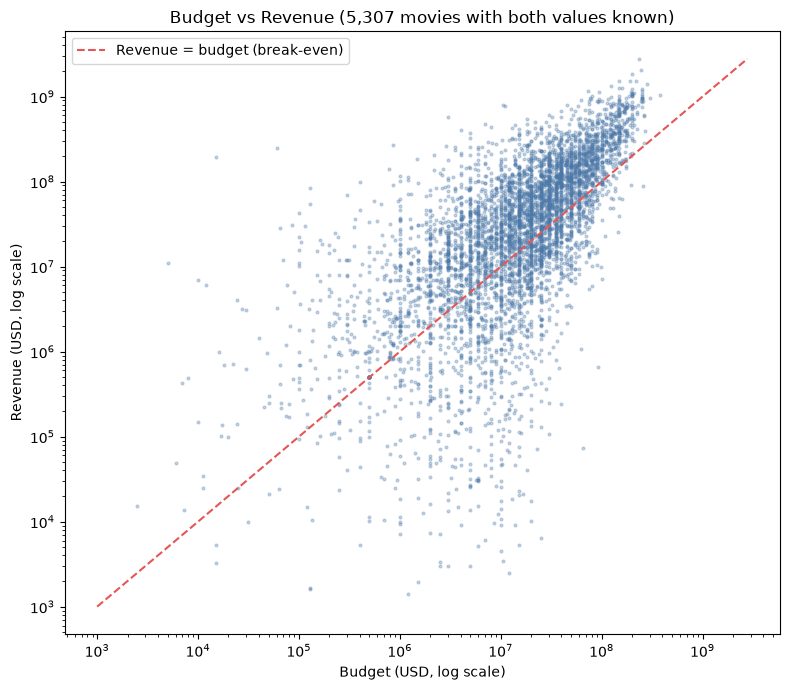

Spearman correlation between budget and revenue: 0.70
Movies with revenue below budget: 29.6%


In [ ]:
known_money = movies.dropna(subset=["budget_usd", "revenue_usd"])

plt.figure(figsize=(8, 7))
plt.scatter(known_money["budget_usd"], known_money["revenue_usd"], s=4, alpha=0.3, color="#4C78A8")
limits = [PLACEHOLDER_MONEY_USD, max(known_money["budget_usd"].max(), known_money["revenue_usd"].max())]
plt.plot(limits, limits, color="#E45756", linestyle="--", label="Revenue = budget (break-even)")
plt.xscale("log")
plt.yscale("log")
plt.title(f"Budget vs Revenue ({len(known_money):,} movies with both values known)")
plt.xlabel("Budget (USD, log scale)")
plt.ylabel("Revenue (USD, log scale)")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "budget_vs_revenue.png", bbox_inches="tight")
plt.show()

print(f"Spearman correlation between budget and revenue: {known_money['budget_usd'].corr(known_money['revenue_usd'], method='spearman'):.2f}")
print(f"Movies with revenue below budget: {(known_money['revenue_usd'] < known_money['budget_usd']).mean() * 100:.1f}%")

**Findings:**

- Only **19 % of the budgets and 16 % of the revenues are known**; a value of 0 means *unknown* and must be stored as missing, otherwise sums and medians are heavily biased towards 0.
- 244 budgets and 154 revenues between 1 and 999 USD are placeholders (e.g. a budget of 8 for *The Prophecy*). They are treated as unknown as well.
- Known budgets (median 9 million USD) and revenues (median 17.7 million USD) are roughly log-normal. Budget and revenue are strongly related (Spearman 0.70), but 29.6 % of the movies with both values earn less than their budget.

## 9. Distribution of Votes

### 9.1 Vote Average

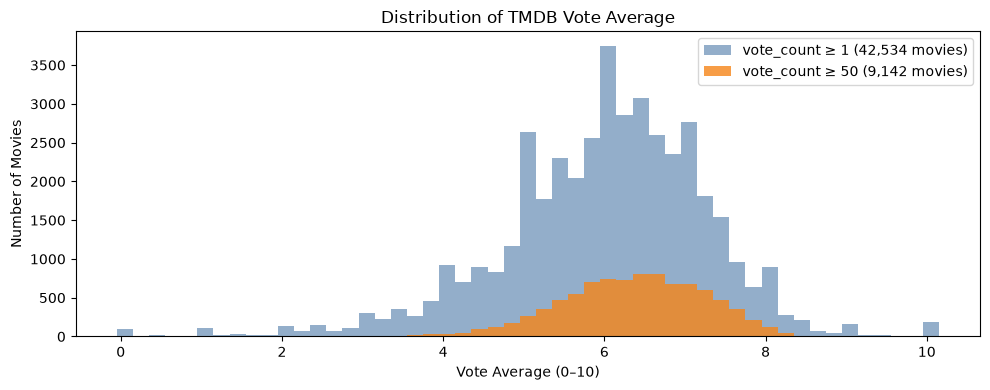

2896 movies have no votes; their vote_average is [0.]


In [ ]:
voted = movies[movies["vote_count"] > 0]

ax = voted["vote_average"].plot(
    kind="hist",
    bins=np.arange(-0.05, 10.2, 0.2),
    figsize=(10, 4),
    alpha=0.6,
    color="#4C78A8",
    label=f"vote_count ≥ 1 ({len(voted):,} movies)",
    title="Distribution of TMDB Vote Average"
)

voted.loc[voted["vote_count"] >= MIN_VOTE_COUNT, "vote_average"].plot(
    kind="hist",
    bins=np.arange(-0.05, 10.2, 0.2),
    alpha=0.8,
    color="#F58518",
    label=f"vote_count ≥ {MIN_VOTE_COUNT} ({(voted['vote_count'] >= MIN_VOTE_COUNT).sum():,} movies)",
    ax=ax
)

ax.set_xlabel("Vote Average (0–10)")
ax.set_ylabel("Number of Movies")
ax.legend()
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "vote_average_distribution.png", bbox_inches="tight")
plt.show()

print((movies["vote_count"] == 0).sum(), "movies have no votes; their vote_average is",
      movies.loc[movies["vote_count"] == 0, "vote_average"].unique())

### 9.2 Vote Count

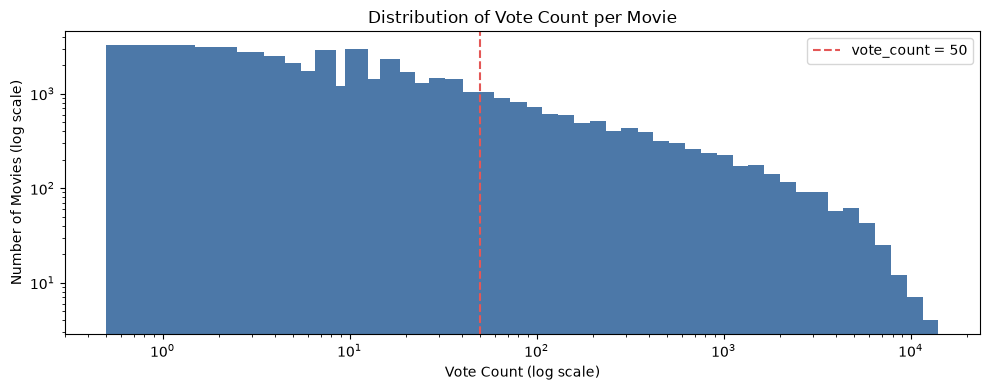

count    42534.0
mean       117.4
std        507.1
min          1.0
25%          4.0
50%         11.0
75%         38.0
90%        178.0
99%       2333.3
max      14075.0
Name: vote_count, dtype: float64

In [ ]:
plot_log_histogram(
    voted["vote_count"],
    title="Distribution of Vote Count per Movie",
    xlabel="Vote Count (log scale)",
    ylabel="Number of Movies (log scale)",
    output_path=RESULT_FOLDER + "vote_count_distribution.png",
    threshold=MIN_VOTE_COUNT,
    threshold_label=f"vote_count = {MIN_VOTE_COUNT}"
)

display(voted["vote_count"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1))

### 9.3 Vote Count vs Vote Average

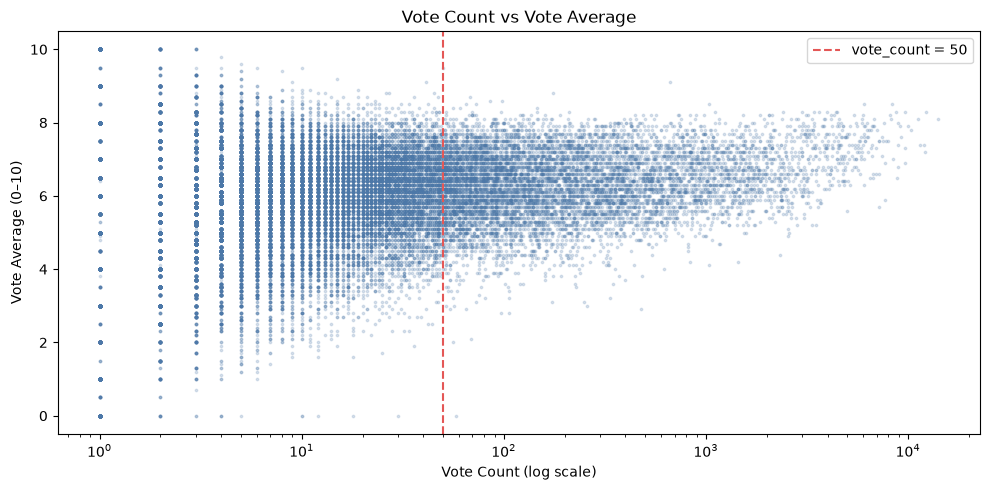

In [ ]:
plt.figure(figsize=(10, 5))
plt.scatter(voted["vote_count"], voted["vote_average"], s=3, alpha=0.2, color="#4C78A8")
plt.axvline(MIN_VOTE_COUNT, color="#E45756", linestyle="--", label=f"vote_count = {MIN_VOTE_COUNT}")
plt.xscale("log")
plt.title("Vote Count vs Vote Average")
plt.xlabel("Vote Count (log scale)")
plt.ylabel("Vote Average (0–10)")
plt.legend()
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "vote_count_vs_vote_average.png", bbox_inches="tight")
plt.show()

**Findings:** 2,896 movies have no votes and their `vote_average` is 0, which is not a real score and should be stored as missing. The vote count is extremely skewed (median 11, 99th percentile ≈ 2,300). Movies with few votes have extreme averages (0 or 10), so vote averages should only be compared for movies with enough votes. This notebook uses `vote_count ≥ 50`, which keeps 9,142 movies.

## 10. Distribution of Release Status

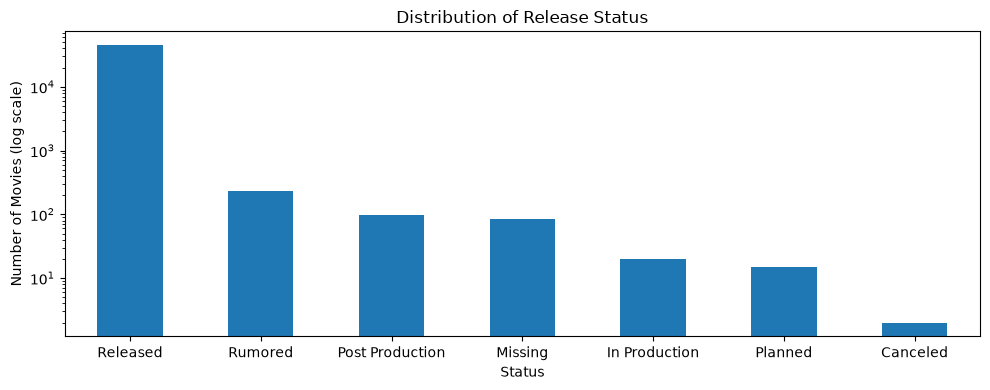

revenue_usd             vote_count       
                      count      median      count median
status                                                   
Canceled                  0         NaN          2    4.0
In Production             0         NaN         20   10.0
Missing                   1     97000.0         81    2.0
Planned                   0         NaN         15   10.0
Post Production           5   1066471.0         98    8.0
Released               7233  17752940.0      44985   10.0
Rumored                   5    273644.0        229    4.0

In [ ]:
status_counts = movies["status"].fillna("Missing").value_counts()

ax = status_counts.plot(
    kind="bar",
    figsize=(10, 4),
    logy=True,
    title="Distribution of Release Status",
    xlabel="Status",
    rot=0
)

ax.set_ylabel("Number of Movies (log scale)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "release_status_distribution.png", bbox_inches="tight")
plt.show()

display(movies.groupby(movies["status"].fillna("Missing"))[["revenue_usd", "vote_count"]].agg(["count", "median"]).round(0))

**Findings:** 99 % of the movies are *Released*. The other statuses (*Rumored*, *Planned*, *In Production*, ...) have few votes and almost never a revenue, but 11 of them still report a revenue, which is inconsistent.

## 11. Distribution of Collections

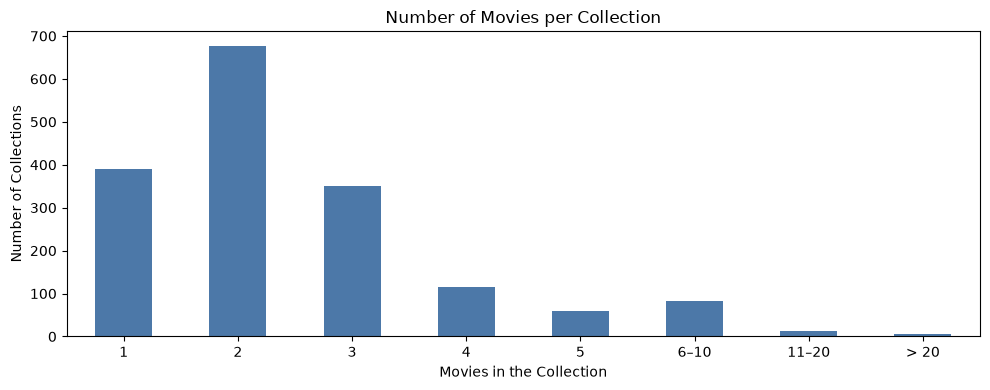

Movies in a collection: 4,488 (9.9%)
Distinct collections: 1,695


collection_name
The Bowery Boys                           29
Totò Collection                           27
James Bond Collection                     26
Zatôichi: The Blind Swordsman             26
The Carry On Collection                   25
Charlie Chan (Sidney Toler) Collection    21
Pokémon Collection                        20
Godzilla (Showa) Collection               16
Uuno Turhapuro                            15
Charlie Chan (Warner Oland) Collection    15
Name: count, dtype: int64

In [ ]:
collection_sizes = movies["collection_name"].value_counts()

collection_size_bins = [0, 1, 2, 3, 4, 5, 10, 20, np.inf]
collection_size_labels = ["1", "2", "3", "4", "5", "6–10", "11–20", "> 20"]
collection_size_groups = (
    pd.cut(collection_sizes, bins=collection_size_bins, labels=collection_size_labels)
    .value_counts(sort=False)
)

ax = collection_size_groups.plot(
    kind="bar",
    figsize=(10, 4),
    color="#4C78A8",
    title="Number of Movies per Collection",
    xlabel="Movies in the Collection",
    ylabel="Number of Collections",
    rot=0
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "collection_size_distribution.png", bbox_inches="tight")
plt.show()

print(f"Movies in a collection: {movies['collection_name'].notna().sum():,} ({100 * movies['collection_name'].notna().mean():.1f}%)")
print(f"Distinct collections: {len(collection_sizes):,}")
display(collection_sizes.head(10))

**Findings:** 9.9 % of the movies belong to one of 1,695 collections. Most collections are small (two movies are the most common size, typically a movie and its sequel), and only a few have more than ten. The largest collections are long-running older series (*The Bowery Boys*, *Totò*, *James Bond*), where revenue is often unknown, so any total revenue of a collection is a lower bound.

## 12. Availability of Text Fields

`overview` and `tagline` are the only free-text fields. How complete they are determines what text-based exploration and search can find.

In [ ]:
placeholder_overviews = movies["overview"].str.strip().str.lower().isin(
    ["no overview found.", "no overview", "no movie overview available.", ""]
)

text_availability = pd.DataFrame({
    "Missing": [movies["overview"].isna().sum(), movies["tagline"].isna().sum()],
    "Placeholder text": [placeholder_overviews.sum(), 0],
    "Available": [
        (movies["overview"].notna() & ~placeholder_overviews).sum(),
        movies["tagline"].notna().sum()
    ]
}, index=["overview", "tagline"])

display(text_availability.assign(**{"Available (%)": 100 * text_availability["Available"] / len(movies)}).round(1))

overview_words = movies["overview"].dropna().str.split().map(len)
print(f"Median overview length: {overview_words.median():.0f} words")

,Missing,Placeholder text,Available,Available (%)
overview,954,149,44330,97.6
tagline,25032,0,20401,44.9


Median overview length: 48 words


**Findings:** An overview exists for 97.6 % of the movies (149 of them are placeholders like "No overview found."), but a tagline only for 44.9 %. Overviews are short summaries, so a text search over them finds only movies whose theme is explicitly mentioned. For the same reason, keywords are often a more reliable thematic label than the free text.

## 13. Distribution of Cast and Crew

### 13.1 Cast and Crew Size

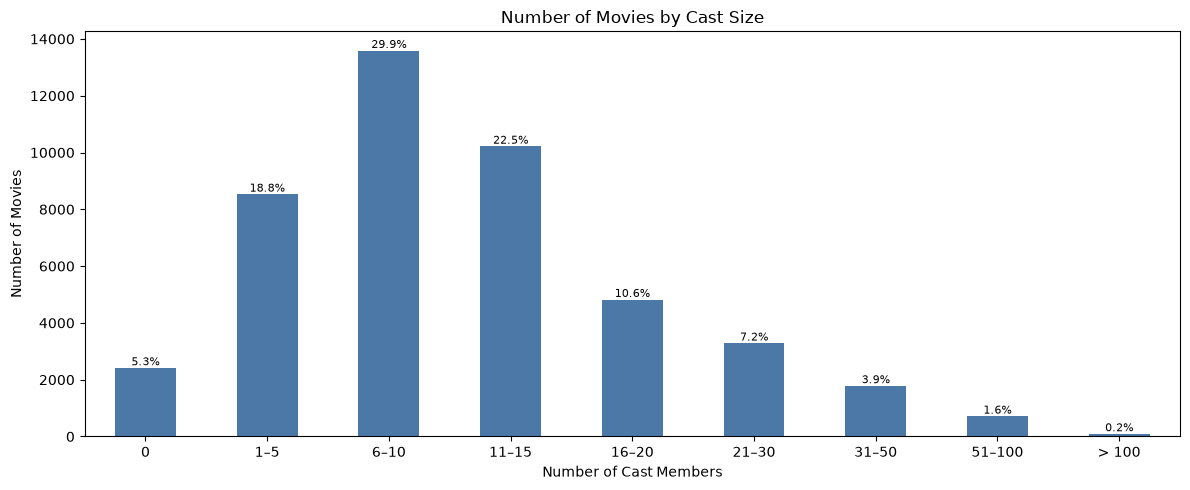

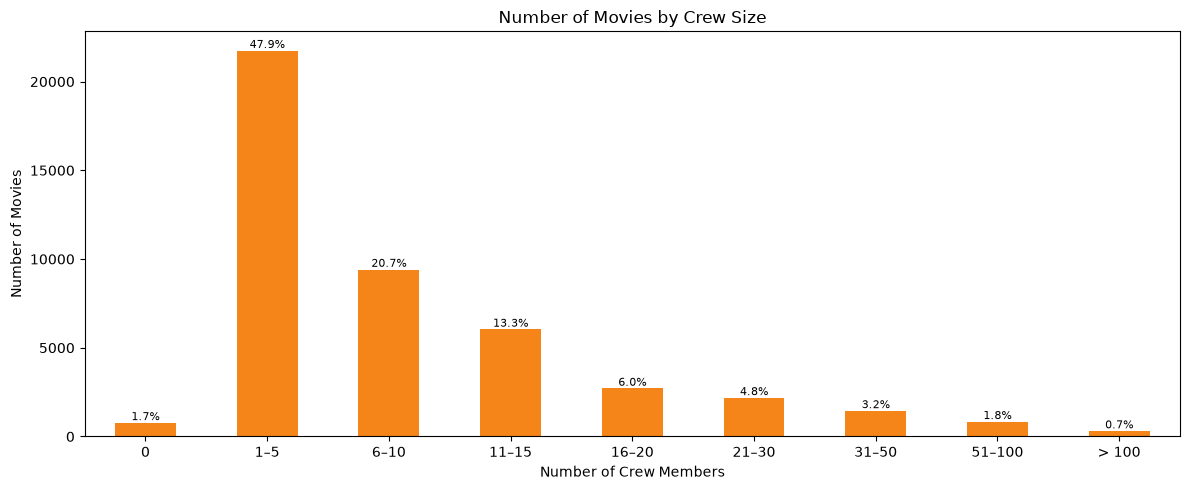

,n_cast,n_actors,n_crew,n_directors
count,45432.0,45432.0,45432.0,45432.0
mean,12.4,12.3,10.2,1.1
std,12.1,12.1,15.8,0.6
min,0.0,0.0,0.0,0.0
25%,6.0,6.0,2.0,1.0
50%,10.0,10.0,6.0,1.0
75%,15.0,15.0,12.0,1.0
max,313.0,312.0,435.0,42.0


2414 movies have no cast, 771 movies have no crew


In [ ]:
size_bins = [-1, 0, 5, 10, 15, 20, 30, 50, 100, np.inf]
size_labels = ["0", "1–5", "6–10", "11–15", "16–20", "21–30", "31–50", "51–100", "> 100"]

for column, title, xlabel, file_name, color in [
    ("n_cast", "Number of Movies by Cast Size", "Number of Cast Members", "cast_size_distribution.png", "#4C78A8"),
    ("n_crew", "Number of Movies by Crew Size", "Number of Crew Members", "crew_size_distribution.png", "#F58518")
]:
    plot_share_bar_chart(
        credits[column],
        bins=size_bins,
        labels=size_labels,
        title=title,
        xlabel=xlabel,
        ylabel="Number of Movies",
        output_path=RESULT_FOLDER + file_name,
        color=color
    )

display(credits[["n_cast", "n_actors", "n_crew", "n_directors"]].describe().round(1))
print((credits["n_cast"] == 0).sum(), "movies have no cast,", (credits["n_crew"] == 0).sum(), "movies have no crew")

**Findings:** Most movies list 6–15 cast members and 1–10 crew members, with a long tail up to 313 and 435. The crew is often incomplete (48 % of the movies list at most five crew members). 2,414 movies have no cast and 771 no crew, so they cannot contribute to analyses of actors or directors.

### 13.2 Gender

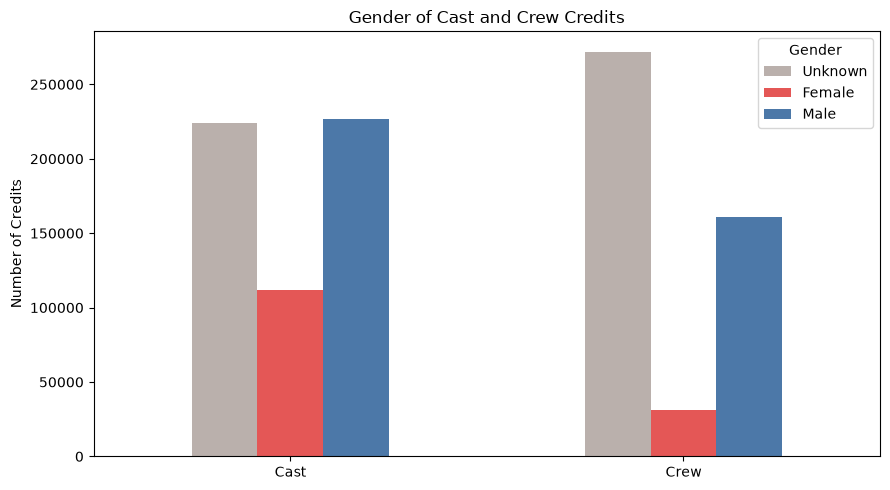

,Cast (%),Crew (%)
gender,,
Unknown,39.8,58.6
Female,19.9,6.7
Male,40.3,34.6


In [ ]:
gender_counts = pd.DataFrame({
    "Cast": cast_members["gender"].map(GENDER_NAMES).value_counts(),
    "Crew": crew_members["gender"].map(GENDER_NAMES).value_counts()
}).reindex(list(GENDER_NAMES.values()))

ax = gender_counts.T.plot(
    kind="bar",
    figsize=(9, 5),
    color=GENDER_COLORS,
    title="Gender of Cast and Crew Credits",
    ylabel="Number of Credits",
    rot=0
)

ax.legend(title="Gender")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "gender_distribution.png", bbox_inches="tight")
plt.show()

display((100 * gender_counts / gender_counts.sum()).round(1).rename(columns=lambda name: f"{name} (%)"))

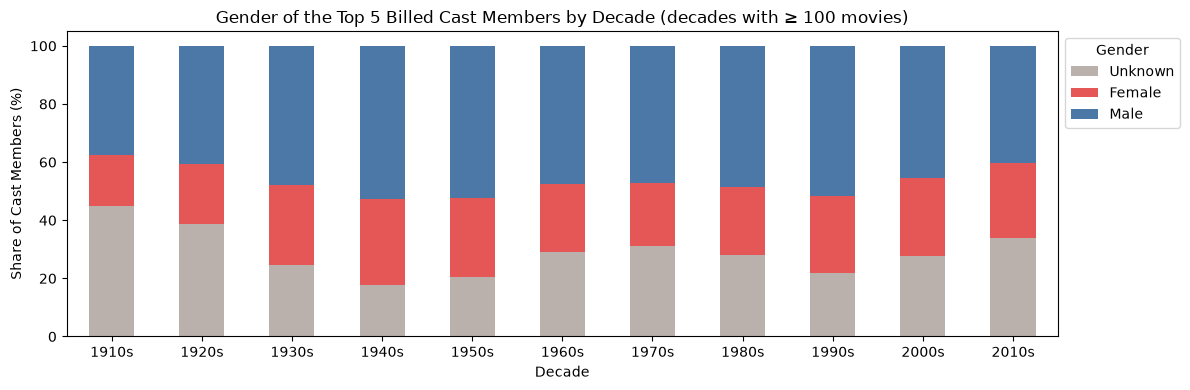

Movies where the cast order does not start at 0: 6,314


In [ ]:
top_billed = (
    pd.DataFrame(
        [
            {"id": movie_id, "gender": member.get("gender", 0)}
            for movie_id, cast in zip(credits["id"], credits["cast"])
            for member in top_billed_cast(cast, TOP_BILLED_CAST)
        ]
    )
    .merge(movies[["id", "decade"]], on="id", how="inner")
    .dropna(subset=["decade"])
)

movies_per_decade_with_cast = top_billed.groupby("decade")["id"].nunique()
top_billed = top_billed[top_billed["decade"].map(movies_per_decade_with_cast) >= MIN_MOVIES_PER_DECADE]

top_billed_gender_by_decade = (
    pd.crosstab(top_billed["decade"].astype(int), top_billed["gender"].map(GENDER_NAMES), normalize="index")
    .reindex(columns=list(GENDER_NAMES.values()), fill_value=0)
    * 100
)
top_billed_gender_by_decade.index = top_billed_gender_by_decade.index.map(lambda decade: f"{decade}s")

ax = top_billed_gender_by_decade.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 4),
    color=GENDER_COLORS,
    title=f"Gender of the Top {TOP_BILLED_CAST} Billed Cast Members by Decade (decades with ≥ {MIN_MOVIES_PER_DECADE} movies)",
    xlabel="Decade",
    ylabel="Share of Cast Members (%)",
    rot=0
)

ax.legend(title="Gender", loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "top_billed_gender_by_decade.png", bbox_inches="tight")
plt.show()

movies_not_starting_at_zero = sum(1 for cast in credits["cast"] if cast and min(member["order"] for member in cast) != 0)
print(f"Movies where the cast order does not start at 0: {movies_not_starting_at_zero:,}")

**Findings:** The gender is unknown (`0`) for 40 % of the cast credits and 59 % of the crew credits, and only 20 % of the cast credits are female. Among the top-billed cast, a substantial share (roughly 15–45 %) is unknown in every decade. Gender shares should therefore be computed over known genders only, and the amount of unknown data reported with them. In 6,314 movies the billing `order` does not start at 0, so the top-billed cast must be found by sorting on `order` rather than by filtering `order < 5`.

### 13.3 Crew Departments and Jobs

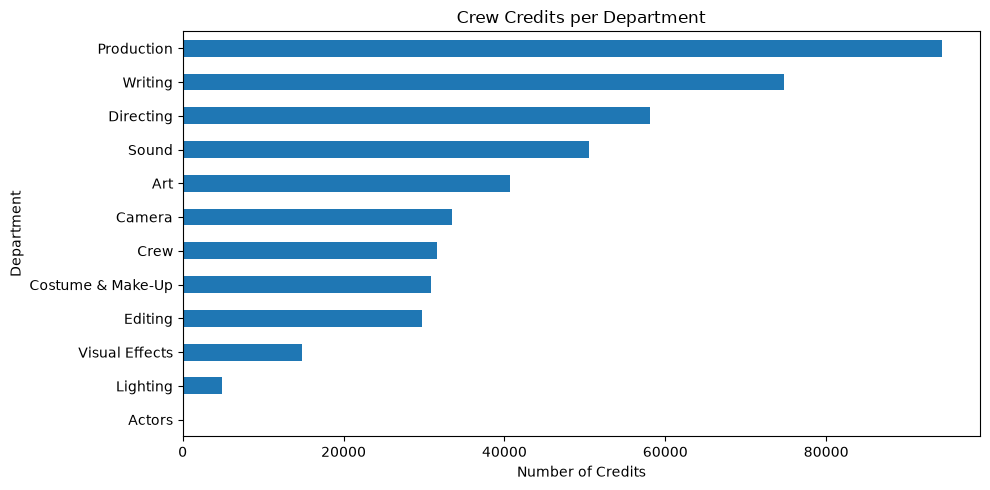

job
Director                   48999
Producer                   43507
Writer                     30398
Screenplay                 25143
Editor                     23770
Director of Photography    20640
Executive Producer         18853
Original Music Composer    15773
Casting                    12620
Art Direction              11679
Name: count, dtype: int64

In [ ]:
ax = crew_members["department"].value_counts().sort_values().plot(
    kind="barh",
    figsize=(10, 5),
    title="Crew Credits per Department",
    ylabel="Department"
)

ax.set_xlabel("Number of Credits")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "crew_department_distribution.png", bbox_inches="tight")
plt.show()

display(crew_members["job"].value_counts().head(10))

**Findings:** Most crew credits belong to Production, Writing and Directing. `Director` is the most common job with about 49,000 credits. Since the crew of many movies is incomplete, the presence of a job says more than the size of the crew.

## 14. Number of Movies per Director

In [ ]:
movies_per_director = directors.groupby("id")["movie_id"].nunique()

movie_count_bins = [0, 1, 2, 3, 4, 5, 10, 20, 50, np.inf]
movie_count_labels = ["1", "2", "3", "4", "5", "6–10", "11–20", "21–50", "> 50"]

plot_share_bar_chart(
    movies_per_director,
    bins=movie_count_bins,
    labels=movie_count_labels,
    title="Number of Directors by Number of Movies Directed",
    xlabel="Number of Movies",
    ylabel="Number of Directors",
    output_path=RESULT_FOLDER + "movies_per_director_distribution.png"
)

print(f"Distinct directors: {len(movies_per_director):,}")
print(f"Mean movies per director: {movies_per_director.mean():.2f}")
print(f"Movies with more than one director: {(credits['n_directors'] > 1).sum():,}")
print(f"Movies without a director: {(credits['n_directors'] == 0).sum():,}")

director_names_per_id = directors.groupby("name")["id"].nunique()
print(f"Director names shared by more than one person id: {(director_names_per_id > 1).sum():,}")

**Findings:** 62.3 % of the 19,895 directors have only one movie in the dataset (2.46 movies on average), and fewer than 1 % have more than 20. 3,195 movies have several directors and 887 have none. 148 director names belong to more than one person, so directors must be grouped by `id` and not by `name`.

## 15. Number of Movies per Actor

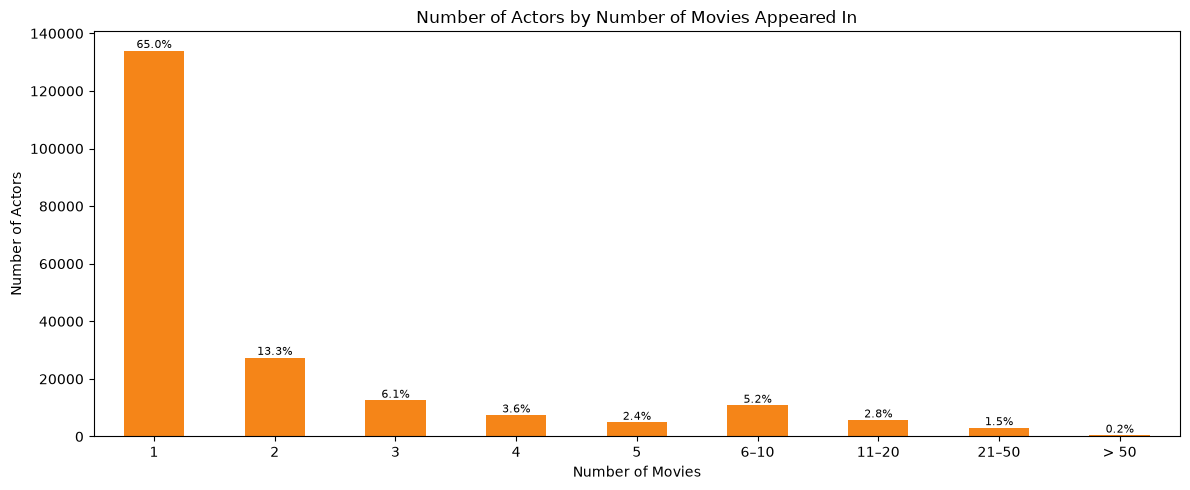

Distinct actors: 206,158
Mean movies per actor: 2.72


Actor names shared by more than one person id: 3,053
Repeated (movie, actor) credits, e.g. one actor playing several characters: 1,207


In [ ]:
movies_per_actor = cast_members.groupby("id")["movie_id"].nunique()

plot_share_bar_chart(
    movies_per_actor,
    bins=movie_count_bins,
    labels=movie_count_labels,
    title="Number of Actors by Number of Movies Appeared In",
    xlabel="Number of Movies",
    ylabel="Number of Actors",
    output_path=RESULT_FOLDER + "movies_per_actor_distribution.png",
    color="#F58518"
)

print(f"Distinct actors: {len(movies_per_actor):,}")
print(f"Mean movies per actor: {movies_per_actor.mean():.2f}")
print(f"Actor names shared by more than one person id: {(cast_members.groupby('name')['id'].nunique() > 1).sum():,}")
print(f"Repeated (movie, actor) credits, e.g. one actor playing several characters: "
      f"{cast_members.duplicated(['movie_id', 'id']).sum():,}")

In [ ]:
top_actors = movies_per_actor.sort_values(ascending=False).head(TOP_N)
top_actors.index = top_actors.index.map(person_names)

ax = top_actors.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title=f"Top {TOP_N} Actors by Number of Movies",
    ylabel="Actor"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "most_frequent_actors.png", bbox_inches="tight")
plt.show()

**Findings:** 65 % of the 206,158 actors appear in only one movie (2.72 movies on average). The most frequent "actors" are prolific supporting players from the studio era (Bess Flowers, an uncredited extra in hundreds of films). 3,053 actor names are shared by several people, and an actor is credited more than once in the same movie 1,207 times (several roles). Counting appearances or collaborations therefore requires **distinct person ids per movie**.

## 16. Distribution of Keywords

### 16.1 Number of Keywords per Movie

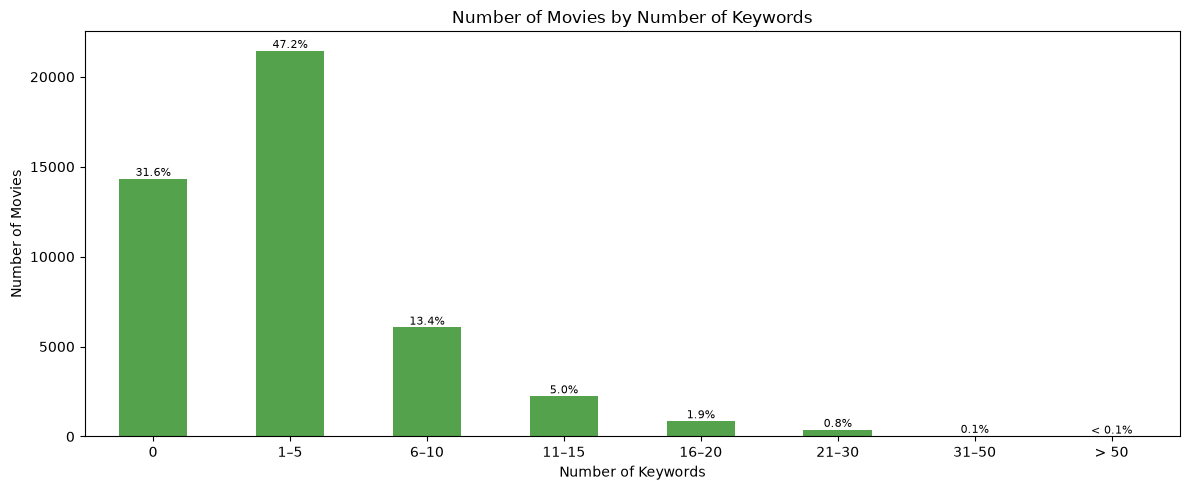

Movies without keywords: 14,340 (31.6%)


In [ ]:
plot_share_bar_chart(
    keywords["n_keywords"],
    bins=[-1, 0, 5, 10, 15, 20, 30, 50, np.inf],
    labels=["0", "1–5", "6–10", "11–15", "16–20", "21–30", "31–50", "> 50"],
    title="Number of Movies by Number of Keywords",
    xlabel="Number of Keywords",
    ylabel="Number of Movies",
    output_path=RESULT_FOLDER + "keywords_per_movie_distribution.png",
    color="#54A24B"
)

print(f"Movies without keywords: {(keywords['n_keywords'] == 0).sum():,} ({100 * (keywords['n_keywords'] == 0).mean():.1f}%)")

### 16.2 Most Common Keywords

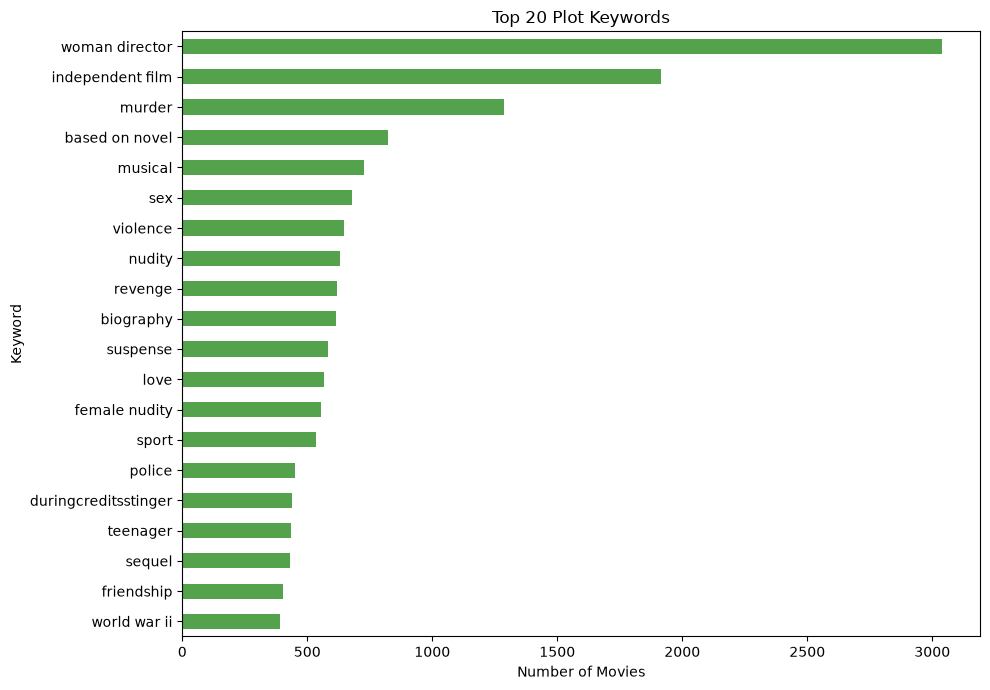

Distinct keywords: 19,956


In [ ]:
keyword_counts = count_nested_values(keywords["keywords"].map(lambda items: extract_field(items, "name")))

ax = keyword_counts.head(20).sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    color="#54A24B",
    title="Top 20 Plot Keywords",
    ylabel="Keyword"
)

ax.set_xlabel("Number of Movies")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "most_common_keywords.png", bbox_inches="tight")
plt.show()

print(f"Distinct keywords: {len(keyword_counts):,}")

**Findings:** 31.6 % of the movies have no keywords, and most of the others have between 1 and 15. The most common keywords describe production context ("woman director", "independent film", "based on novel") rather than the plot, followed by broad themes such as murder, revenge, love and violence. Section 19.11 shows how keywords change over time.

## 17. Distribution of Ratings

### 17.1 Rating Values

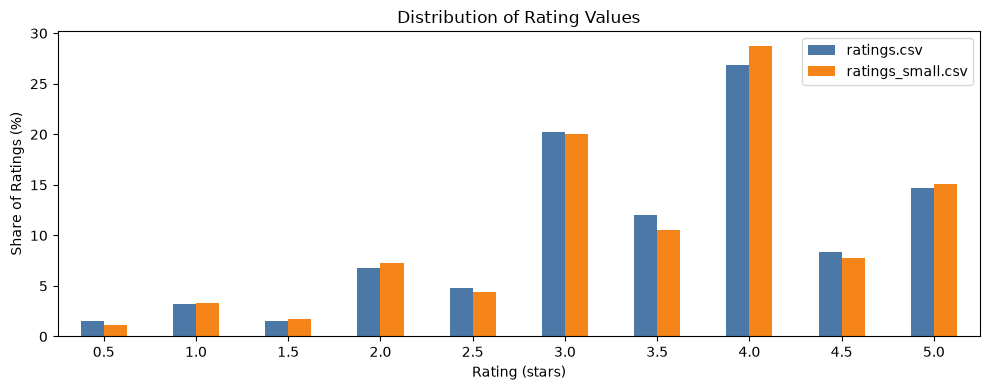

Mean rating: 3.53 (full), 3.54 (small)


Share of whole-star ratings: 71.8%


In [ ]:
rating_shares = pd.DataFrame({
    "ratings.csv": ratings_df["rating"].value_counts(normalize=True),
    "ratings_small.csv": ratings_small_df["rating"].value_counts(normalize=True)
}).sort_index() * 100

ax = rating_shares.plot(
    kind="bar",
    figsize=(10, 4),
    color=["#4C78A8", "#F58518"],
    title="Distribution of Rating Values",
    xlabel="Rating (stars)",
    ylabel="Share of Ratings (%)",
    rot=0
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "rating_value_distribution.png", bbox_inches="tight")
plt.show()

print(f"Mean rating: {ratings_df['rating'].mean():.2f} (full), {ratings_small_df['rating'].mean():.2f} (small)")
print(f"Share of whole-star ratings: {100 * (ratings_df['rating'] % 1 == 0).mean():.1f}%")

**Findings:** Users prefer whole stars (71.8 % of the ratings) and the distribution is skewed towards positive ratings (mean 3.53, mode 4.0). `ratings_small.csv` has almost the same distribution, so it is representative enough for development.

### 17.2 Ratings over Time

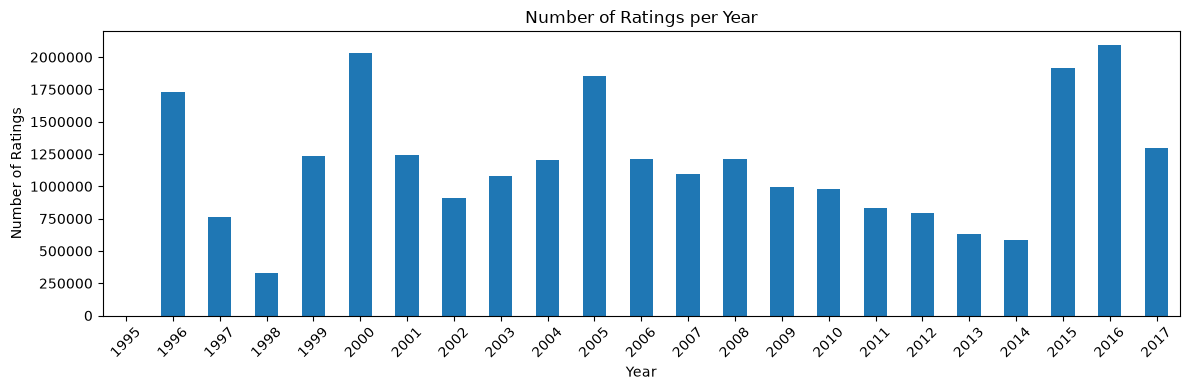

First rating: 1995-01-09 11:46:44 | Last rating: 2017-08-04 06:57:50


In [ ]:
ratings_per_year = ratings_df["datetime"].dt.year.value_counts().sort_index()

ax = ratings_per_year.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Ratings per Year",
    xlabel="Year",
    ylabel="Number of Ratings",
    rot=45
)

ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "number_of_ratings_per_year.png", bbox_inches="tight")
plt.show()

print("First rating:", ratings_df["datetime"].min(), "| Last rating:", ratings_df["datetime"].max())

**Findings:** The ratings span January 1995 to August 2017 with peaks in 1996, 2000 and 2015–2016. The timestamps are Unix seconds and should be stored as dates.

### 17.3 Ratings per User and per Movie

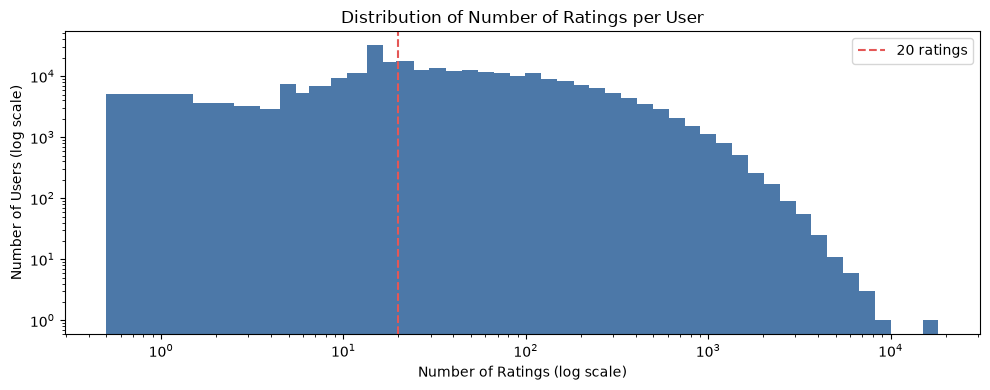

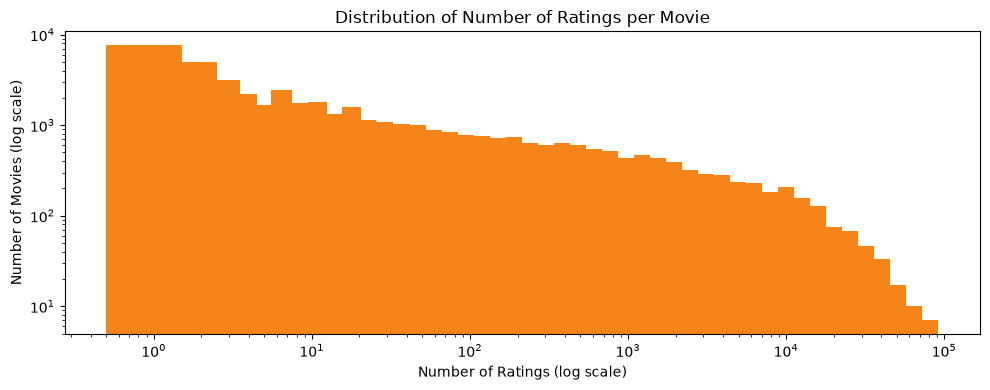

,Ratings per user,Ratings per movie
count,270896.0,45115.0
mean,96.1,576.8
std,205.7,3037.4
min,1.0,1.0
50%,30.0,8.0
90%,236.0,695.0
99%,963.0,12846.9
max,18276.0,91921.0


Users with ≥ 20 ratings: 166,444 of 270,896
Share of all ratings given by the top 1% most active users: 15.5%


In [ ]:
ratings_per_user = ratings_df.groupby("userId").size()
ratings_per_movie = ratings_df.groupby("movieId").size()

plot_log_histogram(
    ratings_per_user,
    title="Distribution of Number of Ratings per User",
    xlabel="Number of Ratings (log scale)",
    ylabel="Number of Users (log scale)",
    output_path=RESULT_FOLDER + "ratings_per_user_distribution.png",
    threshold=MIN_USER_RATINGS,
    threshold_label=f"{MIN_USER_RATINGS} ratings"
)

plot_log_histogram(
    ratings_per_movie,
    title="Distribution of Number of Ratings per Movie",
    xlabel="Number of Ratings (log scale)",
    ylabel="Number of Movies (log scale)",
    output_path=RESULT_FOLDER + "ratings_per_movie_distribution.png",
    color="#F58518"
)

top_user_share = ratings_per_user.sort_values(ascending=False).head(len(ratings_per_user) // 100).sum() / len(ratings_df)
display(pd.DataFrame({
    "Ratings per user": ratings_per_user.describe(percentiles=[0.5, 0.9, 0.99]),
    "Ratings per movie": ratings_per_movie.describe(percentiles=[0.5, 0.9, 0.99])
}).round(1))
print(f"Users with ≥ {MIN_USER_RATINGS} ratings: {(ratings_per_user >= MIN_USER_RATINGS).sum():,} of {len(ratings_per_user):,}")
print(f"Share of all ratings given by the top 1% most active users: {100 * top_user_share:.1f}%")

**Findings:** A user has a median of 30 ratings, but the distribution is very long-tailed (one user has 18,276 ratings), and the top 1 % of users give 15.5 % of all ratings. 166,444 users have at least 20 ratings. Most movies have few ratings (median 8), while popular movies have up to 91,921.

### 17.4 User Rating Variance and Genre Breadth

To see how differently users rate and how broad their taste is, every movie's genres are encoded as a 20-bit mask. The mask of each rating is looked up through `links.csv` and OR-ed per user, so the number of set bits is the number of distinct genres the user has rated, computed without exploding the 26 million ratings. The variance is only shown for users with at least 20 ratings, since it is unreliable for fewer.

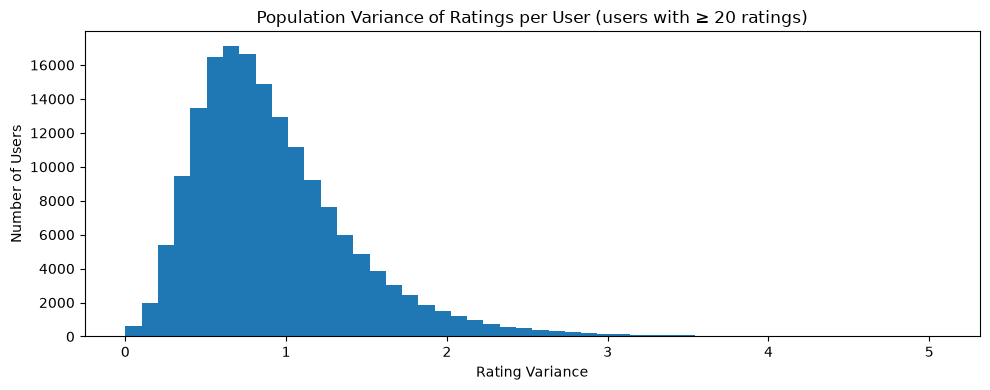

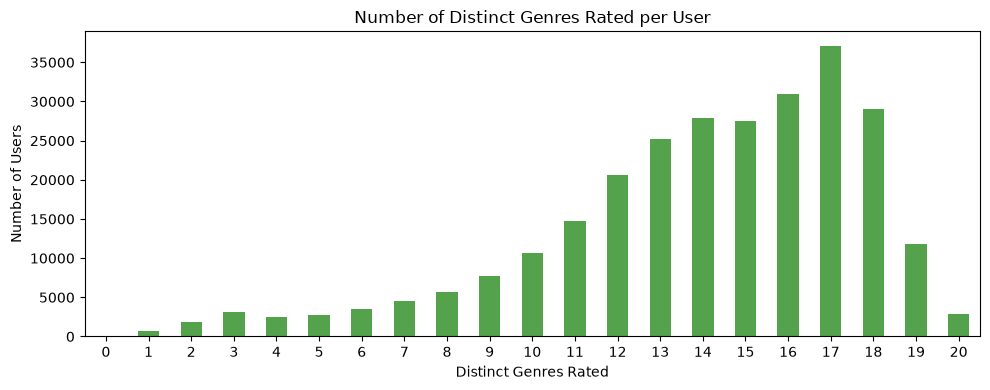

Users with zero variance (always the same rating) among active users: 196
Users who rated all 20 genres: 2,896


In [ ]:
genre_bits = {genre: 1 << position for position, genre in enumerate(sorted(genre_counts.index))}

genre_mask_by_tmdb = movies.set_index("id")["genre_names"].map(
    lambda names: sum(genre_bits[name] for name in set(names))
)
genre_mask_by_movie_id = (
    links_df.dropna(subset=["tmdbId"])
    .assign(tmdbId=lambda data: data["tmdbId"].astype(int))
    .drop_duplicates("movieId")
    .set_index("movieId")["tmdbId"]
    .map(genre_mask_by_tmdb)
    .fillna(0)
    .astype(np.int64)
)

rating_masks = ratings_df["movieId"].map(genre_mask_by_movie_id).fillna(0).astype(np.int64).to_numpy()
user_ids = ratings_df["userId"].to_numpy()
user_starts = np.flatnonzero(np.r_[True, user_ids[1:] != user_ids[:-1]])  # ratings.csv is sorted by userId

user_stats = pd.DataFrame({
    "ratings": ratings_per_user,
    "variance": ratings_df.groupby("userId")["rating"].var(ddof=0),
    "distinct_genres": pd.Series(
        np.bitwise_count(np.bitwise_or.reduceat(rating_masks, user_starts)),
        index=user_ids[user_starts]
    )
})
active_users = user_stats[user_stats["ratings"] >= MIN_USER_RATINGS]

ax = active_users["variance"].plot(
    kind="hist",
    bins=50,
    figsize=(10, 4),
    title=f"Population Variance of Ratings per User (users with ≥ {MIN_USER_RATINGS} ratings)",
    xlabel="Rating Variance"
)

ax.set_ylabel("Number of Users")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "user_rating_variance_distribution.png", bbox_inches="tight")
plt.show()

distinct_genre_counts = user_stats["distinct_genres"].value_counts().sort_index()
ax = distinct_genre_counts.plot(
    kind="bar",
    figsize=(10, 4),
    color="#54A24B",
    title="Number of Distinct Genres Rated per User",
    xlabel="Distinct Genres Rated",
    rot=0
)

ax.set_ylabel("Number of Users")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "user_genre_breadth_distribution.png", bbox_inches="tight")
plt.show()

print(f"Users with zero variance (always the same rating) among active users: {(active_users['variance'] == 0).sum():,}")
print(f"Users who rated all {len(genre_bits)} genres: {(user_stats['distinct_genres'] == len(genre_bits)).sum():,}")

**Findings:** For users with at least 20 ratings, the population variance is usually between 0.4 and 1.2. 196 active users always give the same rating (variance 0). Genre breadth is high: most users have rated 12–18 of the 20 genres and 2,896 have rated all of them, so genre breadth separates users poorly at the top end.

### 17.5 MovieLens Ratings vs TMDB Vote Average

The MovieLens ratings (0.5–5) and the TMDB `vote_average` (0–10) come from different user communities. Comparing them per movie shows whether they measure the same thing.

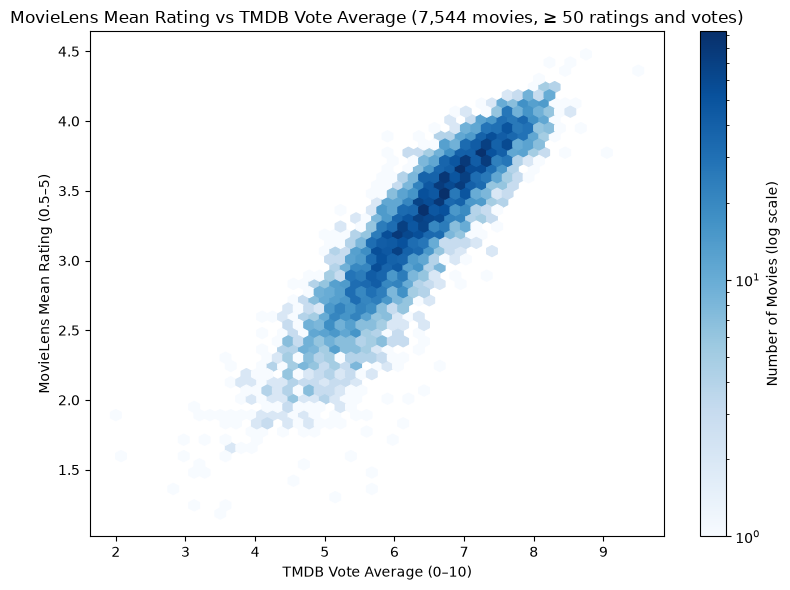

Pearson correlation: 0.91


In [ ]:
movielens_stats = ratings_df.groupby("movieId")["rating"].agg(mean_rating="mean", n_ratings="size")

rating_comparison = (
    links_df.dropna(subset=["tmdbId"])
    .assign(tmdbId=lambda data: data["tmdbId"].astype(int))
    .join(movielens_stats, on="movieId", how="inner")
    .merge(movies[["id", "vote_average", "vote_count"]], left_on="tmdbId", right_on="id")
    .query("n_ratings >= @MIN_VOTE_COUNT and vote_count >= @MIN_VOTE_COUNT")
)

plt.figure(figsize=(8, 6))
plt.hexbin(rating_comparison["vote_average"], rating_comparison["mean_rating"], gridsize=50, cmap="Blues", mincnt=1, bins="log")
plt.colorbar(label="Number of Movies (log scale)")
plt.title(
    f"MovieLens Mean Rating vs TMDB Vote Average ({len(rating_comparison):,} movies, "
    f"≥ {MIN_VOTE_COUNT} ratings and votes)"
)
plt.xlabel("TMDB Vote Average (0–10)")
plt.ylabel("MovieLens Mean Rating (0.5–5)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "movielens_vs_tmdb_rating.png", bbox_inches="tight")
plt.show()

print(f"Pearson correlation: {rating_comparison['vote_average'].corr(rating_comparison['mean_rating']):.2f}")

**Findings:** The MovieLens mean rating and the TMDB vote average agree closely (Pearson 0.91 for 7,544 movies with at least 50 ratings and votes), so both communities rate movies consistently.

## 18. Relationships Between Variables

### 18.1 Correlation Between Numeric Features

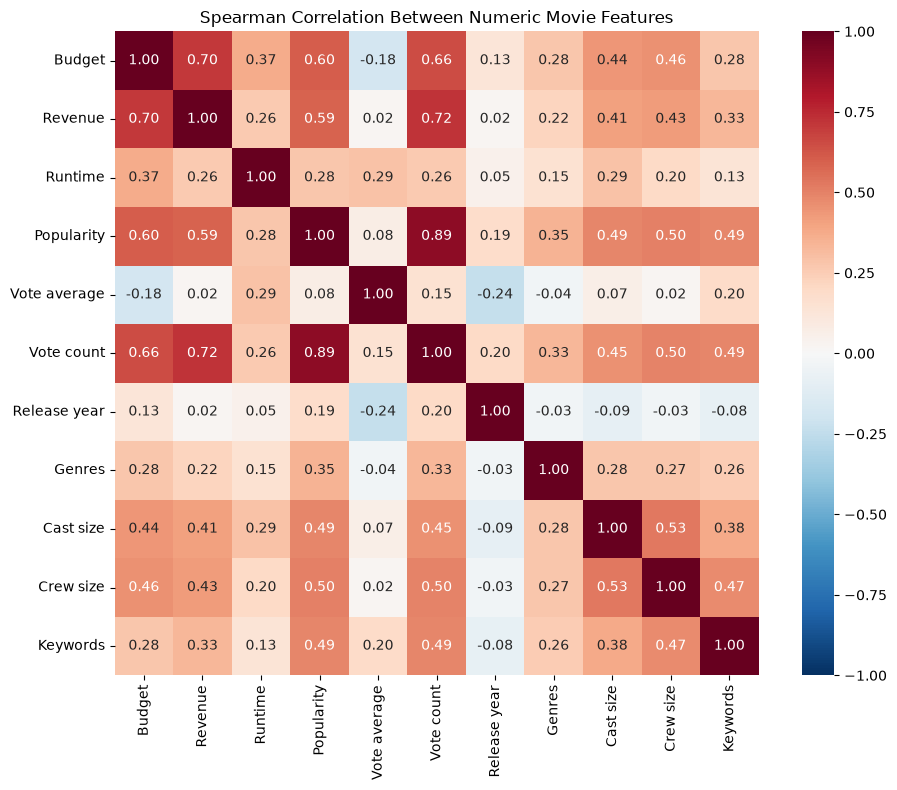

In [ ]:
numeric_features = {
    "budget_usd": "Budget",
    "revenue_usd": "Revenue",
    "runtime": "Runtime",
    "popularity": "Popularity",
    "vote_average": "Vote average",
    "vote_count": "Vote count",
    "release_year": "Release year",
    "n_genres": "Genres",
    "n_cast": "Cast size",
    "n_crew": "Crew size",
    "n_keywords": "Keywords"
}

correlation_df = movies[list(numeric_features)].astype(float).rename(columns=numeric_features)
correlation_df.loc[movies["vote_count"] < MIN_VOTE_COUNT, "Vote average"] = np.nan
correlation_df.loc[~movies["runtime"].between(1, MAX_PLAUSIBLE_RUNTIME_MIN), "Runtime"] = np.nan

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_df.corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Spearman Correlation Between Numeric Movie Features")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "numeric_correlation_heatmap.png", bbox_inches="tight")
plt.show()

Spearman (rank) correlation is used because budget, revenue, vote count and popularity are extremely right-skewed. Each pair uses the movies where both values are known; vote average is only used for movies with at least 50 votes and runtime only for plausible values.

### 18.2 Vote Average and Revenue by Genre

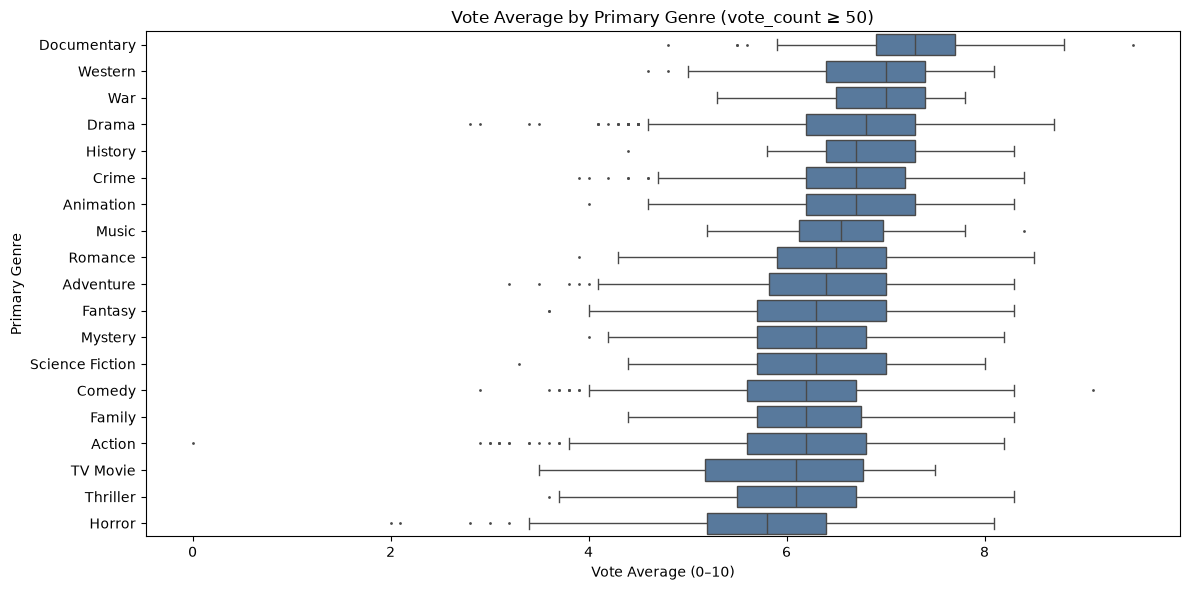

In [ ]:
rated_movies = movies[(movies["vote_count"] >= MIN_VOTE_COUNT) & movies["primary_genre"].notna()]
genre_order = rated_movies.groupby("primary_genre")["vote_average"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=rated_movies,
    x="vote_average",
    y="primary_genre",
    order=genre_order,
    color="#4C78A8",
    fliersize=1
)
plt.title(f"Vote Average by Primary Genre (vote_count ≥ {MIN_VOTE_COUNT})")
plt.xlabel("Vote Average (0–10)")
plt.ylabel("Primary Genre")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "vote_average_by_primary_genre.png", bbox_inches="tight")
plt.show()

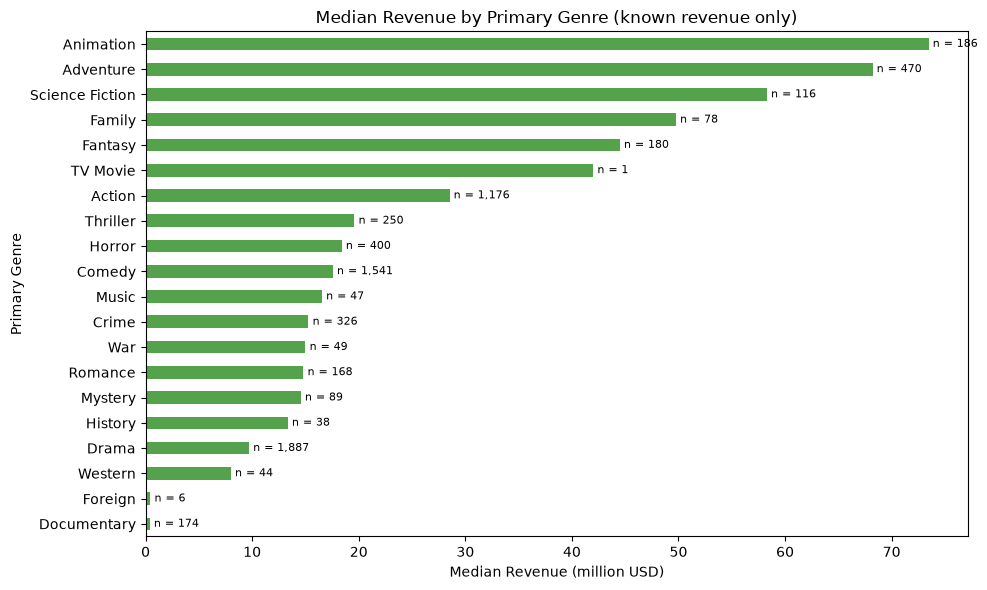

In [ ]:
revenue_by_genre = (
    movies.dropna(subset=["revenue_usd", "primary_genre"])
    .groupby("primary_genre")["revenue_usd"]
    .agg(["median", "size"])
    .sort_values("median")
)

ax = (revenue_by_genre["median"] / 1e6).plot(
    kind="barh",
    figsize=(10, 6),
    color="#54A24B",
    title="Median Revenue by Primary Genre (known revenue only)",
    ylabel="Primary Genre"
)

for patch, size in zip(ax.patches, revenue_by_genre["size"]):
    ax.annotate(f"n = {size:,}", (patch.get_width(), patch.get_y() + patch.get_height() / 2),
                xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)

ax.set_xlabel("Median Revenue (million USD)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "median_revenue_by_primary_genre.png", bbox_inches="tight")
plt.show()

**Findings:**

- Budget, revenue, vote count, popularity and cast/crew size are strongly correlated (e.g. popularity–vote count 0.89, revenue–vote count 0.72). Together they measure how big and well-known a movie is.
- The vote average is almost independent of budget and revenue (−0.18 and 0.02), is higher for longer movies (0.29), and is lower for newer movies (−0.24, likely because classics that are still rated are already a selection of good films).
- Documentaries, Westerns, War and Drama have the highest median vote average, while Horror has the lowest. Animation, Adventure and Science Fiction have the highest median revenue. The small groups (e.g. TV Movie, Foreign) should not be interpreted.

## 19. Trends Over Time

This section looks at how the movies, the people and companies behind them, and their themes have changed over time. It uses the movies released from 1910 to July 2017 (see 3.7).

Each analysis uses the time granularity that fits its data best:

| Analysis | Granularity | Reason |
|---|---|---|
| Dominant actors, directors, companies, genres and languages | Decade | Rankings need many movies per period, and careers and studio eras last longer than five years |
| Actors, directors and genres per movie | 5-year interval | Averages are stable with ≥ 50 movies per interval, and the short peak in cast size around 1935–1944 would be blurred in decades |
| Movies per production company | 5-year interval | Shows when the studio system ended, which decades merge with the neighbouring periods |
| Language diversity | 5-year interval | Distinct counts need a pool of movies; single years are too small and decades hide the steady growth |
| Runtime | Year | Most years have ≥ 30 valid runtimes, so the yearly average is reliable and shows short-term changes |
| Keywords | Decade and 5-year interval | Decades to rank the keywords, 5-year intervals to follow single rising and declining keywords |

A movie counts once for every distinct entity it is linked to: a movie with three genres counts once for each genre, and an actor credited in two roles of the same movie counts once. The last period is incomplete (the 2010s cover 2010 to July 2017, and the last 5-year interval 2015–2017, marked with *). This lowers totals and distinct counts but not averages and shares.

For actors, directors and production companies, the three entities with most movies in each decade are combined into one heatmap. The rows are ordered by the decade in which each entity had most movies, so that the heatmap reads as a timeline. Every cell shows the number of distinct movies.

### 19.1 Most Frequent Actors per Decade

In [ ]:
actor_pairs = (
    cast_members[["movie_id", "id"]]
    .assign(decade=lambda data: data["movie_id"].map(movie_decade))
    .dropna(subset=["decade"])
    .astype({"decade": int})
)
actor_counts = count_entities_per_period(actor_pairs, "id")
top_actor_ids = top_entities_per_period(actor_counts, TOP_PER_DECADE)

plot_period_heatmap(
    actor_counts.loc[top_actor_ids].rename(index=person_names, columns=decade_label),
    title=f"Most Frequent Actors per Decade (top {TOP_PER_DECADE} of each decade, number of movies)",
    ylabel="Actor",
    output_path=RESULT_FOLDER + "top_actors_per_decade.png"
)

**Findings:** Every era has its own most frequent actors:

- **1910s–1920s:** silent-film stars who also directed their own films (Charlie Chaplin, Buster Keaton).
- **1930s–1950s:** studio-era bit players (Bess Flowers in 89 movies in the 1940s alone, Irving Bacon, James Flavin).
- **1960s–1970s:** British horror stars (Christopher Lee, Peter Cushing, Donald Pleasence).
- **Since the 1990s:** prolific character actors (Samuel L. Jackson, Steve Buscemi), voice actors (Grey Griffin, Jeff Bennett) and James Franco.

Most actors are only among the leaders for one or two decades. Christopher Lee is the exception, with movies from the 1940s to the 2010s.

### 19.2 Most Prolific Directors per Decade

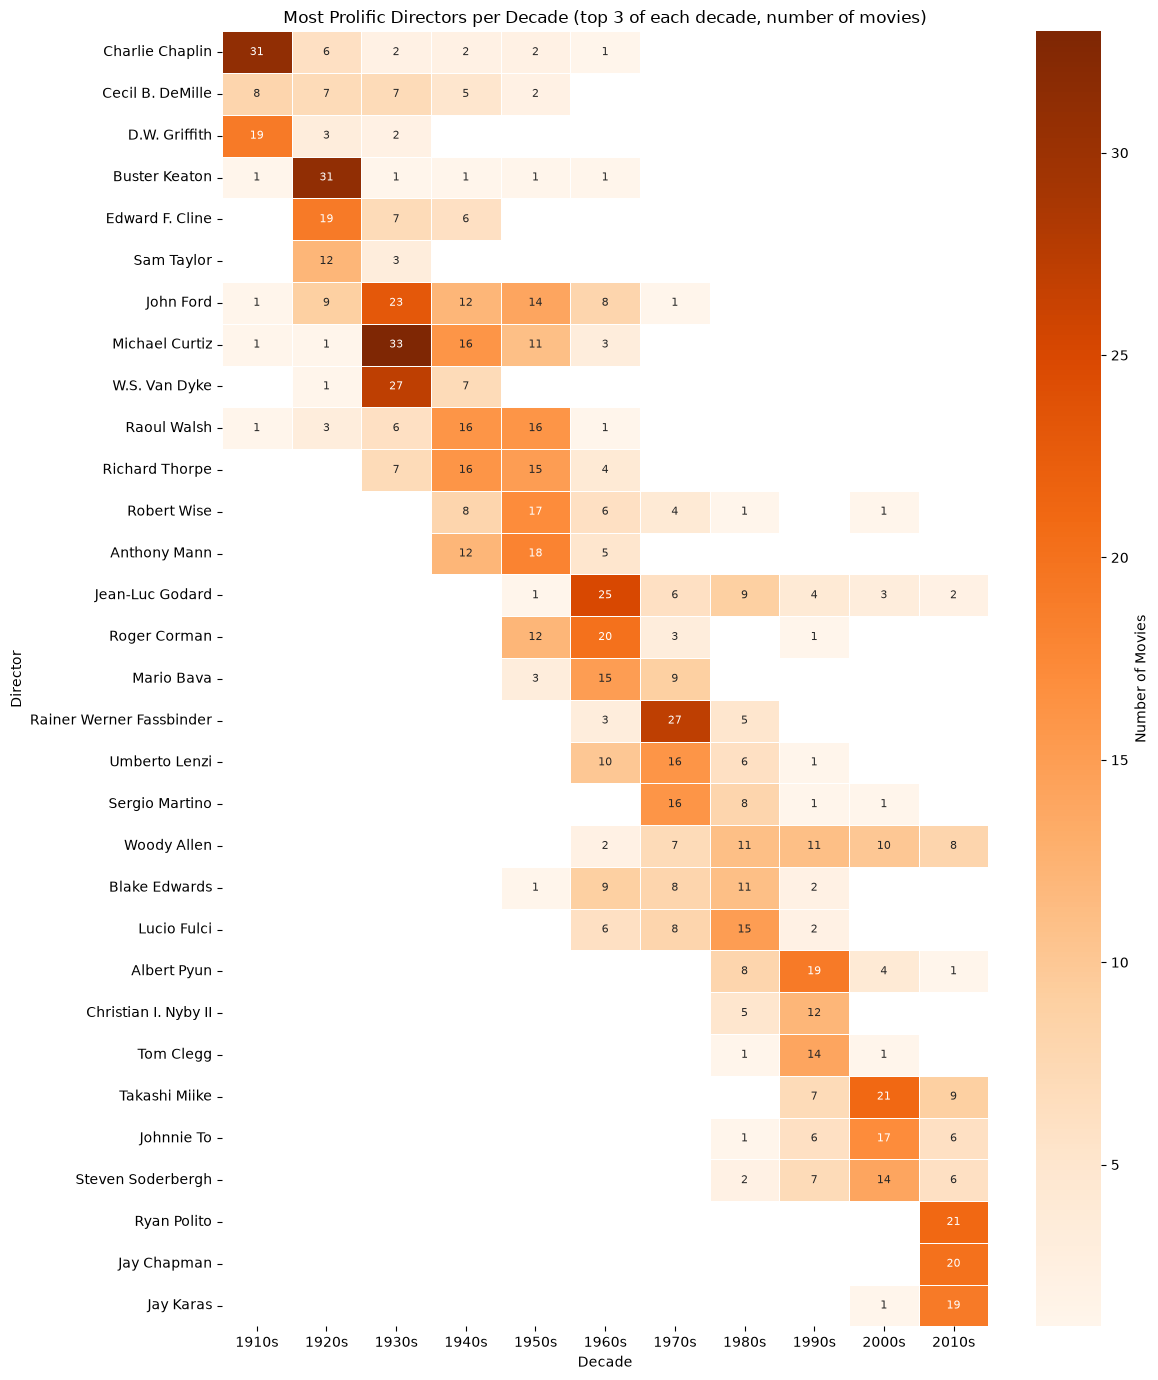

In [ ]:
director_pairs = (
    directors[["movie_id", "id"]]
    .assign(decade=lambda data: data["movie_id"].map(movie_decade))
    .dropna(subset=["decade"])
    .astype({"decade": int})
)
director_counts = count_entities_per_period(director_pairs, "id")
top_director_ids = top_entities_per_period(director_counts, TOP_PER_DECADE)

plot_period_heatmap(
    director_counts.loc[top_director_ids].rename(index=person_names, columns=decade_label),
    title=f"Most Prolific Directors per Decade (top {TOP_PER_DECADE} of each decade, number of movies)",
    ylabel="Director",
    output_path=RESULT_FOLDER + "top_directors_per_decade.png",
    cmap="Oranges"
)

**Findings:** The leading directors follow the history of the industry:

- **Studio era:** Hollywood studio directors (Michael Curtiz with 33 movies in the 1930s, W.S. Van Dyke, John Ford).
- **1960s–1980s:** European auteurs and genre directors (Jean-Luc Godard, Rainer Werner Fassbinder, the Italian genre directors Sergio Martino, Umberto Lenzi and Lucio Fulci).
- **2000s:** Asian directors (Takashi Miike, Johnnie To).
- **2010s:** directors of stand-up comedy specials (Ryan Polito, Jay Chapman, Jay Karas), which shows that the dataset also contains TV specials and not only feature films.

The counts are much lower than for actors, since a director makes far fewer movies than an actor appears in.

### 19.3 Production Companies with Most Movies per Decade

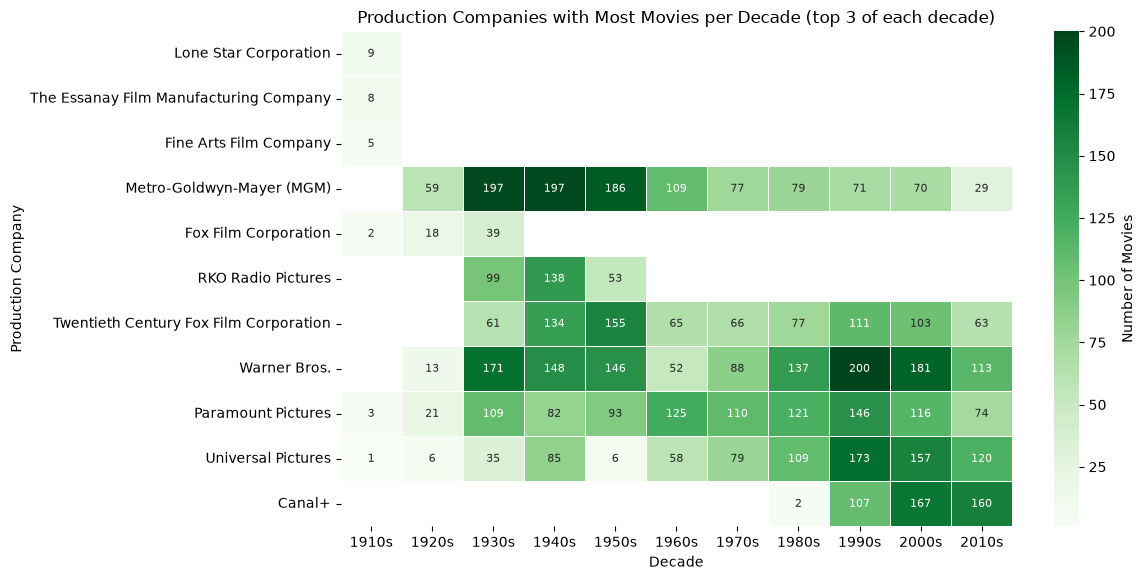

In [ ]:
company_pairs = (
    timeline[["id", "decade", "period_5y", "company_names"]]
    .explode("company_names")
    .dropna(subset=["company_names"])
    .rename(columns={"id": "movie_id", "company_names": "company"})
)
company_counts = count_entities_per_period(company_pairs, "company")
top_companies = top_entities_per_period(company_counts, TOP_PER_DECADE)

plot_period_heatmap(
    company_counts.loc[top_companies].rename(columns=decade_label),
    title=f"Production Companies with Most Movies per Decade (top {TOP_PER_DECADE} of each decade)",
    ylabel="Production Company",
    output_path=RESULT_FOLDER + "top_companies_per_decade.png",
    cmap="Greens"
)

**Findings:** MGM led from the 1920s to the 1950s with almost 200 movies per decade, followed by the other studios of the Hollywood studio system (Warner Bros., Paramount, Fox, RKO). The Hollywood majors stayed on top until the 2000s. In the 2010s the French Canal+, a co-producer of many European movies, is the most frequent company. Although ten times more movies are made today, no company reaches the decade output of MGM in the 1930s–1940s.

### 19.4 Genres per Decade

All 20 genres are shown. The cells show the number of movies, while the colour shows the share of the decade's movies with that genre, so decades of different size can be compared.

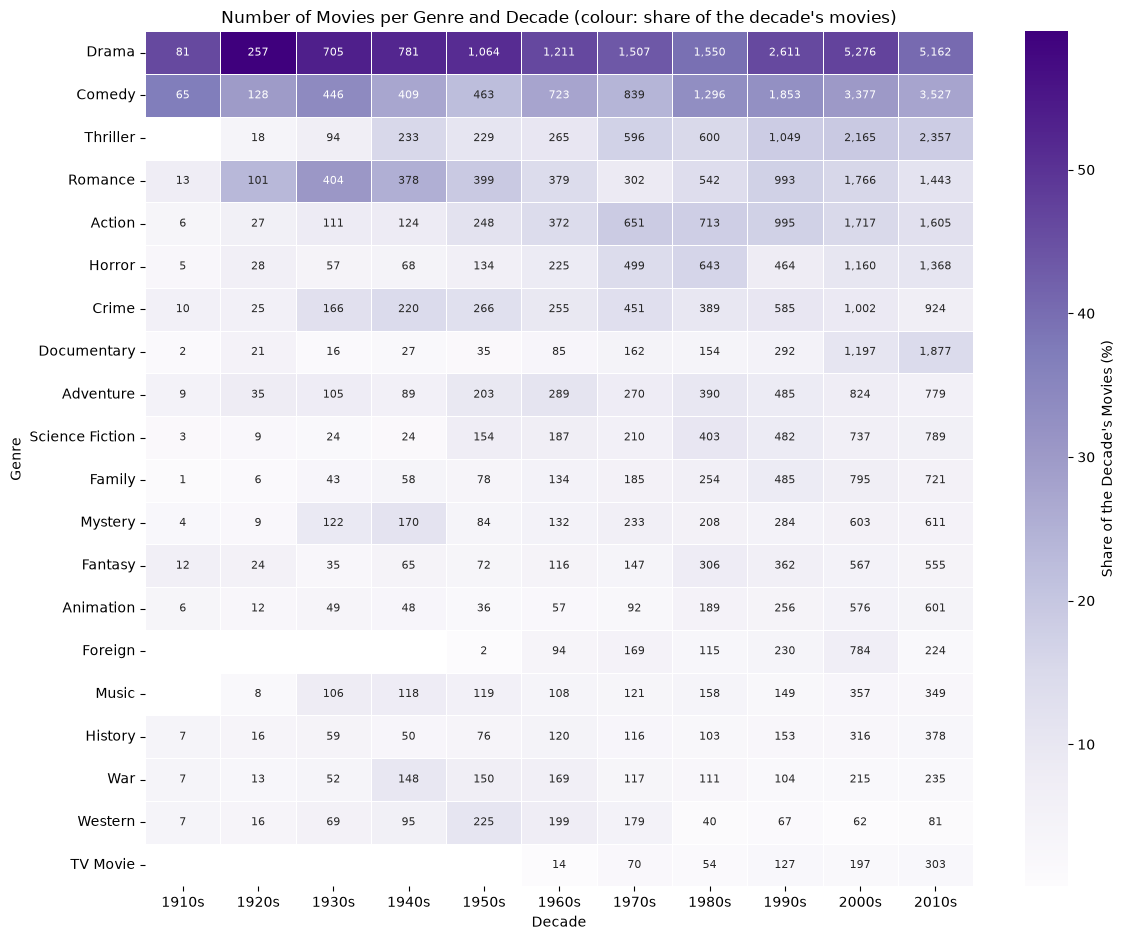

In [ ]:
genre_pairs = (
    timeline[["id", "decade", "genre_names"]]
    .explode("genre_names")
    .dropna(subset=["genre_names"])
    .rename(columns={"id": "movie_id", "genre_names": "genre"})
)
genre_counts_per_decade = count_entities_per_period(genre_pairs, "genre")
genre_counts_per_decade = genre_counts_per_decade.loc[genre_counts_per_decade.sum(axis=1).sort_values(ascending=False).index]
genre_shares_per_decade = 100 * genre_counts_per_decade / movies_per_decade

plot_period_heatmap(
    genre_counts_per_decade.rename(columns=decade_label),
    color_values=genre_shares_per_decade.rename(columns=decade_label),
    colorbar_label="Share of the Decade's Movies (%)",
    title="Number of Movies per Genre and Decade (colour: share of the decade's movies)",
    ylabel="Genre",
    output_path=RESULT_FOLDER + "genres_per_decade.png",
    cmap="Purples"
)

**Findings:** Drama is the most common genre in every decade, followed by Comedy, but the other genres change considerably:

- **Romance** is in 31 % of the movies of the 1930s and only 11 % of the 2010s.
- **War** peaks in the 1940s (10 %) and **Western** in the 1950s–1960s (11 %), but the Western almost disappears after the 1980s (< 1 % in the 2010s).
- **Thriller, Horror and Science Fiction** grow strongly from the 1970s.
- **Documentary** is the fastest-growing genre (5 % in the 1990s, 15 % in the 2010s).
- **Foreign** and **TV Movie** only appear from the 1960s and are TMDB-specific labels rather than genres.

### 19.5 Languages per Decade

The original language of each movie is used. Because English accounts for 50–90 % of every decade, the colour scale is logarithmic so that the smaller languages remain distinguishable.

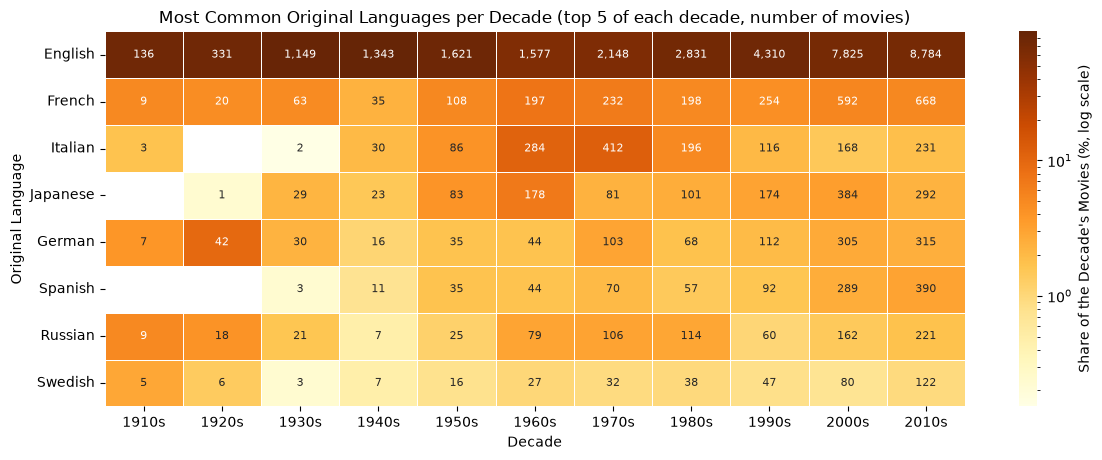

In [ ]:
language_pairs = timeline[["id", "decade", "original_language"]].rename(
    columns={"id": "movie_id", "original_language": "language"}
).dropna(subset=["language"])
language_counts_per_decade = count_entities_per_period(language_pairs, "language")
top_decade_languages = top_entities_per_period(language_counts_per_decade, TOP_LANGUAGES_PER_DECADE)
top_decade_languages = sorted(top_decade_languages, key=lambda code: -language_counts_per_decade.loc[code].sum())
language_shares_per_decade = 100 * language_counts_per_decade / movies_per_decade

plot_period_heatmap(
    language_counts_per_decade.loc[top_decade_languages].rename(index=language_name, columns=decade_label),
    color_values=language_shares_per_decade.loc[top_decade_languages].rename(index=language_name, columns=decade_label),
    colorbar_label="Share of the Decade's Movies (%, log scale)",
    title=f"Most Common Original Languages per Decade (top {TOP_LANGUAGES_PER_DECADE} of each decade, number of movies)",
    ylabel="Original Language",
    output_path=RESULT_FOLDER + "languages_per_decade.png",
    log_color=True,
    cmap="YlOrBr"
)

**Findings:** English is the most common original language in every decade, but its share dropped from 87 % in the 1930s to about 62 % in the 1970s and 69 % in the 2010s. The other leading languages reflect national film industries:

- German in the 1920s (Weimar cinema).
- Italian with a peak in the 1960s–1970s (Italian genre films and spaghetti westerns).
- Japanese with a peak in the 1960s.
- French as the largest non-English language in most decades.

Spanish grows steadily over time.

### 19.6 Leaders per Decade

In [ ]:
decade_leaders = pd.DataFrame({
    "Movies": movies_per_decade.map("{:,}".format),
    "Actor": describe_leaders(actor_counts, person_names.get),
    "Director": describe_leaders(director_counts, person_names.get),
    "Production company": describe_leaders(company_counts),
    "Genre": describe_leaders(genre_counts_per_decade),
    "Non-English language": describe_leaders(language_counts_per_decade.drop(index="en"), language_name)
})
decade_leaders.index = decade_leaders.index.map(decade_label)

display(decade_leaders)

,Movies,Actor,Director,Production company,Genre,Non-English language
1910s,176,Charlie Chaplin (36),Charlie Chaplin (31),Lone Star Corporation (9),Drama (81),French (9)
1920s,431,Buster Keaton (34),Buster Keaton (31),Metro-Goldwyn-Mayer (MGM) (59),Drama (257),German (42)
1930s,"1,315",Bess Flowers (51),Michael Curtiz (33),Metro-Goldwyn-Mayer (MGM) (197),Drama (705),French (63)
1940s,"1,493",Bess Flowers (89),Michael Curtiz (16),Metro-Goldwyn-Mayer (MGM) (197),Drama (781),French (35)
1950s,"2,079",Bess Flowers (74),Anthony Mann (18),Metro-Goldwyn-Mayer (MGM) (186),"Drama (1,064)",French (108)
1960s,"2,621",Christopher Lee (29),Jean-Luc Godard (25),Paramount Pictures (125),"Drama (1,211)",Italian (284)
1970s,"3,471",Christopher Lee (36),Rainer Werner Fassbinder (27),Paramount Pictures (110),"Drama (1,507)",Italian (412)
1980s,"3,928",M. Emmet Walsh (26),Lucio Fulci (15),Warner Bros. (137),"Drama (1,550)",French (198)
1990s,"5,675",Samuel L. Jackson (40),Albert Pyun (19),Warner Bros. (200),"Drama (2,611)",French (254)
2000s,"11,195",Samuel L. Jackson (41),Takashi Miike (21),Warner Bros. (181),"Drama (5,276)",French (592)


**Findings:** The table summarises the eras: silent-era stars (Chaplin, Keaton), the MGM-dominated studio era (1920s–1950s) with its bit players and studio directors, the European and Asian auteurs of the 1960s–2000s, and today's mix of prolific character actors, many small companies and Canal+ as a co-producer. Drama leads every decade, while the leading non-English language alternates between French, German and Italian.

### 19.7 Actors, Directors and Genres per Movie

The averages only include movies where the corresponding information exists: actors for movies with a cast, directors for movies with a crew, and genres for movies with at least one genre. Otherwise missing credits would look like smaller casts.

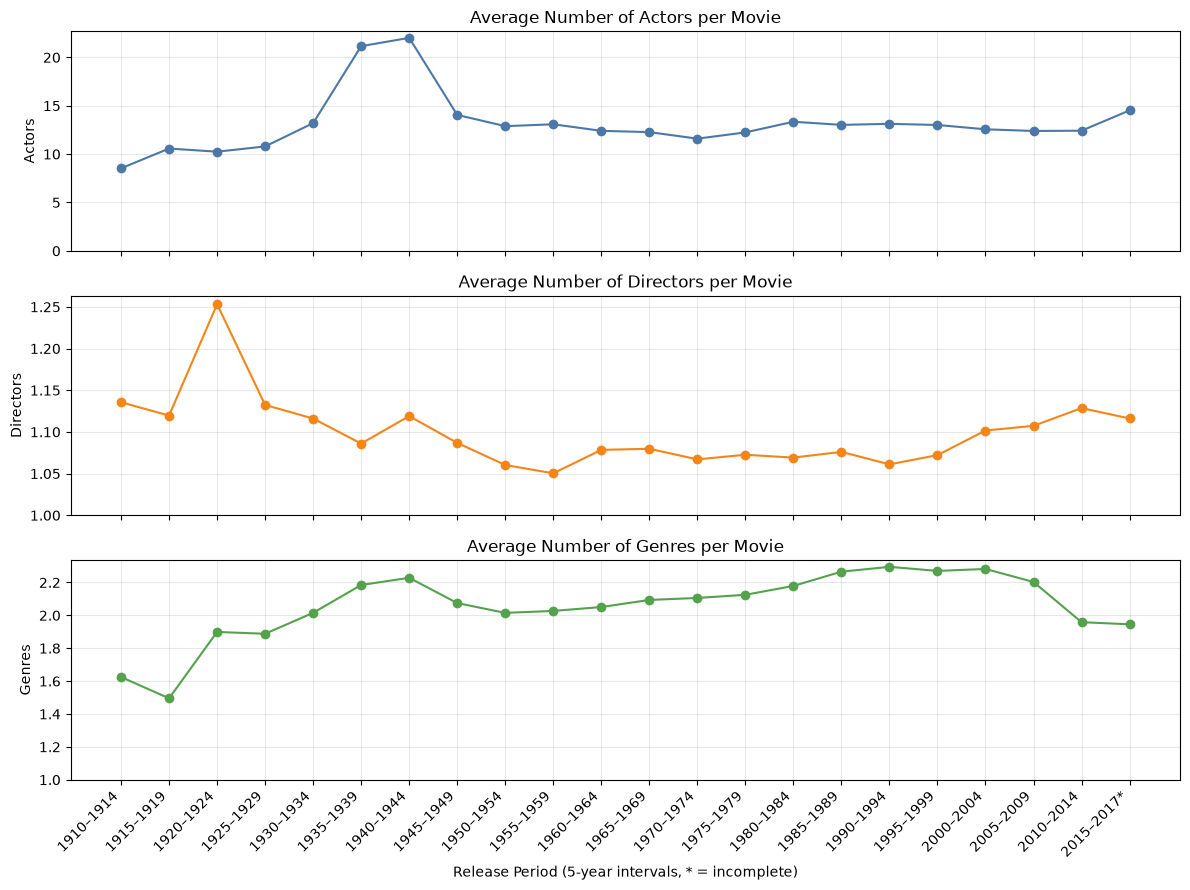

period_5y,1910–1914,1915–1919,1920–1924,1925–1929,1930–1934,1935–1939,1940–1944,1945–1949,1950–1954,1955–1959,...,1970–1974,1975–1979,1980–1984,1985–1989,1990–1994,1995–1999,2000–2004,2005–2009,2010–2014,2015–2017*
Actors,8.53,10.58,10.25,10.79,13.20,21.16,22.02,14.05,12.89,13.08,...,11.60,12.24,13.35,13.02,13.13,13.01,12.56,12.39,12.42,14.52
Directors,1.14,1.12,1.25,1.13,1.12,1.09,1.12,1.09,1.06,1.05,...,1.07,1.07,1.07,1.08,1.06,1.07,1.10,1.11,1.13,1.12
Genres,1.62,1.50,1.90,1.89,2.02,2.18,2.23,2.07,2.02,2.03,...,2.11,2.13,2.18,2.27,2.30,2.27,2.28,2.20,1.96,1.95


In [ ]:
credits_per_movie = pd.DataFrame({
    "Actors": timeline[timeline["n_actors"] > 0].groupby("period_5y")["n_actors"].mean(),
    "Directors": timeline[timeline["n_crew"] > 0].groupby("period_5y")["n_directors"].mean(),
    "Genres": timeline[timeline["n_genres"] > 0].groupby("period_5y")["n_genres"].mean()
})
credits_per_movie = credits_per_movie.loc[movies_per_period_5y[movies_per_period_5y >= MIN_MOVIES_PER_PERIOD].index]
credits_per_movie.index = credits_per_movie.index.map(period_5y_label)

axes = credits_per_movie.plot(
    subplots=True,
    figsize=(12, 9),
    marker="o",
    legend=False,
    color=["#4C78A8", "#F58518", "#54A24B"],
    title=["Average Number of Actors per Movie", "Average Number of Directors per Movie", "Average Number of Genres per Movie"]
)

# Start each axis at a natural baseline, so small changes (e.g. 1.05 vs 1.10 directors) are not exaggerated
for ax, label, baseline in zip(axes, ["Actors", "Directors", "Genres"], [0, 1, 1]):
    ax.set_ylabel(label)
    ax.set_ylim(bottom=baseline)
    ax.grid(alpha=0.3)
axes[-1].set_xticks(range(len(credits_per_movie)))
axes[-1].set_xticklabels(credits_per_movie.index, rotation=45, ha="right")
axes[-1].set_xlabel("Release Period (5-year intervals, * = incomplete)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "credits_per_movie_over_time.png", bbox_inches="tight")
plt.show()

display(credits_per_movie.round(2).T)

**Findings:**

- **Actors:** the average cast jumps from about 13 to 21–22 actors per movie in 1935–1944. This is the height of the studio era, when TMDB lists many uncredited extras and bit players. After the war it falls back to 12–14 actors and stays there.
- **Directors:** the number stays close to one per movie (1.05–1.25). The slight rise after 2000 comes from co-directed movies and anthologies.
- **Genres:** the number per movie grew from about 1.6 in the 1910s to 2.3 in the 1990s and fell to below 2 after 2010. Recent movies have more specific genre labels, or have not been tagged as completely yet.

### 19.8 Movies per Production Company

For each 5-year interval, the number of distinct movies of every company that produced at least one movie in the interval is counted, and the average is taken over these active companies (e.g. 10 and 20 movies give an average of 15). The number of active companies is shown below for context.

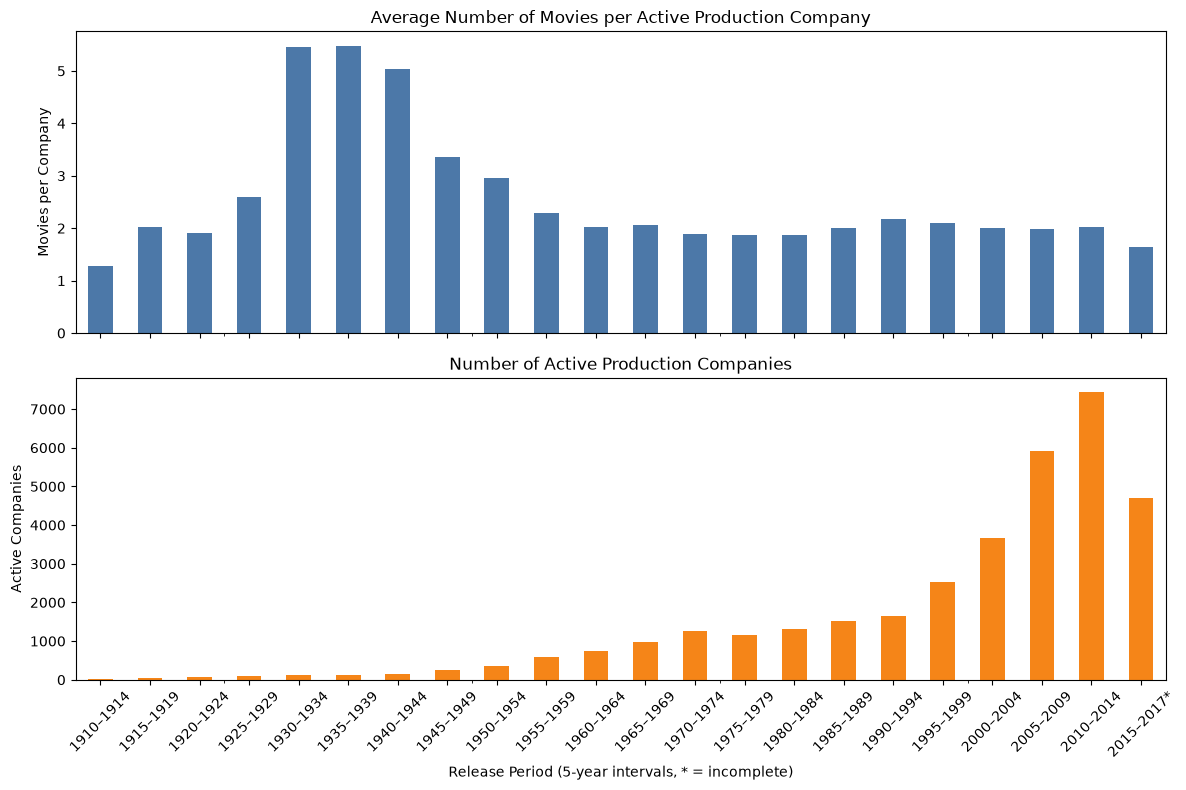

period_5y,1910–1914,1915–1919,1920–1924,1925–1929,1930–1934,1935–1939,1940–1944,1945–1949,1950–1954,1955–1959,...,1970–1974,1975–1979,1980–1984,1985–1989,1990–1994,1995–1999,2000–2004,2005–2009,2010–2014,2015–2017*
average_movies,1.28,2.02,1.91,2.59,5.46,5.48,5.04,3.35,2.96,2.29,...,1.89,1.86,1.86,2.01,2.17,2.1,2.0,1.98,2.02,1.65
active_companies,25.00,52.00,68.00,109.00,118.00,133.00,155.00,244.00,354.00,584.00,...,1264.00,1145.00,1302.00,1530.00,1658.00,2534.0,3665.0,5912.00,7432.00,4708.00


In [ ]:
company_activity = (
    company_pairs.drop_duplicates(["movie_id", "company"])
    .groupby(["period_5y", "company"])
    .size()
    .groupby("period_5y")
    .agg(average_movies="mean", active_companies="size")
)
company_activity = company_activity.loc[company_activity.index.map(movies_per_period_5y) >= MIN_MOVIES_PER_PERIOD]
company_activity.index = company_activity.index.map(period_5y_label)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

company_activity["average_movies"].plot(
    kind="bar",
    ax=axes[0],
    color="#4C78A8",
    title="Average Number of Movies per Active Production Company",
    ylabel="Movies per Company"
)
company_activity["active_companies"].plot(
    kind="bar",
    ax=axes[1],
    color="#F58518",
    title="Number of Active Production Companies",
    ylabel="Active Companies",
    xlabel="Release Period (5-year intervals, * = incomplete)",
    rot=45
)

plt.tight_layout()
plt.savefig(RESULT_FOLDER + "movies_per_company_over_time.png", bbox_inches="tight")
plt.show()

display(company_activity.round(2).T)

**Findings:** In 1930–1944 an active production company made 5–5.5 movies per 5-year interval on average, compared with about 2 before and after. This is the Hollywood studio system, in which a few large studios produced most movies. After the end of the studio system (from the late 1940s) the average fell to about 2 by 1960 and has stayed there. Meanwhile the number of active companies grew from about 150 to over 7,400 in 2010–2014. Production has become much more fragmented: the additional movies are made by many small companies, often with only one or two movies. The lower value for 2015–2017* comes from the incomplete period.

### 19.9 Language Diversity

The number of distinct languages is counted both for the original language and for all spoken languages of the movies released in each 5-year interval. "No Language" (`xx`) is excluded.

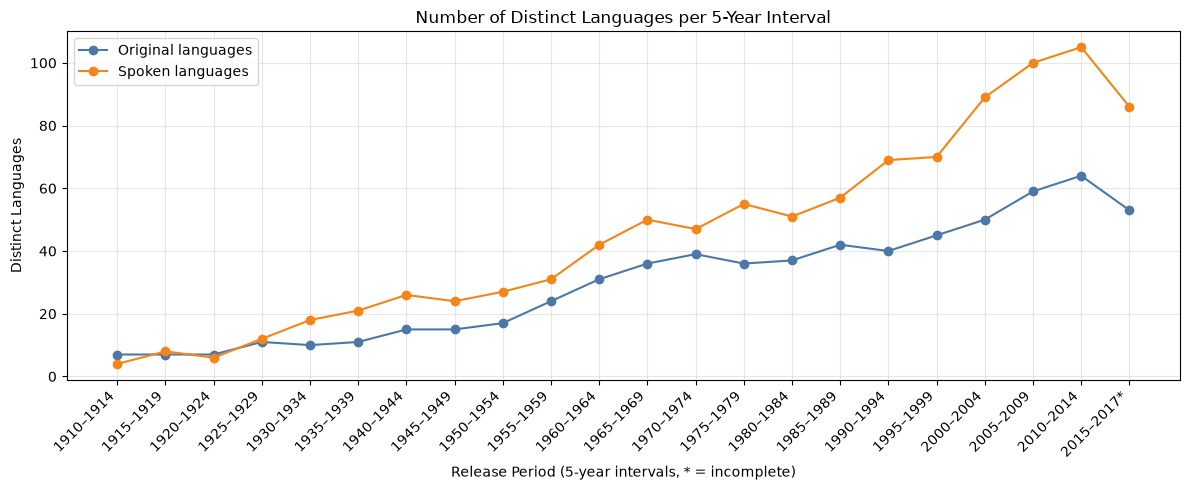

period_5y,1910–1914,1915–1919,1920–1924,1925–1929,1930–1934,1935–1939,1940–1944,1945–1949,1950–1954,1955–1959,...,1970–1974,1975–1979,1980–1984,1985–1989,1990–1994,1995–1999,2000–2004,2005–2009,2010–2014,2015–2017*
Original languages,7.0,7.0,7.0,11.0,10.0,11.0,15.0,15.0,17.0,24.0,...,39.0,36.0,37.0,42.0,40.0,45.0,50.0,59.0,64.0,53.0
Spoken languages,4.0,8.0,6.0,12.0,18.0,21.0,26.0,24.0,27.0,31.0,...,47.0,55.0,51.0,57.0,69.0,70.0,89.0,100.0,105.0,86.0
Non-English movies (%),28.8,19.7,26.6,21.2,12.6,12.6,8.2,11.8,18.0,25.5,...,37.8,38.4,33.4,23.3,23.6,24.4,30.4,29.9,31.0,31.4


In [ ]:
spoken_language_pairs = (
    timeline[["id", "period_5y", "language_codes"]]
    .explode("language_codes")
    .dropna(subset=["language_codes"])
)

language_diversity = pd.DataFrame({
    "Original languages": timeline[timeline["original_language"].ne("xx")].groupby("period_5y")["original_language"].nunique(),
    "Spoken languages": spoken_language_pairs[spoken_language_pairs["language_codes"].ne("xx")].groupby("period_5y")["language_codes"].nunique()
})
language_diversity = language_diversity.loc[movies_per_period_5y[movies_per_period_5y >= MIN_MOVIES_PER_PERIOD].index]
language_diversity.index = language_diversity.index.map(period_5y_label)

ax = language_diversity.plot(
    figsize=(12, 5),
    marker="o",
    color=["#4C78A8", "#F58518"],
    title="Number of Distinct Languages per 5-Year Interval",
    ylabel="Distinct Languages"
)

ax.set_xticks(range(len(language_diversity)))
ax.set_xticklabels(language_diversity.index, rotation=45, ha="right")
ax.set_xlabel("Release Period (5-year intervals, * = incomplete)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "language_diversity_over_time.png", bbox_inches="tight")
plt.show()

non_english_share = 100 * timeline.groupby("period_5y")["original_language"].apply(lambda languages: languages.ne("en").mean())
display(pd.concat([language_diversity.T, non_english_share.rename(index=period_5y_label).rename("Non-English movies (%)").to_frame().T]).round(1))

**Findings:**

- **Distinct languages grew steadily:** original languages rose from fewer than 10 per interval before 1925 to 64 in 2010–2014, and spoken languages from 4 to 105.
- **The trend is more than volume:** part of the growth comes from the larger number of movies per interval, but the share of non-English movies also rose. It went from 8–13 % in the 1930s–1940s to about 30 % since 2000, with a peak of 38 % in the 1970s (the strongest period of European and Asian cinema in the dataset).
- **Incomplete last interval:** the drop in 2015–2017* is caused by the incomplete period.

### 19.10 Runtime

Only valid runtimes (0 < runtime ≤ 300 minutes) are used, and only years with at least 30 of them. The shaded band shows the interquartile range (25–75 %), so the average can be compared with the typical spread.

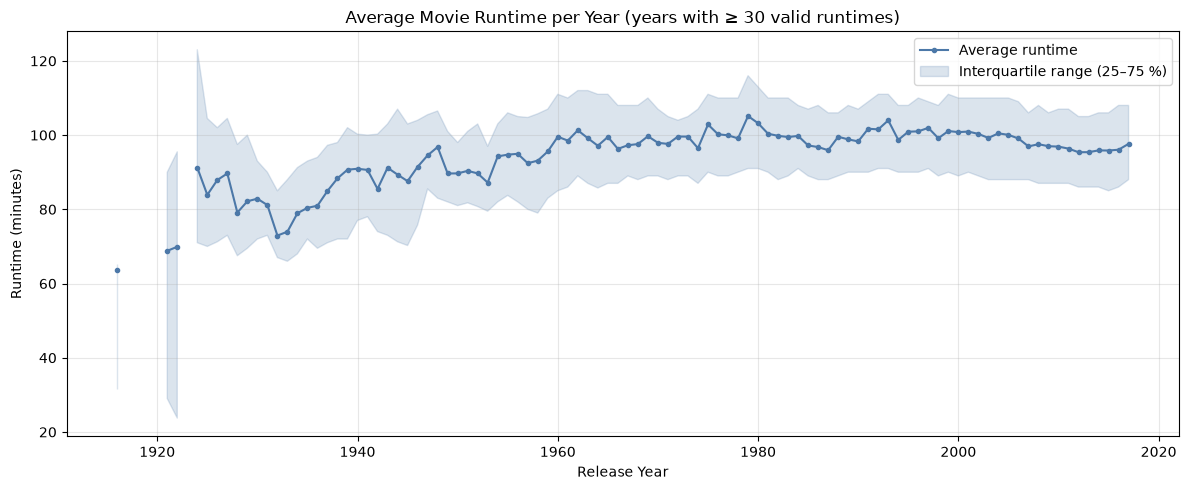

Years shown: 1916–2017, 5 years left out with fewer than 30 runtimes


decade,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s
Average runtime (min),52.6,81.1,81.4,90.8,92.3,98.5,99.8,99.0,100.8,98.9,96.0


In [ ]:
valid_runtimes = timeline[timeline["runtime"].between(1, MAX_PLAUSIBLE_RUNTIME_MIN)]

runtime_per_year = valid_runtimes.groupby("release_year")["runtime"].agg(
    average="mean",
    q1=lambda runtimes: runtimes.quantile(0.25),
    q3=lambda runtimes: runtimes.quantile(0.75),
    movies="size"
)
runtime_per_year = runtime_per_year[runtime_per_year["movies"] >= MIN_MOVIES_PER_YEAR]
runtime_per_year.index = runtime_per_year.index.astype(int)
# Years with too few runtimes become gaps instead of being bridged by the line
runtime_per_year = runtime_per_year.reindex(range(runtime_per_year.index.min(), runtime_per_year.index.max() + 1))

ax = runtime_per_year["average"].plot(
    figsize=(12, 5),
    color="#4C78A8",
    marker="o",
    markersize=3,
    label="Average runtime",
    title=f"Average Movie Runtime per Year (years with ≥ {MIN_MOVIES_PER_YEAR} valid runtimes)"
)
ax.fill_between(
    runtime_per_year.index,
    runtime_per_year["q1"],
    runtime_per_year["q3"],
    color="#4C78A8",
    alpha=0.2,
    label="Interquartile range (25–75 %)"
)

ax.set_xlabel("Release Year")
ax.set_ylabel("Runtime (minutes)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "average_runtime_per_year.png", bbox_inches="tight")
plt.show()

print(f"Years shown: {runtime_per_year.index.min()}–{runtime_per_year.index.max()}, "
      f"{runtime_per_year['average'].isna().sum()} years left out with fewer than {MIN_MOVIES_PER_YEAR} runtimes")
display(
    valid_runtimes.groupby("decade")["runtime"].mean().rename(index=decade_label).rename("Average runtime (min)").round(1).to_frame().T
)

**Findings:** The average runtime grew quickly from about 50–65 minutes in the 1910s, when short films were common, to 80–90 minutes in the 1930s and about 100 minutes from the 1960s to the 1990s. Since 2000 it has slowly declined to about 95 minutes. The interquartile range narrowed strongly after the 1930s, as the feature film of 85–110 minutes became the standard. Before 1922 several years have fewer than 30 valid runtimes and are left out.

### 19.11 Keyword Trends

Keyword coverage differs between decades (51–86 % of the movies have keywords), so shares are computed relative to the movies **with keywords** in each period. Only decades with at least 100 such movies are shown.

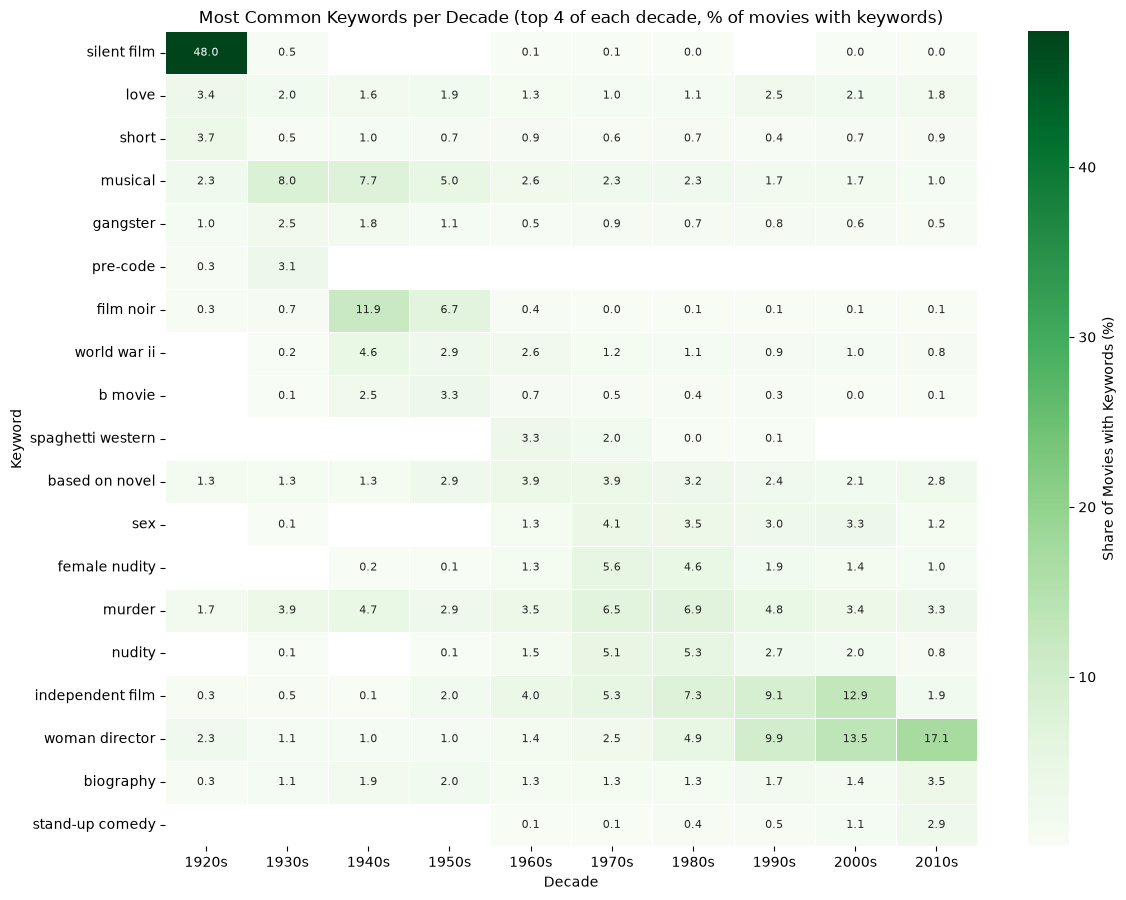

In [ ]:
keyword_pairs = (
    keywords[["id", "keywords"]]
    .assign(keyword=lambda data: data["keywords"].map(lambda items: extract_field(items, "name")))
    .explode("keyword")
    .dropna(subset=["keyword"])
    .rename(columns={"id": "movie_id"})[["movie_id", "keyword"]]
    .drop_duplicates()
)
keyword_pairs["decade"] = keyword_pairs["movie_id"].map(movie_decade)
keyword_pairs["period_5y"] = keyword_pairs["movie_id"].map(movie_period_5y)
keyword_pairs["release_year"] = keyword_pairs["movie_id"].map(timeline.set_index("id")["release_year"])
keyword_pairs = keyword_pairs.dropna(subset=["decade"]).astype({"decade": int, "period_5y": int, "release_year": int})

movies_with_keywords_per_decade = keyword_pairs.groupby("decade")["movie_id"].nunique()
movies_with_keywords_per_period = keyword_pairs.groupby("period_5y")["movie_id"].nunique()
keyword_decades = movies_with_keywords_per_decade[movies_with_keywords_per_decade >= MIN_MOVIES_PER_DECADE].index

keyword_shares_per_decade = (
    100 * count_entities_per_period(keyword_pairs, "keyword")[keyword_decades]
    / movies_with_keywords_per_decade[keyword_decades]
)
top_decade_keywords = top_entities_per_period(keyword_shares_per_decade, TOP_KEYWORDS_PER_DECADE)

plot_period_heatmap(
    keyword_shares_per_decade.loc[top_decade_keywords].rename(columns=decade_label),
    colorbar_label="Share of Movies with Keywords (%)",
    value_format="{:.1f}",
    title=f"Most Common Keywords per Decade (top {TOP_KEYWORDS_PER_DECADE} of each decade, % of movies with keywords)",
    ylabel="Keyword",
    output_path=RESULT_FOLDER + "keywords_per_decade.png",
    cmap="Greens"
)

**Findings:** The most common keywords follow the history of film:

- **1920s:** "silent film" (48 % of the movies).
- **1930s:** "musical" and "pre-code".
- **1940s:** "film noir" (12 %) and "world war ii".
- **1950s:** "b movie" alongside film noir.
- **1960s:** "spaghetti western".
- **1970s–1980s:** nudity, sex and murder.
- **Recent decades:** "independent film", "woman director", "biography" and "stand-up comedy".

To find **rising and declining** keywords, the share of every frequent keyword (at least 100 movies) is compared between two eras with many movies: 1950–1979 and 1990–2017.

In [ ]:
(early_era, (early_start, early_end)), (recent_era, (recent_start, recent_end)) = KEYWORD_ERAS.items()

frequent_keywords = keyword_pairs.groupby("keyword").size().loc[lambda counts: counts >= MIN_KEYWORD_MOVIES].index
keyword_change = (
    era_keyword_shares(keyword_pairs, recent_start, recent_end).reindex(frequent_keywords, fill_value=0)
    - era_keyword_shares(keyword_pairs, early_start, early_end).reindex(frequent_keywords, fill_value=0)
).sort_values()

largest_changes = pd.concat([keyword_change.head(10), keyword_change.tail(10)])

ax = largest_changes.plot(
    kind="barh",
    figsize=(10, 8),
    color=["#E45756" if change < 0 else "#54A24B" for change in largest_changes],
    title=f"Largest Changes in Keyword Share ({early_era} → {recent_era})",
    ylabel="Keyword"
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Change in Share of Movies with Keywords (percentage points)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "keyword_share_changes.png", bbox_inches="tight")
plt.show()

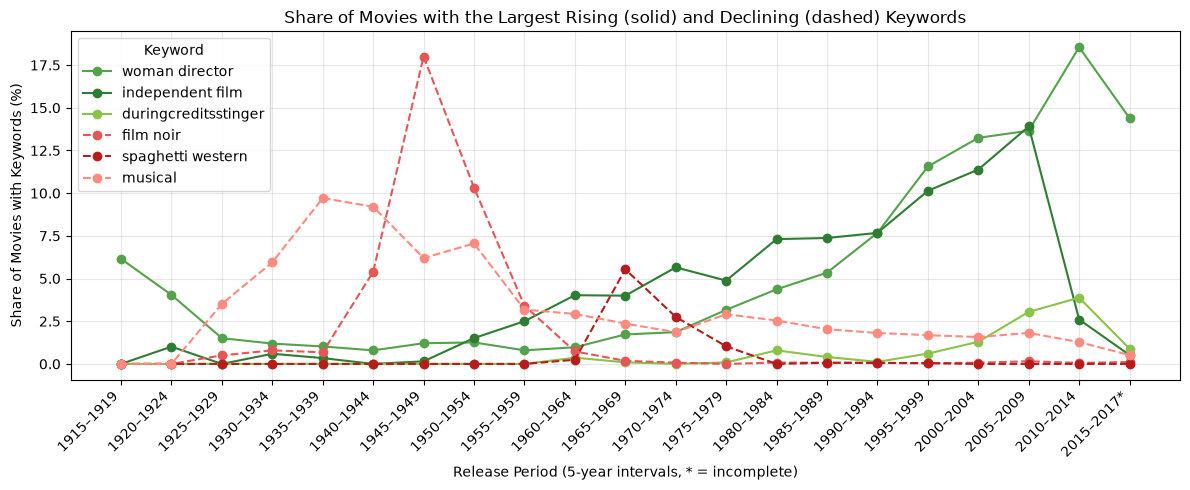

In [ ]:
rising_keywords = list(keyword_change.tail(3).index[::-1])
declining_keywords = list(keyword_change.head(3).index)
keyword_periods = movies_with_keywords_per_period[movies_with_keywords_per_period >= MIN_MOVIES_PER_PERIOD].index

keyword_trends = (
    keyword_pairs[keyword_pairs["keyword"].isin(rising_keywords + declining_keywords)]
    .groupby(["period_5y", "keyword"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=keyword_periods, columns=rising_keywords + declining_keywords, fill_value=0)
    .div(movies_with_keywords_per_period[keyword_periods], axis=0)
    * 100
)
keyword_trends.index = keyword_trends.index.map(period_5y_label)

ax = keyword_trends.plot(
    figsize=(12, 5),
    marker="o",
    color=["#54A24B", "#2E7D32", "#8BC34A", "#E45756", "#B71C1C", "#FF8A80"],
    style=["-"] * len(rising_keywords) + ["--"] * len(declining_keywords),
    title="Share of Movies with the Largest Rising (solid) and Declining (dashed) Keywords",
    ylabel="Share of Movies with Keywords (%)"
)

ax.set_xticks(range(len(keyword_trends)))
ax.set_xticklabels(keyword_trends.index, rotation=45, ha="right")
ax.set_xlabel("Release Period (5-year intervals, * = incomplete)")
ax.grid(alpha=0.3)
ax.legend(title="Keyword")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "keyword_trends.png", bbox_inches="tight")
plt.show()

**Findings:**

- **Rising:** between 1950–1979 and 1990–2017, "woman director" grows by more than 12 percentage points, followed by "independent film", post-credit scenes ("duringcreditsstinger", "aftercreditsstinger", popularised by modern franchise movies), "stand-up comedy" and teen and sports themes.
- **Declining:** the genre labels of the classical era (film noir, spaghetti western, musical, b movie, world war ii) and the explicit themes of the 1970s.
- **Waves:** the 5-year trends show that genres come and go in waves. Film noir peaks at 18 % in 1945–1949 and spaghetti western in 1965–1969, while "woman director" has risen steadily since the 1980s.
- **Likely a tagging change:** "independent film" (and partly "woman director") drops sharply after 2010. This is more likely a change in how TMDB keywords were assigned to recent movies than a real trend, so keyword shares of the most recent years must be interpreted with care.

## 20. Data Quality

### 20.1 Missing Values

In [ ]:
original_columns = [
    "adult", "belongs_to_collection", "budget", "genres", "homepage", "id", "imdb_id",
    "original_language", "original_title", "overview", "popularity", "poster_path",
    "production_companies", "production_countries", "release_date", "revenue", "runtime",
    "spoken_languages", "status", "tagline", "title", "video", "vote_average", "vote_count"
]

plt.figure(figsize=(12, 6))
sns.heatmap(
    raw_movies_df[original_columns].isnull(),
    cbar=False,
    cmap="Blues_r",
    yticklabels=False
)

plt.title("Missing Values in movies_metadata.csv (white = missing)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "missing_values_heatmap.png", bbox_inches="tight")
plt.show()

Many values are not `NaN` but still carry no information: a budget of 0, an empty genre list, a runtime of 0. The chart separates explicit missing values from these implicit ones.

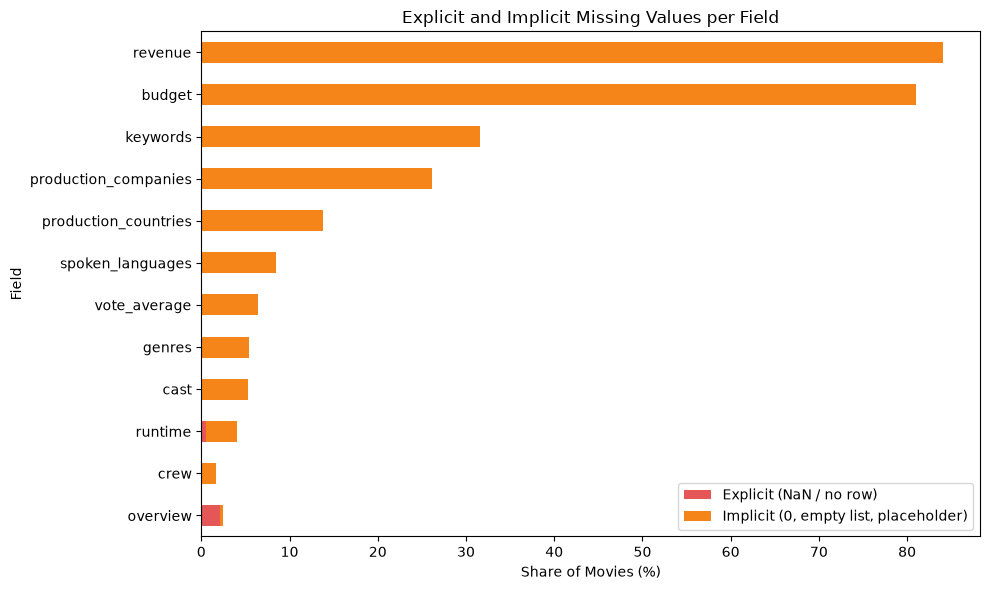

,Explicit (NaN / no row),"Implicit (0, empty list, placeholder)",Total
revenue,0.01,84.05,84.06
budget,0.00,80.99,80.99
keywords,0.00,31.56,31.57
production_companies,0.00,26.13,26.13
production_countries,0.00,13.83,13.83
spoken_languages,0.00,8.43,8.43
vote_average,0.01,6.37,6.38
genres,0.00,5.37,5.37
cast,0.00,5.31,5.32
runtime,0.57,3.43,4.00


In [ ]:
implicit_missing = {
    "budget": movies["budget"].lt(PLACEHOLDER_MONEY_USD),
    "revenue": movies["revenue"].lt(PLACEHOLDER_MONEY_USD),
    "runtime": movies["runtime"].eq(0),
    "vote_average": movies["vote_count"].eq(0),
    "genres": movies["genre_names"].map(len).eq(0),
    "production_companies": movies["company_names"].map(len).eq(0),
    "production_countries": movies["country_codes"].map(len).eq(0),
    "spoken_languages": movies["language_codes"].map(len).eq(0),
    "overview": placeholder_overviews,
    "keywords": movies["n_keywords"].eq(0),
    "cast": movies["n_cast"].eq(0),
    "crew": movies["n_crew"].eq(0)
}

explicit_missing = {
    column: movies[column].isna() if column in movies else pd.Series(False, index=movies.index)
    for column in implicit_missing
}
explicit_missing["keywords"] = movies["n_keywords"].isna()
explicit_missing["cast"] = movies["n_cast"].isna()
explicit_missing["crew"] = movies["n_crew"].isna()

missing_summary = pd.DataFrame({
    "Explicit (NaN / no row)": {column: 100 * mask.mean() for column, mask in explicit_missing.items()},
    "Implicit (0, empty list, placeholder)": {
        column: 100 * (mask.fillna(False) & ~explicit_missing[column]).mean() for column, mask in implicit_missing.items()
    }
})

ax = missing_summary.sort_values("Implicit (0, empty list, placeholder)").plot(
    kind="barh",
    stacked=True,
    figsize=(10, 6),
    color=["#E45756", "#F58518"],
    title="Explicit and Implicit Missing Values per Field",
    ylabel="Field"
)

ax.set_xlabel("Share of Movies (%)")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "missing_values_summary.png", bbox_inches="tight")
plt.show()

display(missing_summary.assign(Total=missing_summary.sum(axis=1)).sort_values("Total", ascending=False).round(2))

**Findings:** Explicit `NaN` values are rare apart from `belongs_to_collection`, `homepage` and `tagline`, which are optional by nature. The real missing-data problem is **implicit**: 0 in budget, revenue and runtime, `vote_average = 0` without votes, and empty genre, company, country, language, keyword and cast lists. The insertion must turn these values into missing values (or omit the field) so that queries do not treat them as real data.

### 20.2 Duplicate Values

In [ ]:
duplicates = pd.DataFrame([
    duplicate_summary(movies_df[original_columns], "id", "movies_metadata.csv"),
    duplicate_summary(credits_df[["cast", "crew", "id"]], "id", "credits.csv"),
    duplicate_summary(keywords_df[["id", "keywords"]], "id", "keywords.csv"),
    duplicate_summary(links_df, "movieId", "links.csv"),
    duplicate_summary(links_df.dropna(subset=["tmdbId"]), "tmdbId", "links.csv"),
])

ratings_duplicates = ratings_df.duplicated(["userId", "movieId"]).sum()

display(duplicates)
print(f"Repeated (userId, movieId) pairs in ratings.csv: {ratings_duplicates:,}")

In [ ]:
repeated_movies = movies_df[movies_df["id"].duplicated(keep=False)]
differing_columns = Counter(
    column
    for _, group in repeated_movies[original_columns].astype(str).groupby(repeated_movies["id"])
    for column in original_columns
    if group[column].nunique() > 1
)
print("Columns that differ between rows with the same id:", dict(differing_columns))

repeated_credits = credits_df[credits_df["id"].duplicated(keep=False)]
differing_credits = sum(
    group[["cast", "crew"]].astype(str).drop_duplicates().shape[0] > 1
    for _, group in repeated_credits.groupby("id")
)
print(f"Repeated credit ids with different cast/crew: {differing_credits}")

shared_tmdb = links_df[links_df["tmdbId"].duplicated(keep=False) & links_df["tmdbId"].notna()].sort_values("tmdbId")
print(f"TMDB ids linked to more than one MovieLens id: {shared_tmdb['tmdbId'].nunique()}")
display(shared_tmdb.head(6))

Columns that differ between rows with the same id: {'popularity': 13, 'vote_count': 2}


Repeated credit ids with different cast/crew: 7
TMDB ids linked to more than one MovieLens id: 29


,movieId,imdbId,tmdbId
34144,144606,270288,4912.0
5905,6003,290538,4912.0
9215,27136,165303,5511.0
7388,7587,62229,5511.0
45197,174533,235679,10991.0
4148,4241,266860,10991.0


**Findings:**

- `movies_metadata.csv` has 30 extra rows for 29 ids. 17 of them are exact duplicates and the rest differ only in `popularity` or `vote_count`, so keeping the row with the highest vote count is safe.
- `credits.csv` has 44 extra rows (37 exact; 7 ids have different cast/crew lists) and `keywords.csv` has 987 exact duplicates. These are removed by keeping one document per TMDB id, using it as `_id`.
- 29 TMDB ids are linked from two MovieLens ids, so ratings for both ids must be combined into the same movie. `ratings.csv` has no repeated (user, movie) pairs.

### 20.3 Inconsistent Values

In [ ]:
quality_checks = pd.DataFrame([
    ("movies_metadata", "Malformed rows (shifted columns)", malformed_mask.sum(), len(raw_movies_df)),
    ("movies_metadata", f"Budget placeholder (0 < budget < {PLACEHOLDER_MONEY_USD:,})", movies["budget"].between(1, PLACEHOLDER_MONEY_USD - 1).sum(), len(movies)),
    ("movies_metadata", f"Revenue placeholder (0 < revenue < {PLACEHOLDER_MONEY_USD:,})", movies["revenue"].between(1, PLACEHOLDER_MONEY_USD - 1).sum(), len(movies)),
    ("movies_metadata", "Release date after the dataset was collected", (movies["release_date"] >= SNAPSHOT_DATE).sum(), len(movies)),
    ("movies_metadata", "Status 'Released' but no release date", (movies["status"].eq("Released") & movies["release_date"].isna()).sum(), len(movies)),
    ("movies_metadata", "Not released but has revenue", (movies["status"].ne("Released") & movies["revenue_usd"].notna()).sum(), len(movies)),
    ("movies_metadata", "vote_count = 0 (vote_average = 0 is not a real score)", movies["vote_count"].eq(0).sum(), len(movies)),
    ("movies_metadata", "Runtime = 0", movies["runtime"].eq(0).sum(), len(movies)),
    ("movies_metadata", f"Runtime > {MAX_PLAUSIBLE_RUNTIME_MIN} min", movies["runtime"].gt(MAX_PLAUSIBLE_RUNTIME_MIN).sum(), len(movies)),
    ("movies_metadata", "Title differs from original_title", movies["title"].ne(movies["original_title"]).sum(), len(movies)),
    ("credits", "Cast order does not start at 0", movies_not_starting_at_zero, len(credits)),
    ("credits", "Same actor credited more than once in a movie", cast_members.duplicated(["movie_id", "id"]).sum(), len(cast_members)),
    ("credits", "Actor names shared by several person ids", (cast_members.groupby("name")["id"].nunique() > 1).sum(), cast_members["name"].nunique()),
    ("credits", "Movies without a director", (credits["n_directors"] == 0).sum(), len(credits)),
    ("links", "Missing tmdbId", links_df["tmdbId"].isna().sum(), len(links_df)),
    ("ratings", "Ratings that cannot be joined to movies_metadata", (~ratings_df["movieId"].isin(resolvable_movie_ids)).sum(), len(ratings_df)),
], columns=["File", "Check", "Rows", "Out of"])

quality_checks["Share (%)"] = 100 * quality_checks["Rows"] / quality_checks["Out of"]
display(quality_checks.round(3))

,File,Check,Rows,Out of,Share (%)
0,movies_metadata,Malformed rows (shifted columns),3,45466,0.007
1,movies_metadata,"Budget placeholder (0 < budget < 1,000)",244,45433,0.537
2,movies_metadata,"Revenue placeholder (0 < revenue < 1,000)",154,45433,0.339
3,movies_metadata,Release date after the dataset was collected,40,45433,0.088
4,movies_metadata,Status 'Released' but no release date,78,45433,0.172
5,movies_metadata,Not released but has revenue,11,45433,0.024
6,movies_metadata,vote_count = 0 (vote_average = 0 is not a real...,2896,45433,6.374
7,movies_metadata,Runtime = 0,1558,45433,3.429
8,movies_metadata,Runtime > 300 min,108,45433,0.238
9,movies_metadata,Title differs from original_title,11391,45433,25.072


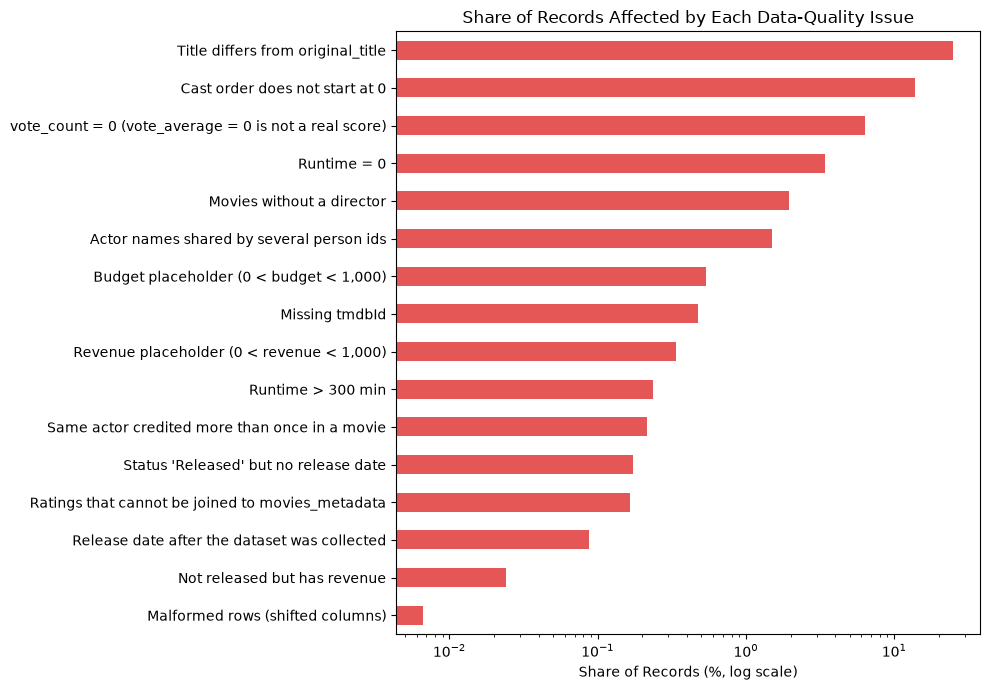

In [ ]:
ax = quality_checks.set_index("Check")["Share (%)"].loc[lambda shares: shares > 0].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    logx=True,
    color="#E45756",
    title="Share of Records Affected by Each Data-Quality Issue"
)

ax.set_xlabel("Share of Records (%, log scale)")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(RESULT_FOLDER + "data_quality_issues.png", bbox_inches="tight")
plt.show()

**Findings:** Most issues affect less than 1 % of the records, but some affect more and directly affect analysis results: missing votes (6.4 %), the cast order (13.9 %) and runtime 0 (3.4 %). A differing `title` and `original_title` (25 %) is expected for foreign movies and is not an error. The queries should use `title` consistently.

## 21. Outlier Detection

Outliers are detected with the IQR rule (1.5 · IQR outside Q1/Q3) on known values only. Budget, revenue, vote count and ratings per user span several orders of magnitude, so their fences are computed on the log10 scale; otherwise almost every blockbuster would be flagged.

In [ ]:
outlier_summary = {}

### 21.1 Runtime

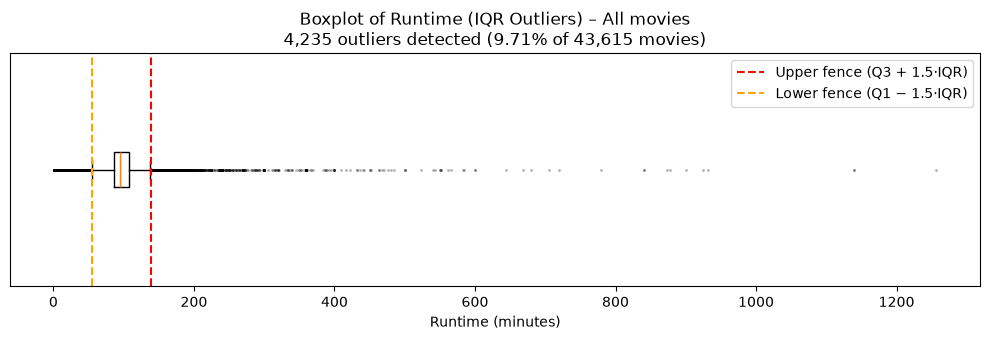

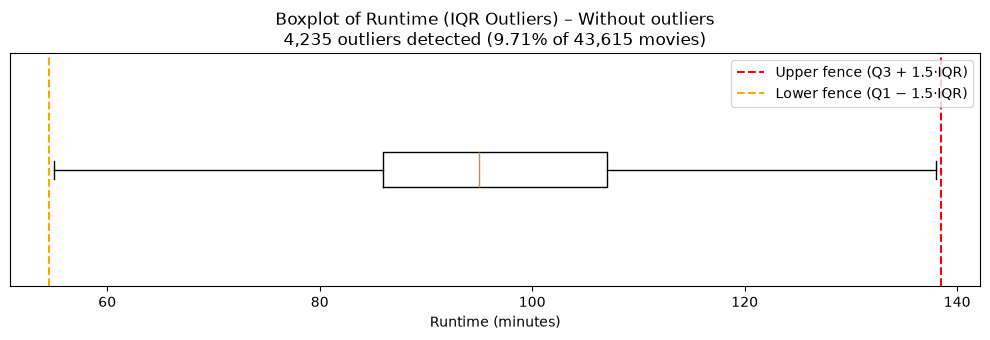

,title,release_year,runtime,genre_names
24159,Centennial,1978,1256.0,"[Drama, History]"
19954,Jazz,2001,1140.0,[Documentary]
40907,Baseball,1994,1140.0,[Documentary]
13760,Berlin Alexanderplatz,1980,931.0,[Drama]
13946,Heimat: A Chronicle of Germany,1984,925.0,"[Drama, History]"


In [ ]:
outlier_summary["Runtime (min)"] = plot_outlier_boxplot(
    movies["runtime"][movies["runtime"] > 0],
    title="Boxplot of Runtime (IQR Outliers)",
    xlabel="Runtime (minutes)",
    output_path=RESULT_FOLDER + "runtime_boxplot.png"
)

display(movies.nlargest(5, "runtime")[["title", "release_year", "runtime", "genre_names"]])

### 21.2 Budget and Revenue

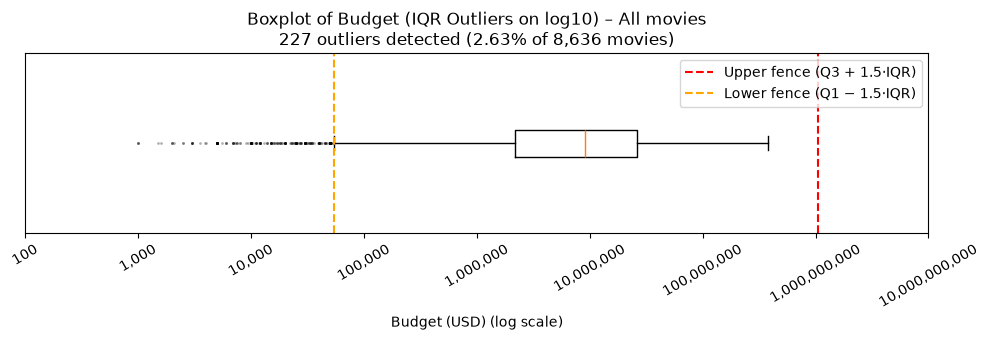

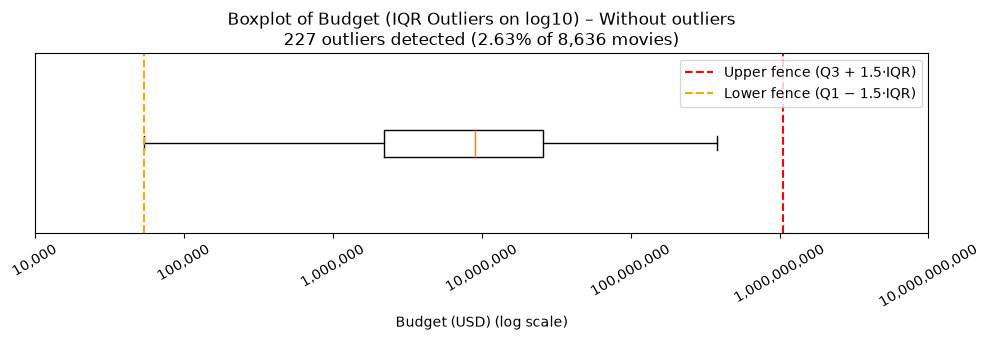

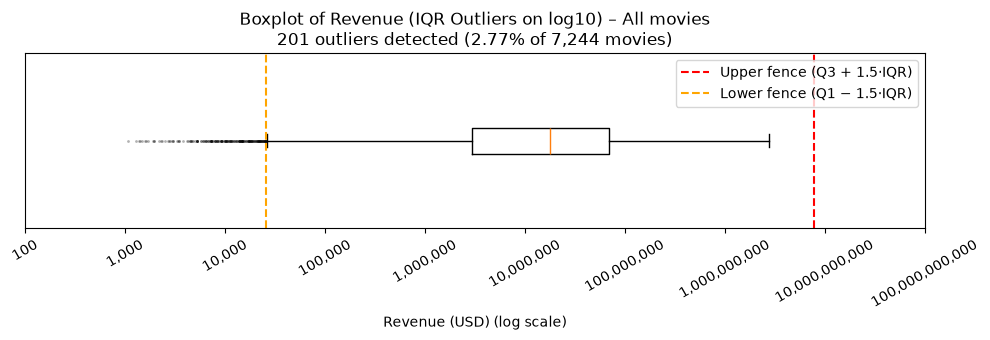

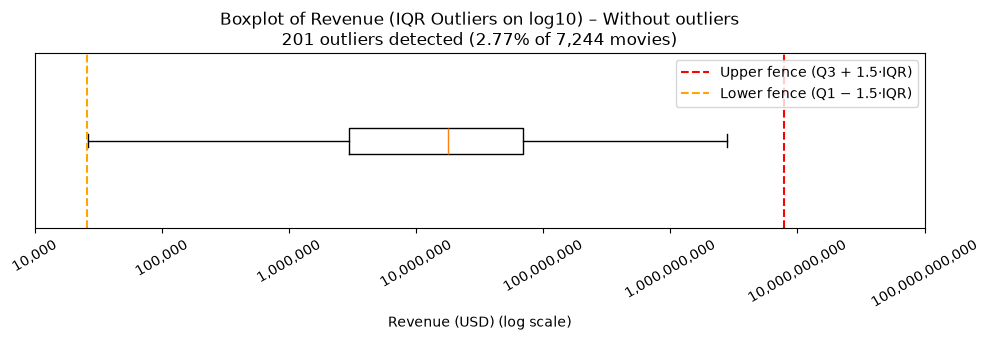

,title,release_year,budget,revenue
27671,Dark Dungeons,2014,1000,0.0
31853,One Minute Time Machine,2014,1000,0.0
43253,I Am Self-Sufficient,1976,1000,0.0
44229,The Final Sacrifice,1990,1500,0.0
27492,Within the Woods,1978,1600,0.0


In [ ]:
outlier_summary["Budget (USD)"] = plot_outlier_boxplot(
    movies["budget_usd"].dropna(),
    title="Boxplot of Budget (IQR Outliers on log10)",
    xlabel="Budget (USD)",
    output_path=RESULT_FOLDER + "budget_boxplot.png",
    log_scale=True
)

outlier_summary["Revenue (USD)"] = plot_outlier_boxplot(
    movies["revenue_usd"].dropna(),
    title="Boxplot of Revenue (IQR Outliers on log10)",
    xlabel="Revenue (USD)",
    output_path=RESULT_FOLDER + "revenue_boxplot.png",
    log_scale=True
)

display(movies.nsmallest(5, "budget_usd")[["title", "release_year", "budget", "revenue"]])

In [ ]:
known_money = known_money.assign(revenue_to_budget=known_money["revenue_usd"] / known_money["budget_usd"])
display(
    known_money.nlargest(8, "revenue_to_budget")[["title", "release_year", "budget", "revenue", "revenue_to_budget"]]
    .round(1)
)

,title,release_year,budget,revenue,revenue_to_budget
14185,Paranormal Activity,2007,15000,193355800.0,12890.4
2594,The Blair Witch Project,1999,60000,248000000.0,4133.3
41441,The Tiger: An Old Hunter's Tale,2015,5000,11083449.0,2216.7
3553,Eraserhead,1977,10000,7000000.0,700.0
4314,The Way of the Dragon,1972,130000,85000000.0,653.8
2247,Pink Flamingos,1972,12000,6000000.0,500.0
7785,Super Size Me,2004,65000,28575078.0,439.6
31603,The Gallows,2015,100000,42664410.0,426.6


### 21.3 Vote Count and Ratings per User

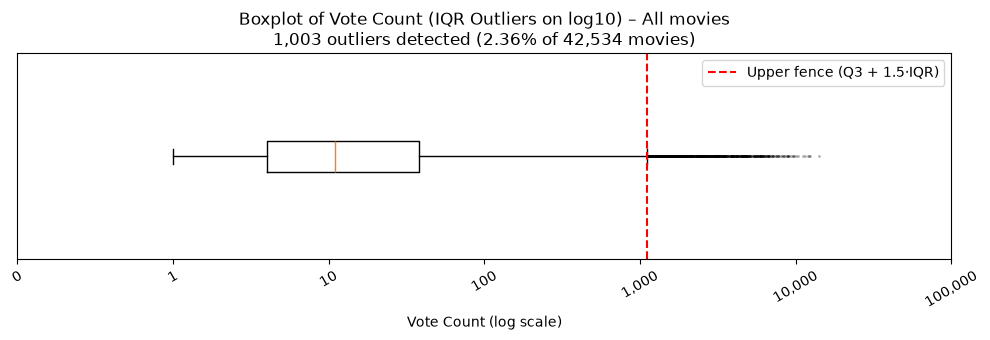

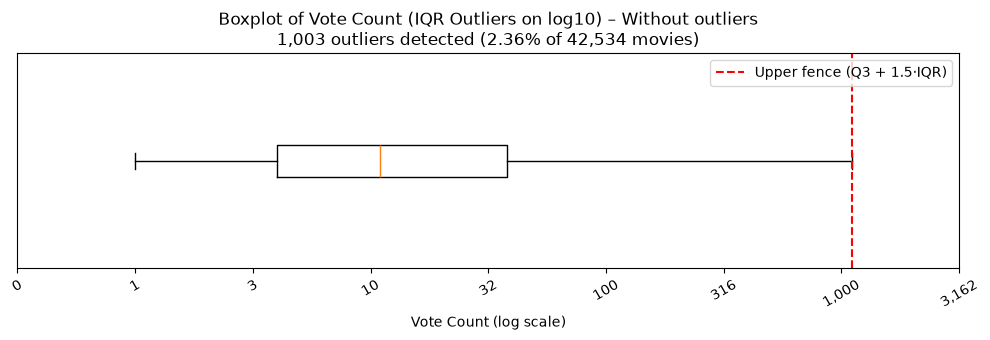

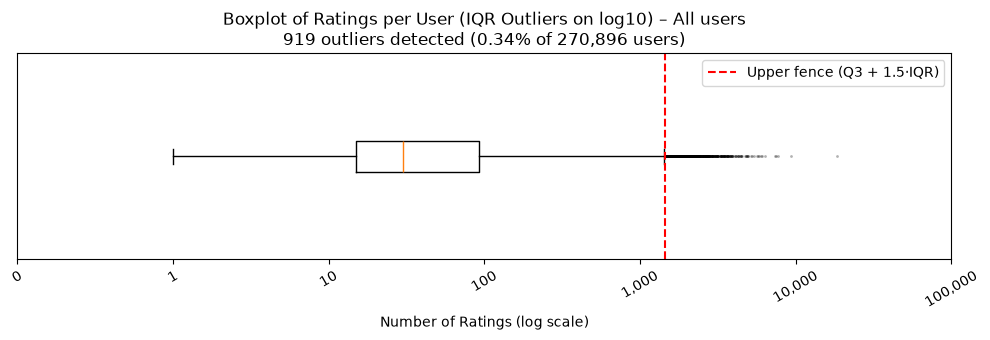

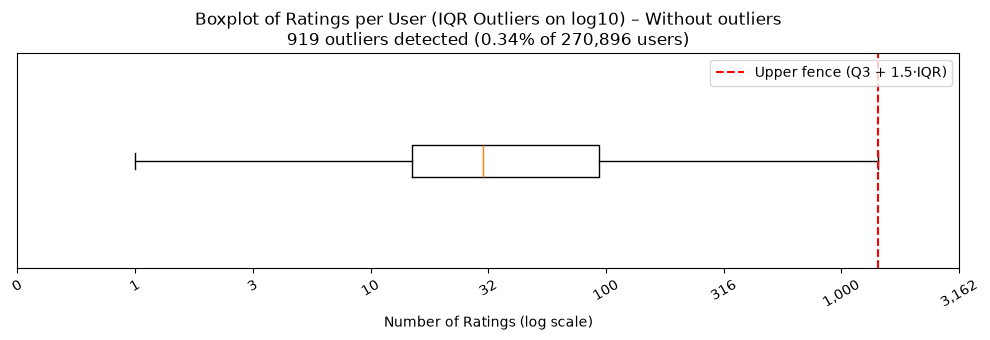

In [ ]:
outlier_summary["Vote count"] = plot_outlier_boxplot(
    voted["vote_count"],
    title="Boxplot of Vote Count (IQR Outliers on log10)",
    xlabel="Vote Count",
    output_path=RESULT_FOLDER + "vote_count_boxplot.png",
    log_scale=True
)

outlier_summary["Ratings per user"] = plot_outlier_boxplot(
    ratings_per_user,
    title="Boxplot of Ratings per User (IQR Outliers on log10)",
    xlabel="Number of Ratings",
    output_path=RESULT_FOLDER + "ratings_per_user_boxplot.png",
    unit="users",
    log_scale=True
)

In [ ]:
display(pd.DataFrame(outlier_summary).T.round(2))

,Q1,Q3,IQR,Lower fence,Upper fence,Outliers below,Outliers above,Total outliers,Outlier share (%)
Runtime (min),86.00,107.00,21.0,54.50,1.385000e+02,2055.0,2180.0,4235.0,9.71
Budget (USD),2200000.00,26000000.00,23800000.0,54149.78,1.056329e+09,227.0,0.0,227.0,2.63
Revenue (USD),2953374.34,69333245.84,66379871.5,25964.74,7.886351e+09,201.0,0.0,201.0,2.77
Vote count,4.00,38.00,34.0,0.14,1.112680e+03,0.0,1003.0,1003.0,2.36
Ratings per user,15.00,93.00,78.0,0.97,1.435720e+03,0.0,919.0,919.0,0.34


**Findings:**

- Using the standard 1.5 · IQR rule, runtime flags 9.7 % of the movies, including normal short films below 55 minutes. The outliers above 300 minutes are series rather than errors in the data.
- On the log scale, budget and revenue only have outliers at the **low** end (e.g. budgets of 1,000 USD for amateur films), together with the placeholder values. The huge revenue-to-budget ratios are a mix of real low-budget successes (*Paranormal Activity*, *The Blair Witch Project*) and probably mis-entered budgets.
- Vote count and ratings per user only have high outliers. These are popular movies and very active users, which are valid and should be kept.

Outliers are therefore **not removed**. Only values that are clearly invalid (0, placeholders and undefined averages) are turned into missing values.

## 22. Summary of Findings

**Structure.** The dataset consists of three TMDB-keyed movie files (metadata, credits, keywords) and the MovieLens ratings, which can only be joined to movies through `links.csv`. Nested fields are stored as Python-literal strings and parse without errors once three malformed rows are removed. The natural MongoDB design is one document per movie (TMDB id as `_id`) with genres, companies, countries, collection, keywords and a trimmed cast/crew embedded, plus a separate ratings collection that references the movie, since 26 million ratings cannot be embedded.

**Content.** The dataset is dominated by recent (53 % after 2000), English-language (71 %), US-produced movies, with Drama and Comedy as the main genres. Votes and ratings are concentrated on a small number of popular movies and very active users.

**Trends over time.** The studio era (1930s–1950s) stands out in every perspective: a few studios produced many movies each, the same supporting actors appeared in dozens of films, and casts were largest. Since the 1960s the industry has become more fragmented and international, with many small companies, more languages and stable runtimes of about 95–100 minutes. Keywords reflect changing genres and topics, from silent film and film noir to the 1970s exploitation themes and the rise of "woman director" and post-credits scenes.

**Data quality.** Missing information is mostly implicit (0, empty lists, placeholders). Revenue is only known for 16 % of the movies and gender for 60 % of the cast credits, so statistics on these fields cover a biased subset.

**Cleaning decisions for `insert.py`:**

| Issue | Handling |
|---|---|
| 3 malformed rows with shifted columns | Remove |
| Repeated ids in metadata, credits and keywords | Keep one document per TMDB id (highest `vote_count`) |
| Budget/revenue of 0 or < 1,000 USD | Store as missing |
| Runtime 0, `vote_average` without votes | Store as missing |
| Release dates in the future / missing | Keep as missing date |
| Empty nested lists | Store as empty arrays (or omit), never as placeholders |
| Repeated actor in a movie, shared names | Use distinct person ids per movie |
| Cast order not starting at 0 | Sort by `order` to find the top-billed cast |
| Ratings without a matching movie | Keep, but they cannot be linked to movie attributes |
| Two MovieLens ids for one TMDB id | Map both to the same movie |
| Unix timestamps | Convert to dates |